# Lezione 10 — Caso TakeHome: Lehman Brothers 2008: rischio sistemico, migrazioni creditizie e perdita di portafoglio

> **Specifica vincolante:** la Scheda Caso costituisce la specifica vincolante del lavoro. Variabili, stati, parametri, formule, ipotesi, output e controlli in essa indicati non devono essere modificati durante lo svolgimento.

## 1. Contesto, domanda quantitativa, variabile finale e informazione disponibile

### Contesto del caso

Il caso si colloca nel giugno 2008, in una fase di crescente tensione del sistema finanziario internazionale e di deterioramento del merito creditizio di Lehman Brothers, nell'ambito dell'insegnamento *Metodi Quantitativi per la Finanza* (Lezione 10 — Applicazione in Python: rischio di credito).

Si considera un portafoglio di esposizioni creditizie verso $40$ debitori appartenenti a diverse classi di rating, nel quale la posizione verso Lehman Brothers presenta un investimento iniziale significativamente superiore a quello delle singole altre posizioni. Il rischio creditizio del portafoglio è guidato congiuntamente dall'evoluzione individuale del rating dei debitori e da un regime sistemico comune che evolve nel tempo secondo una catena di Markov trimestrale.

Al portafoglio concentrato viene affiancato un portafoglio controfattuale in cui la posizione Lehman Brothers viene eliminata e il relativo investimento iniziale ($25$ milioni di dollari) viene riallocato proporzionalmente tra gli altri $39$ debitori, mantenendo invariato l'investimento complessivo del portafoglio e utilizzando le medesime repliche Monte Carlo sottostanti.

### Domanda quantitativa

Quale distribuzione della perdita a un anno produce il portafoglio concentrato e come cambiano perdita attesa, dispersione, VaR e CVaR quando l'investimento inizialmente concentrato su Lehman Brothers viene riallocato proporzionalmente tra gli altri debitori, a investimento complessivo invariato?

### Variabile finale

La variabile finale è la perdita di portafoglio su orizzonte annuale ($T = 4$ trimestri), espressa in milioni di dollari, valutata in ciascuna replica Monte Carlo $r$:

- per il portafoglio concentrato:

$$
L_{\mathrm{conc}}^{P,(r)} = \sum_{i=1}^{40} L_i^{(r)}
$$

- per il portafoglio controfattuale:

$$
L_{\mathrm{div}}^{P,(r)} = \sum_{i \neq L} V_{i,0}^{\mathrm{div}} \, \varphi\!\left(X_{i,0}, X_{i,4}^{(r)}\right)
$$

dove la perdita individuale di ciascun debitore è definita come

$$
L_i = V_{i,0} \, \varphi(X_{i,0}, X_{i,4})
$$

Unitamente alle perdite dei due portafogli, si considera la differenza replica per replica:

$$
\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}
$$

### Informazione disponibile

- **Processo di regime sistemico:** catena di Markov omogenea trimestrale $\{M_t\}_{t=0}^{3}$ con spazio degli stati $\mathcal{M} = \{O, S, C\}$ (condizioni ordinarie, stress finanziario, crisi), stato iniziale $M_0 = S$ e matrice di transizione trimestrale $Q$ assegnata.

- **Processo di migrazione creditizia:** evoluzione trimestrale del rating $\{X_{i,t}\}_{t=0}^{4}$ per ciascun debitore sullo spazio degli stati $\mathcal{I} = \{A, BBB, BB, B, D\}$, con stato di default $D$ assorbente, governata dalle matrici di migrazione regime-dipendenti $P^{(O)}$, $P^{(S)}$ e $P^{(C)}$ assegnate, tali che $\mathbb{P}(X_{i,t+1} = j \mid X_{i,t} = k, M_t = m) = p_{kj}^{(m)}$.

- **Struttura di dipendenza:** condizionatamente alla traiettoria sistemica comune $(M_0, M_1, M_2, M_3)$, le migrazioni dei diversi debitori sono indipendenti; incondizionatamente risultano dipendenti attraverso il regime sistemico comune. Nel confronto controfattuale le repliche condividono la stessa traiettoria sistemica e le stesse traiettorie creditizie per i $39$ debitori comuni, mentre la traiettoria Lehman entra soltanto nel portafoglio concentrato.

- **Grandezze di perdita:** nel caso didattico si assume $\mathrm{EAD}_i = V_{i,0}$ e $\mathrm{LGD} = 0.65$ costante; la matrice dei tassi di perdita *migration-based* $\varphi(r_0, r_4)$ è assegnata, include il default tramite $\varphi(r_0, D) = 0.65$ e attribuisce valori negativi agli incrementi di valore derivanti da miglioramenti di rating.

- **Portafoglio iniziale concentrato (milioni di dollari):** $40$ debitori per un investimento complessivo $V_0^{P,\mathrm{conc}} = 173$, così suddivisi: Lehman Brothers ($1$ debitore A, $25$), altri debitori A ($11$ debitori, $5$ ciascuno, totale $55$), debitori BBB ($14$ debitori, $4$ ciascuno, totale $56$), debitori BB ($9$ debitori, $3$ ciascuno, totale $27$), debitori B ($5$ debitori, $2$ ciascuno, totale $10$).

- **Portafoglio controfattuale (milioni di dollari):** $39$ debitori ottenuti eliminando Lehman Brothers e riscalando proporzionalmente gli investimenti residui ($148$) tramite il fattore $173/148 \approx 1.168919$, così che $V_{i,0}^{\mathrm{div}} = V_{i,0} \cdot \frac{173}{148}$ per ogni $i \neq L$ e $V_0^{P,\mathrm{div}} = 173$.

- **Parametri computazionali:** numero di repliche Monte Carlo $N_{\mathrm{MC}} = 50\,000$, seed $= 2026$, orizzonte $T = 4$ trimestri (un anno).

- **Ipotesi e limiti assegnati:** probabilità fisiche, matrici omogenee per regime, investimenti iniziali e LGD deterministici, calibrazione didattica non rappresentativa di stime storiche del 2008, assenza di effetti di contagio diretto, liquidità e strumenti di copertura; la riallocazione proporzionale modifica anche la composizione dell'investimento tra classi di rating.

## 2. Quantità da stimare o calcolare

### Quantità per il portafoglio concentrato e per il portafoglio controfattuale

1. Perdita media:

$$
\mathbb{E}[L^P]
$$

2. Varianza:

$$
\operatorname{Var}(L^P)
$$

3. Deviazione standard.

4. Value at Risk ai livelli $95\%$ e $99\%$:

$$
\operatorname{VaR}_{0,95}(L^P), \qquad \operatorname{VaR}_{0,99}(L^P)
$$

5. Conditional Value at Risk ai livelli $95\%$ e $99\%$, calcolato secondo la definizione mediante quantili adottata nel Capitolo 9:

$$
\operatorname{CVaR}_{0,95}(L^P), \qquad \operatorname{CVaR}_{0,99}(L^P)
$$

### Ulteriori quantità relative al regime sistemico e al confronto tra portafogli

6. Probabilità che il regime $C$ venga raggiunto almeno una volta durante l'orizzonte.

7. Perdita media del portafoglio concentrato:
   - nelle repliche nelle quali il regime $C$ viene raggiunto almeno una volta;
   - nelle repliche nelle quali il regime $C$ non viene mai raggiunto.

8. Per ciascuna misura di rischio $\rho$, la variazione:

$$
\Delta\rho = \rho(L_{\mathrm{div}}^P) - \rho(L_{\mathrm{conc}}^P)
$$

9. La differenza replica per replica:

$$
\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}
$$

## 3. Output richiesti

### 6.1 Risultati numerici

Per entrambi i portafogli (concentrato e controfattuale):

- distribuzione simulata della perdita;
- perdita media;
- varianza;
- deviazione standard;
- VaR 95%;
- CVaR 95%;
- VaR 99%;
- CVaR 99%.

Risultati aggiuntivi:

- differenze tra le misure di rischio dei due portafogli;
- probabilità simulata che il regime $C$ venga raggiunto almeno una volta;
- perdita media del portafoglio concentrato nelle repliche con e senza ingresso nello stato $C$;
- distribuzione empirica di $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$.

### 6.2 Tabelle

- **Tabella 1 — Portafoglio iniziale concentrato:** rating iniziale, numero di debitori, investimento individuale e investimento complessivo.
- **Tabella 2 — Portafoglio controfattuale:** rating iniziale, numero di debitori, investimento individuale riallocato e investimento complessivo.
- **Tabella 3 — Misure di rischio:** confronto tra portafoglio concentrato, portafoglio con riallocazione proporzionale e differenza tra le rispettive misure.
- **Tabella 4 — Regime sistemico e perdita:** confronto, per il portafoglio concentrato, tra repliche con e senza ingresso nello stato $C$.

### 6.3 Grafici

- **Figura 1 — Distribuzione della perdita del portafoglio concentrato:** distribuzione empirica di $L_{\mathrm{conc}}^P$ con indicazione di VaR 95% e VaR 99%.
- **Figura 2 — Confronto delle distribuzioni:** confronto tra le distribuzioni empiriche delle perdite del portafoglio concentrato e del portafoglio controfattuale, con particolare attenzione alla coda destra.
- **Figura 3 — Regime sistemico e perdita:** confronto delle perdite del portafoglio concentrato tra repliche nelle quali lo stato $C$ viene raggiunto almeno una volta e repliche nelle quali non viene mai raggiunto.

## 4. Controlli richiesti

### Controlli numerici

- **Controllo 1:** Verifica che ogni riga della matrice di transizione del regime sistemico $Q$ sommi a $1$.
- **Controllo 2:** Verifica che ogni riga delle matrici di migrazione creditizia $P^{(O)}$, $P^{(S)}$ e $P^{(C)}$ sommi a $1$.
- **Controllo 7:** Verifica che il portafoglio concentrato contenga esattamente $40$ debitori.
- **Controllo 8:** Verifica che il portafoglio controfattuale contenga esattamente $39$ debitori.
- **Controllo 9:** Verifica che l'investimento iniziale complessivo sia pari a $173$ milioni di dollari in entrambi i portafogli ($V_0^{P,\mathrm{conc}} = V_0^{P,\mathrm{div}} = 173$).
- **Controllo 10:** Verifica che le proporzioni relative degli investimenti dei $39$ debitori residui rimangano inalterate dopo la riallocazione proporzionale.
- **Controllo 12:** Verifica che la perdita totale di ciascun portafoglio coincida con la somma delle rispettive perdite individuali.
- **Controllo 14:** Verifica che VaR e CVaR siano calcolati sulle distribuzioni empiriche delle perdite monetarie, espresse in milioni di dollari.
- **Controllo 15:** Verifica che le principali misure di rischio mostrino una ragionevole stabilità al crescere del numero di repliche simulate.

### Controlli logici o teorici

- **Controllo 3:** Verifica che lo stato $D$ sia assorbente in tutte le matrici di migrazione creditizia ($p_{DD}^{(m)} = 1$).
- **Controllo 4:** Verifica che tutti gli stati simulati appartengano agli insiemi definiti ($\mathcal{M} = \{O, S, C\}$ e $\mathcal{I} = \{A, BBB, BB, B, D\}$).
- **Controllo 5:** Verifica che, all'interno della stessa replica Monte Carlo, esista un'unica traiettoria sistemica comune a tutti i debitori.
- **Controllo 6:** Verifica che, condizionatamente alla traiettoria sistemica comune, i debitori utilizzino estrazioni casuali individuali e indipendenti.

### Controlli computazionali

- **Controllo 11:** Verifica che i $39$ debitori comuni utilizzino esattamente le stesse traiettorie creditizie nei due portafogli.
- **Controllo 13:** Verifica che il seed assegnato, pari a $2026$, sia impostato correttamente come condizione per la riproducibilità della simulazione.

# Flusso logico-teorico risolutivo — Caso Lehman Brothers 2008

## Verifica della sequenza teorica proposta

### 1. Coerenza dell'ordine logico e copertura di output e controlli

L'ordine logico proposto nei Passi 1–11 è **complessivamente coerente e progressivo**: definisce prima la struttura deterministica dei due portafogli (Passo 1), descrive poi la dinamica probabilistica su una singola replica $r$ — regime sistemico comune, matrici regime-dipendenti, migrazioni condizionatamente indipendenti, funzione di perdita individuale e aggregazione accoppiata (Passi 2–6) — passa quindi alla simulazione Monte Carlo sulle $N_{\mathrm{MC}}$ repliche (Passo 7), alla stima delle misure di rischio (Passo 8), all'analisi condizionata al regime di crisi (Passo 9), al confronto controfattuale (Passo 10) e infine all'inquadramento entro le ipotesi e i limiti del modello (Passo 11).

Tutti gli output numerici (Sez. 6.1), le quattro tabelle (Sez. 6.2), le tre figure (Sez. 6.3) e tutti i quindici controlli (Sez. 7) della Scheda Caso risultano integralmente collegabili alla sequenza, previa integrazione delle precisazioni riportate sotto.

### 2. Elementi mancanti, precisazioni, ridondanze e ordine

- **Elementi teorici mancanti o da completare:**
  - *Validazione stocastica della matrice $Q$ (Controllo 1):* al Passo 2 va aggiunta la verifica che ogni riga della matrice di transizione sistemica $Q$ sia non negativa e sommi a $1$, analogamente a quanto previsto al Passo 3 per $P^{(O)}, P^{(S)}, P^{(C)}$.
  - *Verifica di appartenenza agli spazi degli stati (Controllo 4):* nei Passi 2 e 4 occorre esplicitare la verifica che tutti gli stati simulati appartengano rispettivamente a $\mathcal{M} = \{O, S, C\}$ e a $\mathcal{I} = \{A, BBB, BB, B, D\}$.
  - *Formalizzazione dell'evento di ingresso in crisi $A_C$:* al Passo 9 va formalizzato l'evento $A_C = \{\exists\, t \in \{0,1,2,3\} : M_t = C\} = \{\exists\, t \in \{1,2,3\} : M_t = C\}$ (essendo $M_0 = S$ deterministico) e precisato che le perdite medie richieste sono valori attesi condizionati, $\mathbb{E}[L_{\mathrm{conc}}^P \mid A_C]$ e $\mathbb{E}[L_{\mathrm{conc}}^P \mid A_C^c]$.
  - *Definizione formale di VaR e CVaR mediante quantili:* al Passo 8 conviene esplicitare le definizioni formali di $\operatorname{VaR}_\alpha$ e di $\operatorname{CVaR}_\alpha$ come media dei quantili in coda (secondo la formulazione del Capitolo 9), rilevante in presenza di distribuzioni empiriche discrete o con masse di probabilità concentrate.
  - *Funzione metodologica della condivisione delle traiettorie:* al Passo 6 va esplicitato che l'uso delle medesime traiettorie sistemiche e creditizie per i $39$ debitori comuni (tecnica delle variabili casuali comuni) riduce l'errore di campionamento Monte Carlo nel confronto tra i due portafogli.
  - *Aggancio esplicito a tabelle e figure:* i collegamenti puntuali a Tabelle 1–4 e Figure 1–3 non erano ancora esplicitati nella bozza e sono completati nella tabella sottostante.

- **Elementi ridondanti:** non risultano ridondanze sostanziali tra gli 11 passi; ciascuno copre un blocco teorico distinto.

- **Precisazioni sull'ordine:** la scelta di descrivere la struttura probabilistica della singola replica $r$ (Passi 2–6) prima dell'estensione a $N_{\mathrm{MC}} = 50\,000$ repliche (Passo 7) è didatticamente chiara e logicamente ammissibile. Si segnala soltanto che:
  - le verifiche statiche sulle matrici ($Q$, $P^{(m)}$, stato assorbente $D$) precedono concettualmente la simulazione delle transizioni nei rispettivi passi;
  - la fissazione del seed ($2026$, Controllo 13) è un prerequisito operativo dell'intera simulazione Monte Carlo (Passo 7), mentre la verifica di stabilità al crescere di $N_{\mathrm{MC}}$ (Controllo 15) va mantenuta distinta e riferita alle misure di rischio stimate (Passo 8), come già correttamente impostato;
  - il Passo 11 non introduce nuovi calcoli ma delimita il perimetro interpretativo entro le ipotesi della Sezione 8 della Scheda Caso.

### 3. Risposta ai quesiti teorici specifici

- **Sufficienza di $(X_{i,0}, X_{i,4})$ con default assorbente e LGD costante:** la formulazione è **corretta**. Poiché $D$ è assorbente ($p_{DD}^{(m)} = 1$ per ogni $m \in \{O, S, C\}$), l'ingresso in default in un qualsiasi trimestre $\tau \in \{1, 2, 3, 4\}$ implica necessariamente $X_{i,4} = D$; reciprocamente, poiché tutti i debitori partono da classi non in default, $X_{i,4} = D$ equivale al verificarsi del default entro l'orizzonte annuale. Essendo inoltre $\mathrm{EAD}_i = V_{i,0}$ deterministica e costante, $\mathrm{LGD} = 0.65$ costante e $\varphi(r_0, D) = 0.65$ indipendente dal trimestre di default (senza attualizzazione o flussi intermedi), la perdita individuale dipende solo dalla coppia $(X_{i,0}, X_{i,4})$. Restano naturalmente necessari tutti i quattro passaggi trimestrali per generare correttamente la distribuzione di $X_{i,4}$ sotto la dinamica del regime sistemico.

- **Distinzione tra $\Delta L^{(r)}$ e $\Delta \rho$:** la distinzione è **formulata correttamente ed è teoricamente indispensabile**. La grandezza $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$ è una **variabile casuale** che misura l'effetto della riallocazione scenario per scenario a parità di traiettorie sottostanti; al contrario, $\Delta \rho = \rho(L_{\mathrm{div}}^P) - \rho(L_{\mathrm{conc}}^P)$ è una **differenza scalare** tra la stessa misura di rischio applicata separatamente alle due distribuzioni marginali di perdita. Solo per la perdita media vale la linearità $\mathbb{E}[\Delta L] = \mathbb{E}[L_{\mathrm{div}}^P] - \mathbb{E}[L_{\mathrm{conc}}^P]$; per le misure non lineari (varianza, deviazione standard, $\operatorname{VaR}_\alpha$, $\operatorname{CVaR}_\alpha$), in generale $\rho(\Delta L) \neq \rho(L_{\mathrm{div}}^P) - \rho(L_{\mathrm{conc}}^P)$.

---

## Sequenza teorica verificata, completata e ordinata

| Passo | Finalità risolutiva | Formula, definizione, proprietà o teorema | Applicazione nel caso | Output o controllo collegato |
|---:|---|---|---|---|
| 1 | Definire la struttura deterministica dei due portafogli creditizi e verificare l'invarianza dell'investimento totale e delle proporzioni relative | $V_0^{P,\mathrm{conc}} = \sum_{i=1}^{40} V_{i,0}$; per ogni $i \neq L$, $V_{i,0}^{\mathrm{div}} = V_{i,0} + V_{L,0}\frac{V_{i,0}}{\sum_{j \neq L} V_{j,0}} = V_{i,0}\frac{V_0^{P,\mathrm{conc}}}{\sum_{j \neq L} V_{j,0}}$; invarianza dei rapporti $\frac{V_{i,0}^{\mathrm{div}}}{V_{j,0}^{\mathrm{div}}} = \frac{V_{i,0}}{V_{j,0}}$; semplificazione del caso $\mathrm{EAD}_i = V_{i,0}$ | Portafoglio concentrato: $40$ debitori (Lehman $25$ mln in A; $11$ A da $5$; $14$ BBB da $4$; $9$ BB da $3$; $5$ B da $2$), totale $173$ mln. Portafoglio controfattuale: eliminazione di Lehman e riscalamento dei $39$ debitori residui ($148$ mln) con fattore $\frac{173}{148} \approx 1.168919$, mantenendo $V_0^{P,\mathrm{div}} = 173$ mln (con conseguente variazione dei pesi per classe di rating) | **Tabella 1**, **Tabella 2**; **Controllo 7**, **Controllo 8**, **Controllo 9**, **Controllo 10** |
| 2 | Modellare il fattore sistemico comune come catena di Markov trimestrale omogenea sotto misura fisica e validarne la matrice di transizione | Processo $\{M_t\}_{t=0}^3$ su $\mathcal{M} = \{O, S, C\}$; proprietà di Markov omogenea $\mathbb{P}(M_{t+1} = m' \mid M_t = m, \mathcal{F}_t^M) = q_{mm'}$; matrice stocastica $Q = (q_{mm'})$ con $q_{mm'} \ge 0$ e $\sum_{m' \in \mathcal{M}} q_{mm'} = 1$ | Stato iniziale $M_0 = S$; applicazione della matrice trimestrale $Q$ assegnata per generare $(M_1, M_2, M_3)$ e ottenere un'unica traiettoria sistemica $(M_0, M_1, M_2, M_3)$ condivisa da tutti i debitori nella stessa replica $r$ | **Controllo 1**, **Controllo 4** (per $\mathcal{M}$), **Controllo 5** |
| 3 | Specificare lo spazio degli stati creditizi e le matrici di migrazione regime-dipendenti, verificandone validità stocastica e assorbenza del default | Spazio $\mathcal{I} = \{A, BBB, BB, B, D\}$; legge di transizione condizionata $\mathbb{P}(X_{i,t+1} = j \mid X_{i,t} = k, M_t = m) = p_{kj}^{(m)}$; matrici stocastiche $P^{(m)}$ con $p_{kj}^{(m)} \ge 0$ e $\sum_{j \in \mathcal{I}} p_{kj}^{(m)} = 1$; stato $D$ assorbente ($p_{DD}^{(m)} = 1$, $p_{Dj}^{(m)} = 0$ per $j \neq D$) | Associazione delle matrici assegnate $P^{(O)}, P^{(S)}, P^{(C)}$ alle quattro transizioni trimestrali $t \to t+1$ ($t = 0, 1, 2, 3$) governate dai regimi $(M_0, M_1, M_2, M_3)$, omogenee per debitore a parità di rating corrente e regime | **Controllo 2**, **Controllo 3** |
| 4 | Generare le traiettorie individuali di rating sfruttando l'indipendenza condizionata e inducendo dipendenza incondizionata tramite il fattore sistemico | Indipendenza condizionata: $\mathbb{P}\!\left(\bigcap_{i=1}^{40} \{X_{i,t+1} = j_i\} \mid \{X_{i,t}\}, M_t = m\right) = \prod_{i=1}^{40} p_{X_{i,t}, j_i}^{(m)}$; dipendenza incondizionata delle perdite generata dall'esposizione al processo comune $\{M_t\}_{t=0}^3$ | Per ciascuna replica $r$ e trimestre $t = 0, 1, 2, 3$, estrazione individuale e indipendente del nuovo rating $X_{i,t+1}^{(r)}$ per ogni debitore $i$ dalla riga $X_{i,t}^{(r)}$ della matrice $P^{(M_t^{(r)})}$, fino allo stato terminale $X_{i,4}^{(r)}$ | **Controllo 4** (per $\mathcal{I}$), **Controllo 6** |
| 5 | Trasformare la migrazione annuale individuale in perdita monetaria *migration-based* includendo il default | $L_i^{(r)} = V_{i,0}\,\varphi\!\left(X_{i,0}, X_{i,4}^{(r)}\right)$ (e $L_i^{\mathrm{div},(r)} = V_{i,0}^{\mathrm{div}}\,\varphi\!\left(X_{i,0}, X_{i,4}^{(r)}\right)$ per $i \neq L$); con $\mathrm{EAD}_i = V_{i,0}$, $\mathrm{LGD} = 0.65$ costante, $D$ assorbente e $\varphi(r_0, D) = 0.65$, la perdita dipende solo da $(X_{i,0}, X_{i,4}^{(r)})$ e non dal trimestre di default | Applicazione della tabella $\varphi(r_0, r_4)$ assegnata alle coppie $(X_{i,0}, X_{i,4}^{(r)})$ in milioni di dollari, includendo sia le perdite da downgrade e default ($\varphi > 0$) sia gli incrementi di valore da upgrade ($\varphi < 0$) | Perdite individuali $L_i^{(r)}$ e $L_i^{\mathrm{div},(r)}$ (base per **Controllo 12** e **Controllo 14**) |
| 6 | Aggregare le perdite individuali nei due portafogli sulle stesse traiettorie sottostanti e definire la differenza replica per replica | $L_{\mathrm{conc}}^{P,(r)} = \sum_{i=1}^{40} L_i^{(r)}$; $L_{\mathrm{div}}^{P,(r)} = \sum_{i \neq L} V_{i,0}^{\mathrm{div}}\,\varphi\!\left(X_{i,0}, X_{i,4}^{(r)}\right)$; differenza accoppiata $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$ (metodo delle variabili casuali comuni per ridurre la varianza del confronto) | Calcolo nella medesima replica $r$ di $L_{\mathrm{conc}}^{P,(r)}$, $L_{\mathrm{div}}^{P,(r)}$ e $\Delta L^{(r)}$ utilizzando la stessa traiettoria sistemica, le stesse traiettorie creditizie per i $39$ debitori comuni e includendo Lehman solo nel portafoglio concentrato | **Controllo 11**, **Controllo 12** |
| 7 | Costruire le distribuzioni empiriche tramite simulazione Monte Carlo riproducibile sull'orizzonte annuale | Generazione di $N_{\mathrm{MC}}$ repliche i.i.d. della coppia $(L_{\mathrm{conc}}^{P,(r)}, L_{\mathrm{div}}^{P,(r)})$ e di $\Delta L^{(r)}$; legge dei grandi numeri e convergenza della funzione di ripartizione empirica $\hat{F}_N(x) = \frac{1}{N_{\mathrm{MC}}} \sum_{r=1}^{N_{\mathrm{MC}}} \mathbf{1}_{\{L^{(r)} \le x\}}$; distinzione tra riproducibilità (seed) e stabilità statistica (ampiezza campionaria) | Esecuzione di $N_{\mathrm{MC}} = 50\,000$ repliche su $T = 4$ trimestri fissando il seed $= 2026$, ottenendo le distribuzioni empiriche monetarie di $L_{\mathrm{conc}}^P$, $L_{\mathrm{div}}^P$ e $\Delta L$ | Risultati numerici (Sez. 6.1): distribuzioni simulate di $L_{\mathrm{conc}}^P$, $L_{\mathrm{div}}^P$ e $\Delta L^{(r)}$; **Controllo 13** |
| 8 | Stimare le misure di posizione, dispersione e coda sulle distribuzioni empiriche monetarie e verificarne la stabilità | Media empirica $\widehat{\mathbb{E}}[L^P]$, varianza $\widehat{\operatorname{Var}}(L^P)$, deviazione standard $\widehat{\operatorname{SD}}(L^P) = \sqrt{\widehat{\operatorname{Var}}(L^P)}$; $\operatorname{VaR}_\alpha(L) = q_\alpha(L) = \inf\{x \in \mathbb{R} : F_L(x) \ge \alpha\}$; $\operatorname{CVaR}_\alpha(L) = \frac{1}{1-\alpha} \int_\alpha^1 q_u(L)\,du$ (definizione mediante quantili del Capitolo 9) | Stima, in milioni di dollari per entrambi i portafogli, di perdita media, varianza, deviazione standard, $\operatorname{VaR}_{0.95}$, $\operatorname{CVaR}_{0.95}$, $\operatorname{VaR}_{0.99}$ e $\operatorname{CVaR}_{0.99}$; analisi della stabilità delle principali misure al crescere del numero di repliche | Risultati numerici (Sez. 6.1): statistiche e misure di rischio dei due portafogli; **Figura 1**; **Controllo 14**, **Controllo 15** |
| 9 | Valutare l'incidenza del regime di crisi $C$ e il suo impatto sulla perdita del portafoglio concentrato | Evento $A_C = \{\exists\, t \in \{0,1,2,3\} : M_t = C\} = \{\exists\, t \in \{1,2,3\} : M_t = C\}$; probabilità $\mathbb{P}(A_C)$ stimata dalla frequenza relativa delle repliche con ingresso in $C$; medie condizionate $\mathbb{E}[L_{\mathrm{conc}}^P \mid A_C]$ e $\mathbb{E}[L_{\mathrm{conc}}^P \mid A_C^c]$ | Partizione delle $50\,000$ repliche in traiettorie con almeno un ingresso nello stato $C$ e traiettorie che non raggiungono mai $C$; stima di $\mathbb{P}(A_C)$ e confronto delle perdite del portafoglio concentrato tra i due sottogruppi | Risultati numerici (Sez. 6.1): probabilità di ingresso in $C$ e perdite medie condizionate; **Tabella 4**, **Figura 3** |
| 10 | Confrontare il portafoglio concentrato e il portafoglio controfattuale in termini di misure di rischio, coda destra e differenze scenario per scenario | Variazione delle misure di rischio $\Delta \rho = \rho(L_{\mathrm{div}}^P) - \rho(L_{\mathrm{conc}}^P)$; confronto con la distribuzione empirica di $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$ (con $\mathbb{E}[\Delta L] = \Delta \mathbb{E}[L^P]$ per linearità, ma in generale $\rho(\Delta L) \neq \Delta \rho$ per varianza, deviazione standard, VaR e CVaR) | Calcolo di $\Delta \rho$ per tutte le misure stimate al Passo 8, analisi della distribuzione empirica di $\Delta L^{(r)}$ e confronto grafico delle due distribuzioni di perdita con attenzione alla coda destra | Risultati numerici (Sez. 6.1): differenze $\Delta \rho$ e sintesi di $\Delta L^{(r)}$; **Tabella 3**, **Figura 2** |
| 11 | Inquadrare i risultati quantitativi entro le ipotesi, le calibrazioni didattiche e i limiti del modello in relazione alla domanda quantitativa | Distinzione tra effetto puro di concentrazione ed effetto congiunto della riallocazione proporzionale (che modifica anche la composizione per classe di rating); probabilità fisiche, calibrazione didattica, assenza di contagio diretto, LGD/EAD stocastiche, rischio di liquidità e copertura | Raccordo dei risultati prodotti nei Passi 8–10 con la domanda quantitativa e i vincoli della Sezione 8 della Scheda Caso, senza estrapolazioni storiche o predittive sul default effettivo di Lehman Brothers | Raccordo metodologico con la domanda quantitativa e i limiti della Sezione 8 (base per la successiva interpretazione autonoma dello studente nella Fase 8) |

---

> **Validazione richiesta (Fase 4):** questo Flusso logico-teorico risolutivo costituisce una proposta verificata in Regime A. La decisione finale sulla sua validazione e su eventuali rettifiche prima di passare alla scomposizione del problema (Prompt 3) spetta allo studente.

# Scomposizione input-output del notebook — Caso Lehman Brothers 2008

## Verifica della scomposizione proposta

### 1. Coerenza con il Flusso logico-teorico risolutivo validato

La scomposizione proposta in 11 tappe **rispetta integralmente l'ordine logico** del Flusso logico-teorico risolutivo validato nella Fase 4, con una corrispondenza uno-a-uno tra Tappe 1–11 e Passi 1–11. Non emergono incoerenze tra il flusso validato e la sequenza operativa proposta.

### 2. Copertura di output, tabelle, figure e controlli della Scheda Caso

Tutti gli elementi vincolanti della Scheda Caso risultano associati ad almeno una tappa:

- **Risultati numerici (Sez. 6.1):** integralmente coperti tra le Tappe 7, 8, 9 e 10.
- **Tabelle (Sez. 6.2):** Tabella 1 e Tabella 2 (Tappa 1), Tabella 4 (Tappa 9), Tabella 3 (Tappa 10).
- **Figure (Sez. 6.3):** Figura 1 (Tappa 8), Figura 3 (Tappa 9), Figura 2 (Tappa 10).
- **Controlli (Sez. 7):** tutti i 15 controlli (Controlli 1–15) sono coperti senza omissioni.

### 3. Completamenti e precisazioni sui collegamenti input-output

Per rendere pienamente tracciabile il passaggio di oggetti da una tappa alla successiva nel notebook, nella tabella seguente sono stati integrati quattro accorgimenti operativi (senza modificare né la Scheda Caso né il Flusso validato):

1. **Output sistemici in Tappa 7 a servizio della Tappa 9:** oltre alle distribuzioni simulate di $L_{\mathrm{conc}}^{P}$, $L_{\mathrm{div}}^{P}$ e $\Delta L$, la Tappa 7 deve restituire e conservare le traiettorie sistemiche simulate $\{M_t^{(r)}\}_{t=0}^3$ (o l'indicatore di ingresso nello stato $C$ insieme alle traiettorie) perché costituiscono l'input indispensabile della Tappa 9 e dei Controlli 4 e 5 sull'intero campione.
2. **Doppia verifica tra procedura di singola replica (Tappe 2, 4, 6) ed esecuzione completa (Tappa 7):** i controlli statici su portafogli e matrici (Controlli 1, 2, 3, 7, 8, 9, 10) si esauriscono nelle Tappe 1–3; i controlli dinamici sulle traiettorie e sull'aggregazione (Controlli 4, 5, 6, 11, 12) vengono impostati e testati a livello di procedura nelle Tappe 2, 4 e 6 e poi verificati sull'intero insieme delle $50\,000$ repliche nella Tappa 7 (insieme al Controllo 13 sulla riproducibilità da `seed = 2026`).
3. **Controllo preparatorio sulla tabella $\varphi$ in Tappa 5:** poiché la Sezione 7 non assegna un controllo numerato autonomo alla tabella $\varphi(r_0, r_4)$, nella Tappa 5 si esplicita la verifica di coerenza della tabella inserita (dimensioni $4 \times 5$, $\varphi(r_0, D) = 0.65$, valori nulli sulla diagonale e negativi per gli upgrade), propedeutica ai Controlli 12 e 14.
4. **Controlli di coerenza integrativi proposti dallo studente:** vengono mantenuti come verifiche aggiuntive utili la legge della speranza totale in Tappa 9 e la linearità della media su $\Delta L^{(r)}$ in Tappa 10; la Tappa 11 resta una sintesi di tracciabilità (output, controlli e limiti di Sez. 8) propedeutica all'interpretazione critica che lo studente svolgerà autonomamente nella Fase 8.

---

## Tabella della scomposizione input-output

| Tappa | Titolo | Obiettivo | Input | Oggetti teorici coinvolti | Operazione | Output | Controllo | Uso successivo | Regime IA prevalente A/B |
|---:|---|---|---|---|---|---|---|---|---|
| 1 | Definizione e verifica dei due portafogli | Costruire la struttura deterministica del portafoglio concentrato ($40$ debitori) e del portafoglio controfattuale ($39$ debitori con riallocazione proporzionale) | Composizione iniziale della Scheda Caso (Sez. 4.3): gruppi, rating iniziali $X_{i,0}$, investimenti $V_{i,0}$ e fattore di riscalamento $\frac{173}{148}$ | Passo 1: $V_0^{P,\mathrm{conc}}$, $V_{i,0}^{\mathrm{div}} = V_{i,0}\frac{173}{148}$, invarianza dei rapporti relativi, $\mathrm{EAD}_i = V_{i,0}$ | Costruire l'anagrafica e i vettori dei rating iniziali e degli investimenti $V_{i,0}$ ($40$ debitori) e $V_{i,0}^{\mathrm{div}}$ ($39$ debitori residui); produrre le tabelle riepilogative per gruppo | Vettori di rating iniziali $X_{i,0}$ e investimenti $V_{i,0}$ e $V_{i,0}^{\mathrm{div}}$; **Tabella 1** (portafoglio concentrato); **Tabella 2** (portafoglio controfattuale) | **Controllo 7** ($40$ debitori), **Controllo 8** ($39$ debitori), **Controllo 9** ($V_0^{P,\mathrm{conc}} = V_0^{P,\mathrm{div}} = 173$), **Controllo 10** (proporzioni relative invariate sui $39$ debitori) | Rating iniziali usati in Tappa 4 e Tappa 5; vettori $V_{i,0}$ e $V_{i,0}^{\mathrm{div}}$ usati in Tappa 5 e Tappa 6; Tabelle 1–2 raccolte in Tappa 11 | B |
| 2 | Procedura di simulazione del regime sistemico | Definire e validare la dinamica markoviana trimestrale del regime sistemico comune su una singola replica | Spazio degli stati $\mathcal{M} = \{O, S, C\}$, stato iniziale $M_0 = S$, matrice di transizione trimestrale $Q$ (Sez. 4.1), orizzonte $T = 4$ (regimi $M_0, M_1, M_2, M_3$) | Passo 2: catena di Markov omogenea sotto misura fisica $\{M_t\}_{t=0}^3$, proprietà stocastica di $Q$, unicità del fattore sistemico comune | Codificare stati e matrice $Q$; implementare la procedura che genera la traiettoria sistemica $(M_0, M_1, M_2, M_3)$ per una replica a partire da $M_0 = S$ | Matrice $Q$ validata; procedura/funzione di simulazione della traiettoria sistemica comune $(M_0, M_1, M_2, M_3)$ | **Controllo 1** (somma righe di $Q$ pari a $1$); test su singola replica per **Controllo 4** (stati in $\mathcal{M}$) e **Controllo 5** (unica traiettoria comune) | Traiettoria $(M_0, M_1, M_2, M_3)$ usata in Tappa 4 e iterata in Tappa 7 | B |
| 3 | Stati creditizi e matrici di migrazione regime-dipendenti | Definire lo spazio dei rating e associare a ciascun regime sistemico la rispettiva matrice di migrazione trimestrale | Spazio degli stati creditizi $\mathcal{I} = \{A, BBB, BB, B, D\}$ e matrici $P^{(O)}, P^{(S)}, P^{(C)}$ assegnate (Sez. 4.2) | Passo 3: legge di transizione condizionata $\mathbb{P}(X_{i,t+1}=j \mid X_{i,t}=k, M_t=m) = p_{kj}^{(m)}$, matrici stocastiche, stato assorbente $D$ | Codificare $\mathcal{I}$ e le tre matrici $P^{(O)}, P^{(S)}, P^{(C)}$ in una struttura indicizzata per regime $m \in \{O, S, C\}$ | Dizionario/struttura delle matrici $P^{(O)}, P^{(S)}, P^{(C)}$ validate e mappate ai regimi | **Controllo 2** (somma righe di $P^{(O)}, P^{(S)}, P^{(C)}$ pari a $1$), **Controllo 3** ($p_{DD}^{(m)} = 1$ in tutte le matrici) | Matrici regime-dipendenti usate in Tappa 4 per la simulazione dei rating | B |
| 4 | Procedura di simulazione delle migrazioni individuali di rating | Definire la simulazione delle transizioni trimestrali dei $40$ debitori fino al rating terminale $X_{i,4}$ condizionatamente al regime sistemico | Rating iniziali $X_{i,0}$ (Tappa 1), procedura/traiettoria sistemica $(M_0, M_1, M_2, M_3)$ (Tappa 2), matrici $P^{(m)}$ (Tappa 3) | Passo 4: indipendenza condizionata delle migrazioni dato $\{M_t\}_{t=0}^3$, dipendenza incondizionata indotta dal regime comune | Implementare la procedura che, per $t = 0, 1, 2, 3$, seleziona $P^{(M_t)}$ e genera per ciascuno dei $40$ debitori un'estrazione casuale individuale e indipendente fino a $X_{i,4}$ | Procedura/funzione che restituisce i rating terminali $X_{i,4}$ (ed eventualmente i percorsi trimestrali) per tutti i $40$ debitori | Test su singola replica per **Controllo 4** (stati in $\mathcal{I}$) e **Controllo 6** (estrazioni individuali indipendenti condizionatamente al regime) | Rating terminali $X_{i,4}$ usati in Tappa 5 e generati su $N_{\mathrm{MC}}$ repliche in Tappa 7 | B |
| 5 | Calcolo delle perdite individuali *migration-based* | Trasformare la coppia $(X_{i,0}, X_{i,4})$ di ogni debitore nella perdita monetaria individuale per entrambi i portafogli | Tabella dei tassi di perdita $\varphi(r_0, r_4)$ (Sez. 4.5), $\mathrm{LGD} = 0.65$, $X_{i,0}$, $V_{i,0}$ e $V_{i,0}^{\mathrm{div}}$ (Tappa 1), $X_{i,4}$ (Tappa 4) | Passo 5: $L_i = V_{i,0}\,\varphi(X_{i,0}, X_{i,4})$, $L_i^{\mathrm{div}} = V_{i,0}^{\mathrm{div}}\,\varphi(X_{i,0}, X_{i,4})$ per $i \neq L$, $\varphi(r_0, D) = 0.65$, default assorbente con LGD costante, conservazione dei valori negativi (upgrade) | Codificare la matrice $\varphi(r_0, r_4)$; implementare la procedura che mappa $(X_{i,0}, X_{i,4})$ nel tasso di perdita e lo moltiplica per $V_{i,0}$ (tutti i $40$ debitori) e per $V_{i,0}^{\mathrm{div}}$ (i $39$ debitori comuni) | Matrice $\varphi$ codificata; procedura di calcolo dei vettori di perdite individuali $L_i$ ($40$ posizioni) e $L_i^{\mathrm{div}}$ ($39$ posizioni) in milioni di dollari | Verifica preparatoria su $\varphi$ (dimensioni $4 \times 5$, colonna $D$ pari a $0.65$, diagonale nulla, segni negativi per upgrade); base per **Controllo 12** e **Controllo 14** | Vettori delle perdite individuali usati in Tappa 6 e iterati in Tappa 7 | B |
| 6 | Aggregazione delle perdite di portafoglio e differenza per replica | Calcolare in una stessa replica la perdita dei due portafogli su traiettorie condivise e la differenza $\Delta L^{(r)}$ | Perdite individuali $L_i$ e $L_i^{\mathrm{div}}$ ottenute dalle medesime traiettorie dei $39$ debitori comuni più Lehman (Tappa 5) | Passo 6: $L_{\mathrm{conc}}^{P,(r)} = \sum_{i=1}^{40} L_i^{(r)}$, $L_{\mathrm{div}}^{P,(r)} = \sum_{i \neq L} L_i^{\mathrm{div},(r)}$, $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$ (variabili casuali comuni) | Implementare la procedura di aggregazione che somma le perdite individuali dei due portafogli sulle stesse traiettorie dei $39$ debitori comuni (escludendo Lehman dal controfattuale) e calcola $\Delta L^{(r)}$ | Procedura di calcolo di $(L_{\mathrm{conc}}^{P,(r)}, L_{\mathrm{div}}^{P,(r)}, \Delta L^{(r)})$ per singola replica | Test su singola replica per **Controllo 11** (identità delle traiettorie dei $39$ debitori comuni) e **Controllo 12** (perdita totale uguale alla somma delle perdite individuali) | Procedura integrata nel motore Monte Carlo della Tappa 7 | B |
| 7 | Esecuzione della simulazione Monte Carlo riproducibile | Generare le $50\,000$ repliche sull'orizzonte annuale e costruire le distribuzioni empiriche complete | Procedure validate delle Tappe 2–6; parametri computazionali (Sez. 4.6): $N_{\mathrm{MC}} = 50\,000$, `seed = 2026`, $T = 4$ | Passo 7: campionamento Monte Carlo i.i.d., funzione di ripartizione empirica, distinzione tra riproducibilità (seed) e stabilità statistica | Impostare il generatore casuale con `seed = 2026`; eseguire $50\,000$ repliche memorizzando le perdite dei due portafogli, la differenza $\Delta L^{(r)}$ e le traiettorie sistemiche (e/o i dati necessari ai controlli) | Vettori simulati (lunghezza $50\,000$) di $L_{\mathrm{conc}}^{P}$, $L_{\mathrm{div}}^{P}$, $\Delta L$ (distribuzioni empiriche, Sez. 6.1) e traiettorie sistemiche $\{M_t^{(r)}\}_{t=0}^3$ | **Controllo 13** (impostazione `seed = 2026` e verifica di riproducibilità); conferma sull'intero campione dei **Controlli 4, 5, 6, 11, 12** | Distribuzioni di $L_{\mathrm{conc}}^{P}$ e $L_{\mathrm{div}}^{P}$ usate in Tappa 8 e Tappa 10; traiettorie sistemiche e $L_{\mathrm{conc}}^{P}$ usate in Tappa 9; $\Delta L$ usato in Tappa 10 | B |
| 8 | Stima delle misure di rischio, Figura 1 e verifica di stabilità | Stimare le misure di posizione, dispersione e coda per entrambi i portafogli, visualizzare $L_{\mathrm{conc}}^{P}$ e verificare la stabilità Monte Carlo | Distribuzioni empiriche monetarie di $L_{\mathrm{conc}}^{P}$ e $L_{\mathrm{div}}^{P}$ in milioni di dollari (Tappa 7); livelli di confidenza $95\%$ e $99\%$ | Passo 8: $\mathbb{E}[L^P]$, $\operatorname{Var}(L^P)$, deviazione standard, $\operatorname{VaR}_{\alpha}$ e $\operatorname{CVaR}_{\alpha}$ definito mediante quantili (Capitolo 9), convergenza al crescere di $N_{\mathrm{MC}}$ | Calcolare media, varianza, deviazione standard, $\operatorname{VaR}_{0.95}$, $\operatorname{CVaR}_{0.95}$, $\operatorname{VaR}_{0.99}$ e $\operatorname{CVaR}_{0.99}$ per entrambi i portafogli; tracciare la **Figura 1**; ricalcolare le misure principali su sotto-campioni crescenti di repliche | Risultati numerici delle misure di rischio per entrambi i portafogli (Sez. 6.1); **Figura 1** (distribuzione di $L_{\mathrm{conc}}^P$ con VaR 95% e VaR 99%); diagnostica di stabilità | **Controllo 14** (calcolo su distribuzioni empiriche monetarie in milioni di dollari), **Controllo 15** (stabilità delle principali misure al crescere del numero di repliche) | Misure di rischio usate in Tappa 10 per $\Delta\rho$ e Tabella 3; perdita media di $L_{\mathrm{conc}}^{P}$ usata nel controllo di Tappa 9; Figura 1 raccolta in Tappa 11 | B |
| 9 | Analisi del regime di crisi e perdite condizionate | Stimare la probabilità di ingresso nel regime $C$ e misurarne l'impatto sulla perdita del portafoglio concentrato | Traiettorie sistemiche $\{M_t^{(r)}\}_{t=0}^3$ e vettore $L_{\mathrm{conc}}^{P,(r)}$ (Tappa 7); perdita media non condizionata (Tappa 8) | Passo 9: evento $A_C = \{\exists\, t \in \{0,1,2,3\} : M_t = C\}$, probabilità $\mathbb{P}(A_C)$, valori attesi condizionati $\mathbb{E}[L_{\mathrm{conc}}^P \mid A_C]$ e $\mathbb{E}[L_{\mathrm{conc}}^P \mid A_C^c]$ | Partizionare le $50\,000$ repliche tra presenza e assenza dello stato $C$; stimare $\mathbb{P}(A_C)$ e le perdite medie (e sintesi) di $L_{\mathrm{conc}}^P$ nei due gruppi; costruire Tabella 4 e Figura 3 | Risultati numerici su $\mathbb{P}(A_C)$ e perdite medie condizionate (Sez. 6.1); **Tabella 4** (regime sistemico e perdita); **Figura 3** (confronto perdite con e senza ingresso in $C$) | Controllo integrativo di coerenza (legge della speranza totale): la media pesata delle due perdite condizionate coincide con $\widehat{\mathbb{E}}[L_{\mathrm{conc}}^P]$ | Tabella 4, Figura 3 e risultati numerici raccolti in Tappa 11 | B |
| 10 | Confronto controfattuale: differenze $\Delta\rho$, Figura 2 e analisi di $\Delta L^{(r)}$ | Quantificare l'effetto della riallocazione proporzionale sulle misure di rischio, sulla coda destra e replica per replica | Misure di rischio dei due portafogli (Tappa 8); vettori simulati $L_{\mathrm{conc}}^{P}$, $L_{\mathrm{div}}^{P}$ e $\Delta L^{(r)}$ (Tappa 7) | Passo 10: $\Delta\rho = \rho(L_{\mathrm{div}}^P) - \rho(L_{\mathrm{conc}}^P)$; distribuzione empirica di $\Delta L^{(r)}$; linearità della media ($\mathbb{E}[\Delta L] = \Delta\mathbb{E}[L^P]$) vs non linearità di varianza, deviazione standard, VaR e CVaR | Calcolare $\Delta\rho$ per tutte le misure di rischio; costruire Tabella 3; tracciare Figura 2 evidenziando la coda destra; produrre statistiche descrittive e sintesi della distribuzione empirica di $\Delta L^{(r)}$ tenendola distinta da $\Delta\rho$ | Risultati numerici su $\Delta\rho$ e distribuzione empirica di $\Delta L^{(r)}$ (Sez. 6.1); **Tabella 3** (misure di rischio a confronto); **Figura 2** (confronto delle distribuzioni con focus sulla coda destra) | Controllo integrativo di coerenza: $\widehat{\mathbb{E}}[\Delta L] = \widehat{\mathbb{E}}[L_{\mathrm{div}}^P] - \widehat{\mathbb{E}}[L_{\mathrm{conc}}^P]$, mantenendo formalmente distinta $\Delta\rho$ dalle statistiche di $\Delta L^{(r)}$ per misure non lineari | Tabella 3, Figura 2 e risultati numerici raccolti in Tappa 11 | B |
| 11 | Riepilogo di completezza, controlli e perimetro dei limiti del modello | Verificare la presenza integrale di output, tabelle, figure e controlli e predisporre il quadro dei limiti del modello per la Fase 8 | Tutti gli output numerici, Tabelle 1–4, Figure 1–3 ed esiti dei Controlli 1–15 prodotti nelle Tappe 1–10; Sezione 8 della Scheda Caso | Passo 11: ipotesi e limiti del modello didattico (Sez. 8), distinzione tra effetto di concentrazione ed effetto congiunto della riallocazione per classi di rating, carattere non storico/non predittivo | Riepilogare in una tabella di riscontro l'esito di tutti i 15 controlli e la presenza dei 4 prospetti tabellari e delle 3 figure; predisporre lo spazio strutturato per l'interpretazione critica autonoma dello studente (senza redigerla) | Quadro sinottico di verifica completezza (Tabelle 1–4, Figure 1–3, Controlli 1–15) e promemoria vincolante dei limiti di Sez. 8 | Verifica finale di copertura completa di tutti gli output e di tutti i 15 controlli richiesti dalla Scheda Caso | Base validata per la **Fase 8 — Interpretazione finale** (redatta autonomamente dallo studente) | A/B (B per riepilogo tecnico controlli/output; A per ricognizione dei limiti di Sez. 8) |

---

> **Validazione richiesta (Fase 6):** questa scomposizione input-output è allineata alla Scheda Caso e al Flusso logico-teorico risolutivo validato. La decisione finale sulla sua approvazione e su eventuali rettifiche prima di iniziare la costruzione progressiva del notebook (Fase 7) spetta allo studente.

## Tappa 1 — Definizione e verifica dei due portafogli

### Richiesta dello studente (copia fedele)

> Sto lavorando sulla Tappa 1 — Definizione e verifica dei due portafogli. 
> Partendo dalla composizione assegnata nella Scheda Caso, voglio costruire l’anagrafica a livello di singolo debitore del portafoglio concentrato, formato da 40 debitori, mantenendo separata la posizione Lehman dalle altre 11 posizioni con rating A, e ricavare il portafoglio controfattuale eliminando Lehman e moltiplicando gli investimenti dei 39 debitori residui per il fattore esatto (173/148). 
> Vorrei conservare per ogni debitore almeno un identificativo, il gruppo di appartenenza, il rating iniziale e l’investimento, perché questi dati saranno riutilizzati nelle tappe dedicate alle migrazioni e alle perdite. 
> Come output devono essere visualizzate la Tabella 1 — Portafoglio iniziale concentrato e la Tabella 2 — Portafoglio controfattuale, entrambe riepilogate per gruppo e rating iniziale, come nella Scheda Caso, con numero di debitori, investimento individuale e investimento complessivo. 
> Per i calcoli preferisco mantenere la precisione completa degli investimenti riallocati e usare l’arrotondamento a quattro decimali, come nella Scheda Caso, soltanto nella visualizzazione della Tabella 2, così da non introdurre differenze artificiali nel totale. 
> Nel codice devono inoltre essere verificati in modo chiaro il Controllo 7 sui 40 debitori del portafoglio concentrato, il Controllo 8 sui 39 debitori del portafoglio controfattuale, il Controllo 9 sull’investimento complessivo pari a 173 milioni di dollari in entrambi i portafogli e il Controllo 10 sul mantenimento delle proporzioni relative tra gli investimenti dei 39 debitori residui, utilizzando i valori non arrotondati, senza modificare i dati della Scheda Caso né anticipare matrici o simulazioni delle tappe successive.

### Sintesi logica della tappa

- **Input:** composizione del portafoglio iniziale concentrato assegnata nella Sezione 4.3 della Scheda Caso (gruppi, numero di debitori, rating iniziali $X_{i,0}$ e investimenti iniziali $V_{i,0}$ in milioni di dollari) e regola di riallocazione proporzionale della Sezione 4.4 ($V_{i,0}^{\mathrm{div}} = V_{i,0}\cdot \frac{173}{148}$ per $i \neq L$).
- **Operazioni:**
  1. costruzione dell'anagrafica a livello di singolo debitore per il portafoglio concentrato ($40$ posizioni, mantenendo distinta Lehman Brothers dagli altri $11$ debitori in classe $A$);
  2. derivazione dell'anagrafica del portafoglio controfattuale ($39$ posizioni) eliminando Lehman Brothers e riscalando gli investimenti residui con il fattore esatto $\frac{173}{148}$, conservando la precisione floating-point completa per tutti i calcoli;
  3. aggregazione per gruppo e rating iniziale per costruire e visualizzare la **Tabella 1** e la **Tabella 2** (applicando l'arrotondamento a $4$ decimali esclusivamente in fase di visualizzazione della Tabella 2);
  4. esecuzione delle verifiche numeriche previste per questa tappa sui valori non arrotondati.
- **Output:**
  - anagrafiche individuali (`df_portafoglio_conc`, `df_portafoglio_div`) e relativi vettori di rating iniziali e investimenti (`V_conc`, `V_div`);
  - **Tabella 1 — Portafoglio iniziale concentrato**;
  - **Tabella 2 — Portafoglio controfattuale**;
  - esito numerico e logico dei controlli della tappa.
- **Controlli della tappa:**
  - **Controllo 7:** verifica che il portafoglio concentrato contenga esattamente $40$ debitori;
  - **Controllo 8:** verifica che il portafoglio controfattuale contenga esattamente $39$ debitori;
  - **Controllo 9:** verifica che l'investimento iniziale complessivo sia pari a $173$ milioni di dollari in entrambi i portafogli ($V_0^{P,\mathrm{conc}} = V_0^{P,\mathrm{div}} = 173$);
  - **Controllo 10:** verifica che le proporzioni relative degli investimenti dei $39$ debitori residui restino invariate dopo la riallocazione proporzionale (sia in termini di pesi relativi sia di rapporti a coppie, su valori non arrotondati).
- **Uso successivo:** i rating iniziali $X_{i,0}$ saranno utilizzati nelle Tappe 4 e 5 (simulazione delle migrazioni e mappatura dei tassi di perdita); i vettori degli investimenti $V_{i,0}$ e $V_{i,0}^{\mathrm{div}}$ (a precisione completa) saranno utilizzati nelle Tappe 5 e 6 per calcolare le perdite individuali e di portafoglio; le Tabelle 1 e 2 e gli esiti dei Controlli 7–10 confluiranno nel riepilogo finale della Tappa 11.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# ==============================================================================
# TAPPA 1 — Definizione e verifica dei due portafogli
# ==============================================================================

# 1. Input assegnati dalla Scheda Caso (Sezione 4.3, importi in milioni di USD)
specifica_gruppi = [
    {"gruppo": "Lehman Brothers",  "n_debitori": 1,  "rating_iniziale": "A",   "investimento_unitario": 25.0},
    {"gruppo": "Altri debitori A", "n_debitori": 11, "rating_iniziale": "A",   "investimento_unitario": 5.0},
    {"gruppo": "Debitori BBB",     "n_debitori": 14, "rating_iniziale": "BBB", "investimento_unitario": 4.0},
    {"gruppo": "Debitori BB",      "n_debitori": 9,  "rating_iniziale": "BB",  "investimento_unitario": 3.0},
    {"gruppo": "Debitori B",       "n_debitori": 5,  "rating_iniziale": "B",   "investimento_unitario": 2.0},
]

# 2. Costruzione dell'anagrafica a livello di singolo debitore — Portafoglio concentrato (40 debitori)
righe_conc = []
progressivo = 1
for spec in specifica_gruppi:
    for k in range(1, spec["n_debitori"] + 1):
        id_deb = "LEHMAN" if spec["gruppo"] == "Lehman Brothers" else f"DEB_{progressivo:02d}"
        righe_conc.append(
            {
                "id_debitore": id_deb,
                "gruppo": spec["gruppo"],
                "rating_iniziale": spec["rating_iniziale"],
                "is_lehman": spec["gruppo"] == "Lehman Brothers",
                "investimento": float(spec["investimento_unitario"]),
            }
        )
        progressivo += 1

df_portafoglio_conc = pd.DataFrame(righe_conc)

# 3. Costruzione dell'anagrafica a livello di singolo debitore — Portafoglio controfattuale (39 debitori)
#    Eliminazione di Lehman e riscalamento proporzionale con il fattore esatto 173 / 148
V0_conc_atteso = 173.0
V0_residui_atteso = 148.0
fattore_riscalamento = V0_conc_atteso / V0_residui_atteso  # 173 / 148 a precisione completa

df_portafoglio_div = (
    df_portafoglio_conc.loc[~df_portafoglio_conc["is_lehman"], ["id_debitore", "gruppo", "rating_iniziale", "investimento"]]
    .copy()
    .reset_index(drop=True)
)
df_portafoglio_div["investimento"] = df_portafoglio_div["investimento"] * fattore_riscalamento

# Vettori pronti per il riutilizzo nelle tappe successive (a precisione completa)
V_conc = df_portafoglio_conc["investimento"].to_numpy(dtype=float)
V_div = df_portafoglio_div["investimento"].to_numpy(dtype=float)
rating_iniziali_conc = df_portafoglio_conc["rating_iniziale"].to_numpy()
rating_iniziali_div = df_portafoglio_div["rating_iniziale"].to_numpy()
mask_non_lehman = (~df_portafoglio_conc["is_lehman"]).to_numpy()

# 4. Costruzione delle Tabelle riepilogative (Tabella 1 e Tabella 2)
def costruisci_tabella_riepilogo(df_anagrafica: pd.DataFrame) -> pd.DataFrame:
    riepilogo = (
        df_anagrafica.groupby(["gruppo", "rating_iniziale"], sort=False, as_index=False)
        .agg(
            numero_debitori=("id_debitore", "count"),
            investimento_per_debitore=("investimento", "first"),
            investimento_complessivo=("investimento", "sum"),
        )
    )
    riepilogo = riepilogo[
        ["gruppo", "numero_debitori", "rating_iniziale", "investimento_per_debitore", "investimento_complessivo"]
    ]
    riepilogo.columns = [
        "Gruppo",
        "Numero debitori",
        "Rating iniziale",
        "Investimento per debitore",
        "Investimento complessivo",
    ]
    riga_totale = pd.DataFrame(
        [
            {
                "Gruppo": "Totale",
                "Numero debitori": int(riepilogo["Numero debitori"].sum()),
                "Rating iniziale": "",
                "Investimento per debitore": np.nan,
                "Investimento complessivo": float(riepilogo["Investimento complessivo"].sum()),
            }
        ]
    )
    return pd.concat([riepilogo, riga_totale], ignore_index=True)

tabella_1 = costruisci_tabella_riepilogo(df_portafoglio_conc)
tabella_2 = costruisci_tabella_riepilogo(df_portafoglio_div)

# Visualizzazione Tabella 1 — Portafoglio iniziale concentrato
display(Markdown("### Tabella 1 — Portafoglio iniziale concentrato (milioni di dollari)"))
display(
    tabella_1.style.format(
        {
            "Numero debitori": "{:d}",
            "Investimento per debitore": "{:.0f}",
            "Investimento complessivo": "{:.0f}",
        },
        na_rep="",
    ).hide(axis="index")
)

# Visualizzazione Tabella 2 — Portafoglio controfattuale (arrotondamento a 4 decimali solo in visualizzazione)
display(Markdown("### Tabella 2 — Portafoglio controfattuale (milioni di dollari)"))
display(
    tabella_2.style.format(
        {
            "Numero debitori": "{:d}",
            "Investimento per debitore": "{:.4f}",
            "Investimento complessivo": "{:.4f}",
        },
        na_rep="",
    ).hide(axis="index")
)

# Anteprima sintetica delle anagrafiche a livello di singolo debitore
display(Markdown("#### Verifica strutturale delle anagrafiche (prime 5 righe per portafoglio)"))
display(df_portafoglio_conc[["id_debitore", "gruppo", "rating_iniziale", "investimento"]].head())
display(df_portafoglio_div[["id_debitore", "gruppo", "rating_iniziale", "investimento"]].head())

# ==============================================================================
# 5. CONTROLLI DELLA TAPPA 1 (Controlli 7, 8, 9, 10) — su valori non arrotondati
# ==============================================================================
tol = 1e-12

# Controllo 7: esattamente 40 debitori nel portafoglio concentrato
n_conc = len(df_portafoglio_conc)
n_lehman_conc = int(df_portafoglio_conc["is_lehman"].sum())
ctrl_7 = (n_conc == 40) and (n_lehman_conc == 1)

# Controllo 8: esattamente 39 debitori nel portafoglio controfattuale (Lehman assente)
n_div = len(df_portafoglio_div)
lehman_assente_div = "LEHMAN" not in set(df_portafoglio_div["id_debitore"])
ctrl_8 = (n_div == 39) and lehman_assente_div

# Controllo 9: investimento iniziale complessivo pari a 173 milioni in entrambi i portafogli
V0_conc = float(V_conc.sum())
V0_div = float(V_div.sum())
diff_V0_conc = abs(V0_conc - 173.0)
diff_V0_div = abs(V0_div - 173.0)
diff_V0_tra_portafogli = abs(V0_conc - V0_div)
ctrl_9 = (diff_V0_conc <= tol) and (diff_V0_div <= tol) and (diff_V0_tra_portafogli <= tol)

# Controllo 10: proporzioni relative invariate tra i 39 debitori residui (valori non arrotondati)
V_residui_pre = V_conc[mask_non_lehman]
pesi_pre = V_residui_pre / V_residui_pre.sum()
pesi_post = V_div / V_div.sum()
max_diff_pesi = float(np.max(np.abs(pesi_post - pesi_pre)))

rapporti_coppie_pre = V_residui_pre[:, None] / V_residui_pre[None, :]
rapporti_coppie_post = V_div[:, None] / V_div[None, :]
max_diff_rapporti_coppie = float(np.max(np.abs(rapporti_coppie_post - rapporti_coppie_pre)))

rapporti_riscalamento = V_div / V_residui_pre
max_diff_fattore = float(np.max(np.abs(rapporti_riscalamento - fattore_riscalamento)))

ctrl_10 = (
    (max_diff_pesi <= tol)
    and (max_diff_rapporti_coppie <= tol)
    and (max_diff_fattore <= tol)
)

# Asserzioni formali di verifica
assert ctrl_7, f"Controllo 7 fallito: attesi 40 debitori (1 Lehman), trovati {n_conc} ({n_lehman_conc} Lehman)."
assert ctrl_8, f"Controllo 8 fallito: attesi 39 debitori senza Lehman, trovati {n_div}."
assert ctrl_9, f"Controllo 9 fallito: V0_conc={V0_conc}, V0_div={V0_div}."
assert ctrl_10, (
    f"Controllo 10 fallito: max_diff_pesi={max_diff_pesi}, "
    f"max_diff_rapporti_coppie={max_diff_rapporti_coppie}."
)

# Riepilogo leggibile degli esiti dei controlli della Tappa 1
riepilogo_controlli_tappa_1 = pd.DataFrame(
    [
        {
            "Controllo": "Controllo 7",
            "Descrizione": "Numero debitori portafoglio concentrato = 40 (Lehman inclusa)",
            "Valore rilevato": f"{n_conc} debitori (Lehman = {n_lehman_conc})",
            "Esito": "SUPERATO" if ctrl_7 else "NON SUPERATO",
        },
        {
            "Controllo": "Controllo 8",
            "Descrizione": "Numero debitori portafoglio controfattuale = 39 (Lehman esclusa)",
            "Valore rilevato": f"{n_div} debitori (Lehman assente = {lehman_assente_div})",
            "Esito": "SUPERATO" if ctrl_8 else "NON SUPERATO",
        },
        {
            "Controllo": "Controllo 9",
            "Descrizione": "Investimento iniziale complessivo = 173 mln in entrambi i portafogli",
            "Valore rilevato": f"V0_conc = {V0_conc:.12f}, V0_div = {V0_div:.12f}, |diff| = {diff_V0_tra_portafogli:.2e}",
            "Esito": "SUPERATO" if ctrl_9 else "NON SUPERATO",
        },
        {
            "Controllo": "Controllo 10",
            "Descrizione": "Proporzioni relative invariate sui 39 debitori residui (valori non arrotondati)",
            "Valore rilevato": (
                f"fattore = 173/148 ({fattore_riscalamento:.12f}); "
                f"max |Δpesi| = {max_diff_pesi:.2e}; max |Δrapporti a coppie| = {max_diff_rapporti_coppie:.2e}"
            ),
            "Esito": "SUPERATO" if ctrl_10 else "NON SUPERATO",
        },
    ]
)

display(Markdown("### Verifica dei Controlli — Tappa 1"))
display(riepilogo_controlli_tappa_1.style.hide(axis="index"))

### Tabella 1 — Portafoglio iniziale concentrato (milioni di dollari)

Gruppo,Numero debitori,Rating iniziale,Investimento per debitore,Investimento complessivo
Lehman Brothers,1,A,25,25
Altri debitori A,11,A,5,55
Debitori BBB,14,BBB,4,56
Debitori BB,9,BB,3,27
Debitori B,5,B,2,10
Totale,40,,,173


### Tabella 2 — Portafoglio controfattuale (milioni di dollari)

Gruppo,Numero debitori,Rating iniziale,Investimento per debitore,Investimento complessivo
Altri debitori A,11,A,5.8446,64.2905
Debitori BBB,14,BBB,4.6757,65.4595
Debitori BB,9,BB,3.5068,31.5608
Debitori B,5,B,2.3378,11.6892
Totale,39,,,173.0000


#### Verifica strutturale delle anagrafiche (prime 5 righe per portafoglio)

,id_debitore,gruppo,rating_iniziale,investimento
0,LEHMAN,Lehman Brothers,A,25.0
1,DEB_02,Altri debitori A,A,5.0
2,DEB_03,Altri debitori A,A,5.0
3,DEB_04,Altri debitori A,A,5.0
4,DEB_05,Altri debitori A,A,5.0


,id_debitore,gruppo,rating_iniziale,investimento
0,DEB_02,Altri debitori A,A,5.844595
1,DEB_03,Altri debitori A,A,5.844595
2,DEB_04,Altri debitori A,A,5.844595
3,DEB_05,Altri debitori A,A,5.844595
4,DEB_06,Altri debitori A,A,5.844595


### Verifica dei Controlli — Tappa 1

Controllo,Descrizione,Valore rilevato,Esito
Controllo 7,Numero debitori portafoglio concentrato = 40 (Lehman inclusa),40 debitori (Lehman = 1),SUPERATO
Controllo 8,Numero debitori portafoglio controfattuale = 39 (Lehman esclusa),39 debitori (Lehman assente = True),SUPERATO
Controllo 9,Investimento iniziale complessivo = 173 mln in entrambi i portafogli,"V0_conc = 173.000000000000, V0_div = 173.000000000000, |diff| = 2.84e-14",SUPERATO
Controllo 10,Proporzioni relative invariate sui 39 debitori residui (valori non arrotondati),fattore = 173/148 (1.168918918919); max |Δpesi| = 6.94e-18; max |Δrapporti a coppie| = 1.11e-16,SUPERATO


## Tappa 2 — Procedura di simulazione del regime sistemico

### Richiesta dello studente (copia fedele)

> Sto lavorando sulla Tappa 2 — Procedura di simulazione del regime sistemico. 
> Partendo dagli stati ordinario (O), stress (S) e crisi (C), dallo stato iniziale di stress al tempo 0, dalla matrice di transizione Q assegnata nella Scheda Caso e dall’orizzonte annuale articolato nei regimi dei tempi 0, 1, 2 e 3, voglio costruire la procedura che simula, per una singola replica, l’evoluzione trimestrale del regime sistemico. La procedura deve partire dallo stato iniziale fissato e generare in sequenza i regimi dei tre trimestri successivi utilizzando le probabilità di transizione associate al regime corrente, così da ottenere un’unica traiettoria sistemica ordinata, composta da quattro elementi e comune a tutti i debitori. Preferisco mantenere le stesse etichette testuali e lo stesso ordine degli stati indicati nella Scheda Caso (O, S, C), in modo che la traiettoria sia immediatamente leggibile e possa essere riutilizzata facilmente nelle tappe successive. Prima della simulazione deve essere verificato il **Controllo 1** sulle somme delle righe della matrice di transizione Q e sulla non negatività delle probabilità; sulla traiettoria di prova ottenuta devono invece essere resi verificabili il **Controllo 4**, per l’appartenenza dei regimi simulati allo spazio previsto, e il **Controllo 5**, evidenziando che l’unicità della traiettoria sistemica comune nella replica è garantita per costruzione dalla struttura stessa dell’output restituito. In questa tappa voglio soltanto definire la funzione e testarla su una singola replica di prova, senza impostare o modificare il seed assegnato alla simulazione Monte Carlo completa, senza modificare i dati della Scheda Caso, senza simulare ancora le migrazioni dei rating e senza eseguire l’intera simulazione Monte Carlo.

### Sintesi logica della tappa

- **Input:** spazio ordinato degli stati sistemici $\mathcal{M} = (O, S, C)$, stato iniziale $M_0 = S$, matrice di transizione trimestrale $Q$ assegnata nella Sezione 4.1 della Scheda Caso e orizzonte annuale articolato nei quattro regimi $(M_0, M_1, M_2, M_3)$ relativi ai trimestri $t = 0, 1, 2, 3$.
- **Operazioni:**
  1. codifica dello spazio degli stati con le etichette testuali e l'ordine della Scheda Caso `(O, S, C)`, dello stato iniziale $M_0 = S$ e della matrice $Q$;
  2. verifica preliminare (prima di qualsiasi simulazione) della non negatività degli elementi e della somma unitaria per riga della matrice $Q$ (**Controllo 1**);
  3. definizione della funzione `simula_traiettoria_sistemica(...)` che, a partire da $M_0 = S$, genera in sequenza $(M_1, M_2, M_3)$ secondo le righe di $Q$ corrispondenti allo stato corrente e restituisce un'unica tupla ordinata di $4$ etichette testuali;
  4. esecuzione di una singola replica di prova tramite un generatore casuale locale non fissato (senza impostare né alterare il seed `2026` riservato alla simulazione Monte Carlo della Tappa 7) e verifica dei controlli sulla traiettoria di prova.
- **Output:**
  - spazio degli stati `STATI_REGIME`, stato iniziale `M0`, matrice `Q` (con vista tabellare `df_Q`);
  - funzione riutilizzabile `simula_traiettoria_sistemica`;
  - una traiettoria sistemica di prova `traiettoria_sistemica_prova` composta da $4$ stati ordinati $(M_0, M_1, M_2, M_3)$;
  - tabella riepilogativa degli esiti dei controlli della tappa.
- **Controlli della tappa:**
  - **Controllo 1:** verifica preliminare che ogni elemento di $Q$ sia non negativo e che ogni riga di $Q$ sommi a $1$;
  - **Controllo 4 (test su singola replica, spazio $\mathcal{M}$):** verifica che tutti gli stati della traiettoria di prova appartengano a $\mathcal{M} = \{O, S, C\}$ (con $M_0 = S$);
  - **Controllo 5 (test su singola replica):** verifica che la struttura dell'output restituito (una singola sequenza immutabile monodimensionale di $4$ scalari testuali, priva di dimensione per debitore) garantisca per costruzione l'esistenza di un'unica traiettoria sistemica comune a tutti i debitori nella replica.
- **Uso successivo:** la matrice `Q` e la funzione `simula_traiettoria_sistemica` saranno impiegate nella Tappa 4 per guidare la selezione trimestre per trimestre delle matrici di migrazione creditizia regime-dipendenti e saranno iterate su $N_{\mathrm{MC}} = 50\,000$ repliche nella Tappa 7 (dove verrà fissato `seed = 2026` e verranno confermati i Controlli 4 e 5 sull'intero campione); gli esiti dei controlli confluiranno nel riepilogo della Tappa 11.

In [2]:
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# ==============================================================================
# TAPPA 2 — Procedura di simulazione del regime sistemico
# ==============================================================================

# 1. Input assegnati dalla Scheda Caso (Sezioni 3.2 e 4.1)
STATI_REGIME = ("O", "S", "C")  # Ordine vincolante: Ordinario, Stress, Crisi
INDICE_REGIME = {stato: idx for idx, stato in enumerate(STATI_REGIME)}
M0 = "S"                        # Regime iniziale al tempo t = 0
T_TRIMESTRI = 4                 # Regimi M_0, M_1, M_2, M_3 per le 4 transizioni trimestrali

Q = np.array(
    [
        [0.82, 0.16, 0.02],  # Da O
        [0.30, 0.55, 0.15],  # Da S
        [0.10, 0.35, 0.55],  # Da C
    ],
    dtype=float,
)

df_Q = pd.DataFrame(Q, index=STATI_REGIME, columns=STATI_REGIME)
df_Q.index.name = "Stato corrente (t)"
df_Q.columns.name = "Stato successivo (t+1)"

display(Markdown("### Matrice di transizione trimestrale del regime sistemico ($Q$)"))
display(df_Q.style.format("{:.2f}"))

# ==============================================================================
# 2. CONTROLLO 1 (preliminare alla simulazione) — Validità stocastica di Q
# ==============================================================================
tol = 1e-12

non_negativita_Q = bool(np.all(Q >= 0.0) and np.all(Q <= 1.0))
somme_righe_Q = Q.sum(axis=1)
max_scarto_somme_Q = float(np.max(np.abs(somme_righe_Q - 1.0)))
ctrl_1 = bool(non_negativita_Q and (max_scarto_somme_Q <= tol))

assert ctrl_1, (
    f"Controllo 1 fallito: non_negativita={non_negativita_Q}, "
    f"somme_righe={somme_righe_Q}, max_scarto={max_scarto_somme_Q}"
)

# ==============================================================================
# 3. Procedura di simulazione del regime sistemico per una singola replica
# ==============================================================================
def simula_traiettoria_sistemica(
    Q_mat: np.ndarray = Q,
    stati: tuple[str, ...] = STATI_REGIME,
    stato_iniziale: str = M0,
    n_periodi: int = T_TRIMESTRI,
    rng: np.random.Generator | None = None,
) -> tuple[str, ...]:
    """
    Simula una singola traiettoria ordinata del regime sistemico (M_0, ..., M_{n_periodi-1})
    secondo una catena di Markov omogenea con matrice di transizione Q_mat.

    Restituisce una tupla immutabile monodimensionale di etichette testuali, garantendo
    per costruzione un'unica traiettoria sistemica comune a tutti i debitori nella replica.
    """
    if stato_iniziale not in stati:
        raise ValueError(f"Stato iniziale '{stato_iniziale}' non appartenente a {stati}.")

    generatore = np.random.default_rng() if rng is None else rng
    mappa_indici = {s: i for i, s in enumerate(stati)}

    traiettoria = [stato_iniziale]
    idx_corrente = mappa_indici[stato_iniziale]

    # Generazione sequenziale di M_1, M_2, M_3 (3 transizioni trimestrali)
    for _ in range(1, n_periodi):
        idx_successivo = int(generatore.choice(len(stati), p=Q_mat[idx_corrente]))
        traiettoria.append(stati[idx_successivo])
        idx_corrente = idx_successivo

    return tuple(traiettoria)


# ==============================================================================
# 4. Test su una singola replica di prova (senza fissare il seed della Tappa 7)
# ==============================================================================
rng_prova = np.random.default_rng()  # Generatore locale non fissato: il seed 2026 è riservato alla Tappa 7
traiettoria_sistemica_prova = simula_traiettoria_sistemica(rng=rng_prova)

df_traiettoria_prova = pd.DataFrame(
    {
        "Trimestre (t)": [f"t = {t}" for t in range(T_TRIMESTRI)],
        "Regime simulato (M_t)": list(traiettoria_sistemica_prova),
    }
)

display(Markdown("### Replica di prova — Traiettoria sistemica comune $(M_0, M_1, M_2, M_3)$"))
display(df_traiettoria_prova.style.hide(axis="index"))

# ==============================================================================
# 5. CONTROLLI SULLA REPLICA DI PROVA (Controllo 4 e Controllo 5)
# ==============================================================================

# Controllo 4 (spazio M): tutti gli stati simulati appartengono a {O, S, C} e M_0 = S
stati_validi_prova = all(stato in STATI_REGIME for stato in traiettoria_sistemica_prova)
stato_iniziale_corretto = (traiettoria_sistemica_prova[0] == M0)
ctrl_4_regime_prova = bool(stati_validi_prova and stato_iniziale_corretto)

# Controllo 5 (unicità per costruzione):
# l'output è una singola tupla immutabile 1D di 4 etichette scalari (priva di dimensione per debitore)
struttura_unica_1d = (
    isinstance(traiettoria_sistemica_prova, tuple)
    and len(traiettoria_sistemica_prova) == T_TRIMESTRI
    and all(isinstance(stato, str) for stato in traiettoria_sistemica_prova)
)
ctrl_5_prova = bool(struttura_unica_1d)

assert ctrl_4_regime_prova, (
    f"Controllo 4 (regime, prova) fallito: traiettoria={traiettoria_sistemica_prova}"
)
assert ctrl_5_prova, (
    f"Controllo 5 (prova) fallito: struttura non conforme ({type(traiettoria_sistemica_prova)}, "
    f"len={len(traiettoria_sistemica_prova)})"
)

# Riepilogo leggibile degli esiti dei controlli della Tappa 2
riepilogo_controlli_tappa_2 = pd.DataFrame(
    [
        {
            "Controllo": "Controllo 1",
            "Ambito": "Matrice Q (preliminare)",
            "Descrizione": "Non negatività delle probabilità e somma delle righe di Q pari a 1",
            "Valore rilevato": (
                f"non_negativa={non_negativita_Q}; "
                f"somme={np.round(somme_righe_Q, 12).tolist()}; "
                f"max |somma - 1| = {max_scarto_somme_Q:.2e}"
            ),
            "Esito": "SUPERATO" if ctrl_1 else "NON SUPERATO",
        },
        {
            "Controllo": "Controllo 4 (test prova)",
            "Ambito": "Spazio M = {O, S, C}",
            "Descrizione": "Tutti i regimi simulati appartengono a {O, S, C} con M_0 = S",
            "Valore rilevato": f"traiettoria = {traiettoria_sistemica_prova}; M_0 = '{traiettoria_sistemica_prova[0]}'",
            "Esito": "SUPERATO" if ctrl_4_regime_prova else "NON SUPERATO",
        },
        {
            "Controllo": "Controllo 5 (test prova)",
            "Ambito": "Struttura della replica",
            "Descrizione": "Unica traiettoria sistemica comune garantita per costruzione dall'output",
            "Valore rilevato": (
                f"tipo = {type(traiettoria_sistemica_prova).__name__} 1D immutabile; "
                f"lunghezza = {len(traiettoria_sistemica_prova)} (M_0..M_3, senza dimensione debitore)"
            ),
            "Esito": "SUPERATO" if ctrl_5_prova else "NON SUPERATO",
        },
    ]
)

display(Markdown("### Verifica dei Controlli — Tappa 2"))
display(riepilogo_controlli_tappa_2.style.hide(axis="index"))

### Matrice di transizione trimestrale del regime sistemico ($Q$)

Stato successivo (t+1),O,S,C
Stato corrente (t),,,
O,0.82,0.16,0.02
S,0.30,0.55,0.15
C,0.10,0.35,0.55


### Replica di prova — Traiettoria sistemica comune $(M_0, M_1, M_2, M_3)$

Trimestre (t),Regime simulato (M_t)
t = 0,S
t = 1,S
t = 2,S
t = 3,O


### Verifica dei Controlli — Tappa 2

Controllo,Ambito,Descrizione,Valore rilevato,Esito
Controllo 1,Matrice Q (preliminare),Non negatività delle probabilità e somma delle righe di Q pari a 1,"non_negativa=True; somme=[1.0, 1.0, 1.0]; max |somma - 1| = 0.00e+00",SUPERATO
Controllo 4 (test prova),"Spazio M = {O, S, C}","Tutti i regimi simulati appartengono a {O, S, C} con M_0 = S","traiettoria = ('S', 'S', 'S', 'O'); M_0 = 'S'",SUPERATO
Controllo 5 (test prova),Struttura della replica,Unica traiettoria sistemica comune garantita per costruzione dall'output,"tipo = tuple 1D immutabile; lunghezza = 4 (M_0..M_3, senza dimensione debitore)",SUPERATO


## Tappa 3 — Stati creditizi e matrici di migrazione regime-dipendenti

### Richiesta dello studente (copia fedele)

> Sto lavorando sulla Tappa 3 — Stati creditizi e matrici di migrazione regime-dipendenti.
>
> Partendo dagli stati creditizi A, BBB, BB, B e default, e dalle tre matrici di migrazione assegnate nella Scheda Caso per i regimi ordinario, stress e crisi, voglio predisporre gli oggetti che serviranno successivamente per simulare le migrazioni dei rating. Preferisco mantenere le stesse etichette testuali e lo stesso ordine degli stati indicati nella Scheda Caso, cioè A, BBB, BB, B e D, e organizzare le tre matrici in modo che sia immediato individuare quella associata al regime sistemico corrente. Ogni matrice deve conservare esattamente i valori assegnati e lo stesso ordine degli stati sia sulle righe, che rappresentano il rating corrente, sia sulle colonne, che rappresentano il rating del trimestre successivo. Come output voglio ottenere lo spazio degli stati creditizi e una struttura chiara che colleghi ciascun regime alla relativa matrice di migrazione, così che questi oggetti possano essere riutilizzati direttamente nella procedura della tappa successiva. Nel codice devono essere verificati in modo chiaro il Controllo 2, controllando che tutte le righe delle tre matrici sommino a 1 e che le probabilità siano non negative, e il Controllo 3, verificando che il default sia assorbente in tutte le matrici. In questa tappa voglio soltanto inserire, organizzare e validare gli stati e le matrici senza modificare i dati della Scheda Caso, senza generare estrazioni casuali e senza simulare ancora le traiettorie creditizie dei debitori.

### Sintesi logica della tappa

- **Input:** spazio ordinato degli stati creditizi $\mathcal{I} = (A, BBB, BB, B, D)$, regimi sistemici $\mathcal{M} = (O, S, C)$ definiti nella Tappa 2 e matrici di migrazione trimestrali regime-dipendenti $P^{(O)}$, $P^{(S)}$ e $P^{(C)}$ assegnate nella Sezione 4.2 della Scheda Caso.
- **Operazioni:**
  1. codifica dello spazio degli stati creditizi `STATI_CREDITIZI` con le etichette testuali e l'ordine vincolante `(A, BBB, BB, B, D)` e del corrispondente dizionario di indicizzazione `INDICE_RATING`;
  2. inserimento esatto delle tre matrici $P^{(O)}$, $P^{(S)}$ e $P^{(C)}$ con righe corrispondenti al rating corrente ($X_{i,t}$) e colonne corrispondenti al rating del trimestre successivo ($X_{i,t+1}$);
  3. organizzazione delle matrici in strutture indicizzate direttamente per regime sistemico (`MATRICI_MIGRAZIONE` in formato NumPy e `DF_MATRICI_MIGRAZIONE` in formato DataFrame etichettato) e visualizzazione delle tre matrici;
  4. verifica formale della validità stocastica delle matrici (**Controllo 2**) e dell'assorbenza dello stato di default $D$ (**Controllo 3**), senza generare alcuna estrazione casuale né simulare traiettorie.
- **Output:**
  - spazio ordinato degli stati creditizi `STATI_CREDITIZI` e mappa `INDICE_RATING`;
  - dizionario `MATRICI_MIGRAZIONE` (chiavi `"O"`, `"S"`, `"C"` associate a `P_O`, `P_S`, `P_C`) e corrispondente dizionario etichettato `DF_MATRICI_MIGRAZIONE`;
  - visualizzazione delle tre matrici di migrazione $P^{(O)}$, $P^{(S)}$ e $P^{(C)}$;
  - tabella riepilogativa dell'esito dei Controlli 2 e 3.
- **Controlli della tappa:**
  - **Controllo 2:** verifica che tutti gli elementi delle matrici $P^{(O)}$, $P^{(S)}$ e $P^{(C)}$ siano non negativi (compresi in $[0, 1]$) e che ogni riga di ciascuna matrice sommi a $1$;
  - **Controllo 3:** verifica che lo stato $D$ sia assorbente in tutte e tre le matrici ($p_{DD}^{(m)} = 1$ e $p_{Dj}^{(m)} = 0$ per ogni $j \neq D$).
- **Uso successivo:** `STATI_CREDITIZI`, `INDICE_RATING` e `MATRICI_MIGRAZIONE` saranno utilizzati direttamente nella Tappa 4 per selezionare, in ciascun trimestre $t \in \{0, 1, 2, 3\}$, la matrice di migrazione coerente con il regime sistemico corrente $M_t$ e simulare le transizioni individuali di rating; gli esiti dei Controlli 2 e 3 confluiranno nel riepilogo della Tappa 11.

In [3]:
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# ==============================================================================
# TAPPA 3 — Stati creditizi e matrici di migrazione regime-dipendenti
# ==============================================================================

# 1. Spazio ordinato degli stati creditizi (Scheda Caso, Sezioni 3.2 e 4.2)
STATI_CREDITIZI = ("A", "BBB", "BB", "B", "D")
INDICE_RATING = {rating: idx for idx, rating in enumerate(STATI_CREDITIZI)}
STATO_DEFAULT = "D"
IDX_DEFAULT = INDICE_RATING[STATO_DEFAULT]

# Coerenza con l'ordine dei regimi sistemici definiti nella Tappa 2
REGIMI_SISTEMICI = STATI_REGIME if "STATI_REGIME" in globals() else ("O", "S", "C")

# 2. Matrici di migrazione creditizia assegnate (Sezione 4.2)
#    Righe: rating corrente (X_{i,t}) | Colonne: rating trimestre successivo (X_{i,t+1})

# Regime ordinario: P^(O)
P_O = np.array(
    [
        [0.960, 0.035, 0.004, 0.0005, 0.0005],  # A
        [0.020, 0.940, 0.030, 0.0070, 0.0030],  # BBB
        [0.004, 0.030, 0.910, 0.0460, 0.0100],  # BB
        [0.001, 0.004, 0.025, 0.9400, 0.0300],  # B
        [0.000, 0.000, 0.000, 0.0000, 1.0000],  # D
    ],
    dtype=float,
)

# Regime di stress: P^(S)
P_S = np.array(
    [
        [0.920, 0.060, 0.014, 0.004, 0.002],  # A
        [0.010, 0.870, 0.085, 0.027, 0.008],  # BBB
        [0.002, 0.018, 0.820, 0.135, 0.025],  # BB
        [0.000, 0.002, 0.018, 0.880, 0.100],  # B
        [0.000, 0.000, 0.000, 0.000, 1.000],  # D
    ],
    dtype=float,
)

# Regime di crisi: P^(C)
P_C = np.array(
    [
        [0.820, 0.120, 0.040, 0.015, 0.005],  # A
        [0.005, 0.760, 0.150, 0.060, 0.025],  # BBB
        [0.000, 0.010, 0.680, 0.230, 0.080],  # BB
        [0.000, 0.001, 0.009, 0.740, 0.250],  # B
        [0.000, 0.000, 0.000, 0.000, 1.000],  # D
    ],
    dtype=float,
)

# 3. Struttura di collegamento diretto tra regime sistemico corrente e matrice di migrazione
MATRICI_MIGRAZIONE = {
    "O": P_O,
    "S": P_S,
    "C": P_C,
}

# Controllo preliminare di coerenza strutturale con i regimi e con le dimensioni 5x5
assert tuple(MATRICI_MIGRAZIONE.keys()) == REGIMI_SISTEMICI, (
    f"Chiavi regime non coerenti: attese {REGIMI_SISTEMICI}, trovate {tuple(MATRICI_MIGRAZIONE.keys())}."
)
for regime, mat in MATRICI_MIGRAZIONE.items():
    assert mat.shape == (len(STATI_CREDITIZI), len(STATI_CREDITIZI)), (
        f"Dimensioni errate per P^({regime}): {mat.shape}."
    )

# Versione DataFrame etichettata per ispezione chiara e accesso leggibile
NOMI_REGIME = {
    "O": "Regime ordinario ($P^{(O)}$)",
    "S": "Regime di stress ($P^{(S)}$)",
    "C": "Regime di crisi ($P^{(C)}$)",
}

DF_MATRICI_MIGRAZIONE = {}
for regime, mat in MATRICI_MIGRAZIONE.items():
    df_mat = pd.DataFrame(mat, index=STATI_CREDITIZI, columns=STATI_CREDITIZI)
    df_mat.index.name = "Rating corrente (t)"
    df_mat.columns.name = "Rating successivo (t+1)"
    DF_MATRICI_MIGRAZIONE[regime] = df_mat

# Visualizzazione dello spazio degli stati creditizi e delle tre matrici
display(
    Markdown(
        f"### Spazio degli stati creditizi ($\\mathcal{{I}}$)\n\n"
        f"- **Ordine degli stati:** `{STATI_CREDITIZI}`\n"
        f"- **Mappa stato → indice:** `{INDICE_RATING}`\n"
        f"- **Regimi collegati in `MATRICI_MIGRAZIONE`:** `{tuple(MATRICI_MIGRAZIONE.keys())}`"
    )
)

for regime in REGIMI_SISTEMICI:
    display(Markdown(f"#### {NOMI_REGIME[regime]}"))
    display(DF_MATRICI_MIGRAZIONE[regime].style.format("{:.4f}"))

# ==============================================================================
# 4. CONTROLLI DELLA TAPPA 3 (Controllo 2 e Controllo 3)
# ==============================================================================
tol = 1e-12
righe_controlli = []

# Controllo 2: non negatività delle probabilità e somma delle righe pari a 1 in P^(O), P^(S), P^(C)
dettagli_ctrl_2 = []
ctrl_2_per_regime = {}

for regime in REGIMI_SISTEMICI:
    mat = MATRICI_MIGRAZIONE[regime]
    non_neg = bool(np.all(mat >= 0.0) and np.all(mat <= 1.0))
    somme_righe = mat.sum(axis=1)
    max_scarto = float(np.max(np.abs(somme_righe - 1.0)))
    ok_regime = bool(non_neg and (max_scarto <= tol))
    ctrl_2_per_regime[regime] = ok_regime
    dettagli_ctrl_2.append(
        f"P^({regime}): non_neg={non_neg}, max|somma-1|={max_scarto:.2e}"
    )

ctrl_2 = all(ctrl_2_per_regime.values())

# Controllo 3: stato D assorbente in tutte le matrici (riga D = [0, 0, 0, 0, 1])
riga_D_attesa = np.zeros(len(STATI_CREDITIZI), dtype=float)
riga_D_attesa[IDX_DEFAULT] = 1.0

dettagli_ctrl_3 = []
ctrl_3_per_regime = {}

for regime in REGIMI_SISTEMICI:
    mat = MATRICI_MIGRAZIONE[regime]
    riga_D = mat[IDX_DEFAULT]
    p_DD = float(riga_D[IDX_DEFAULT])
    altri_zero = bool(np.all(np.abs(riga_D - riga_D_attesa) <= tol))
    ok_assorbente = bool((abs(p_DD - 1.0) <= tol) and altri_zero)
    ctrl_3_per_regime[regime] = ok_assorbente
    dettagli_ctrl_3.append(
        f"P^({regime}): p_DD={p_DD:.1f}, riga_D={riga_D.tolist()}"
    )

ctrl_3 = all(ctrl_3_per_regime.values())

# Asserzioni formali di verifica
assert ctrl_2, f"Controllo 2 fallito: {'; '.join(dettagli_ctrl_2)}"
assert ctrl_3, f"Controllo 3 fallito: {'; '.join(dettagli_ctrl_3)}"

# Riepilogo leggibile degli esiti dei controlli della Tappa 3
riepilogo_controlli_tappa_3 = pd.DataFrame(
    [
        {
            "Controllo": "Controllo 2",
            "Descrizione": "Non negatività delle probabilità e somma delle righe pari a 1 in P^(O), P^(S), P^(C)",
            "Valore rilevato": " | ".join(dettagli_ctrl_2),
            "Esito": "SUPERATO" if ctrl_2 else "NON SUPERATO",
        },
        {
            "Controllo": "Controllo 3",
            "Descrizione": "Stato D assorbente (p_DD = 1 e p_Dj = 0 per j != D) in tutte le matrici",
            "Valore rilevato": " | ".join(dettagli_ctrl_3),
            "Esito": "SUPERATO" if ctrl_3 else "NON SUPERATO",
        },
    ]
)

display(Markdown("### Verifica dei Controlli — Tappa 3"))
display(riepilogo_controlli_tappa_3.style.hide(axis="index"))

### Spazio degli stati creditizi ($\mathcal{I}$)

- **Ordine degli stati:** `('A', 'BBB', 'BB', 'B', 'D')`
- **Mappa stato → indice:** `{'A': 0, 'BBB': 1, 'BB': 2, 'B': 3, 'D': 4}`
- **Regimi collegati in `MATRICI_MIGRAZIONE`:** `('O', 'S', 'C')`

#### Regime ordinario ($P^{(O)}$)

Rating successivo (t+1),A,BBB,BB,B,D
Rating corrente (t),,,,,
A,0.9600,0.0350,0.0040,0.0005,0.0005
BBB,0.0200,0.9400,0.0300,0.0070,0.0030
BB,0.0040,0.0300,0.9100,0.0460,0.0100
B,0.0010,0.0040,0.0250,0.9400,0.0300
D,0.0000,0.0000,0.0000,0.0000,1.0000


#### Regime di stress ($P^{(S)}$)

Rating successivo (t+1),A,BBB,BB,B,D
Rating corrente (t),,,,,
A,0.9200,0.0600,0.0140,0.0040,0.0020
BBB,0.0100,0.8700,0.0850,0.0270,0.0080
BB,0.0020,0.0180,0.8200,0.1350,0.0250
B,0.0000,0.0020,0.0180,0.8800,0.1000
D,0.0000,0.0000,0.0000,0.0000,1.0000


#### Regime di crisi ($P^{(C)}$)

Rating successivo (t+1),A,BBB,BB,B,D
Rating corrente (t),,,,,
A,0.8200,0.1200,0.0400,0.0150,0.0050
BBB,0.0050,0.7600,0.1500,0.0600,0.0250
BB,0.0000,0.0100,0.6800,0.2300,0.0800
B,0.0000,0.0010,0.0090,0.7400,0.2500
D,0.0000,0.0000,0.0000,0.0000,1.0000


### Verifica dei Controlli — Tappa 3

Controllo,Descrizione,Valore rilevato,Esito
Controllo 2,"Non negatività delle probabilità e somma delle righe pari a 1 in P^(O), P^(S), P^(C)","P^(O): non_neg=True, max|somma-1|=1.11e-16 | P^(S): non_neg=True, max|somma-1|=0.00e+00 | P^(C): non_neg=True, max|somma-1|=0.00e+00",SUPERATO
Controllo 3,Stato D assorbente (p_DD = 1 e p_Dj = 0 per j != D) in tutte le matrici,"P^(O): p_DD=1.0, riga_D=[0.0, 0.0, 0.0, 0.0, 1.0] | P^(S): p_DD=1.0, riga_D=[0.0, 0.0, 0.0, 0.0, 1.0] | P^(C): p_DD=1.0, riga_D=[0.0, 0.0, 0.0, 0.0, 1.0]",SUPERATO


## Tappa 4 — Procedura di simulazione delle migrazioni individuali di rating

### Richiesta dello studente (copia fedele)

> Sto lavorando sulla **Tappa 4 — Procedura di simulazione delle migrazioni individuali di rating**.
>
> Partendo dai rating iniziali dei 40 debitori costruiti nella Tappa 1, dalla traiettoria del regime sistemico generata nella Tappa 2 e dalle matrici di migrazione organizzate nella Tappa 3, voglio definire la procedura che simula l’evoluzione trimestrale del rating di ogni debitore in una singola replica. Per ciascuno dei quattro trimestri deve essere utilizzata la matrice associata al regime sistemico in vigore all’inizio del trimestre, selezionando poi, per ogni debitore, la riga corrispondente al suo rating corrente. A ogni transizione voglio che ciascun debitore utilizzi un’estrazione casuale individuale distinta, mentre la traiettoria sistemica deve rimanere la stessa per tutti. La procedura deve restituire almeno il rating finale di ciascuno dei 40 debitori e preferirei conservare anche l’intera traiettoria dei rating, perché rende più semplice controllare l’evoluzione trimestrale e verificare l’assorbenza del default. Devono essere resi verificabili il **Controllo 4**, accertando che tutti i rating generati appartengano agli stati previsti, e il **Controllo 6**, mostrando che le estrazioni individuali sono distinte e che l’indipendenza condizionata è garantita per costruzione. Vorrei inoltre verificare, come conseguenza dell’assorbenza già controllata nella Tappa 3, che un debitore entrato in default rimanga in default nei trimestri successivi. In questa tappa voglio definire e provare la procedura sui 40 debitori in una sola replica, riutilizzando la traiettoria sistemica di prova senza modificarla, senza calcolare ancora le perdite individuali e senza eseguire la simulazione Monte Carlo completa.

### Sintesi logica della tappa

- **Input:**
  - anagrafica e vettore dei rating iniziali dei $40$ debitori costruiti nella Tappa 1 (`df_portafoglio_conc`, `rating_iniziali_conc`);
  - traiettoria sistemica comune di prova $(M_0, M_1, M_2, M_3)$ generata nella Tappa 2 (`traiettoria_sistemica_prova`), riutilizzata senza modificarla;
  - spazio ordinato degli stati creditizi $\mathcal{I} = (A, BBB, BB, B, D)$ e dizionario delle matrici regime-dipendenti $P^{(O)}, P^{(S)}, P^{(C)}$ organizzati nella Tappa 3 (`STATI_CREDITIZI`, `INDICE_RATING`, `MATRICI_MIGRAZIONE`).
- **Operazioni:**
  1. definizione della funzione `simula_migrazioni_creditizie(...)` che, per $t = 0, 1, 2, 3$, seleziona la matrice $P^{(M_t)}$ associata al regime sistemico corrente e, per ciascuno dei $40$ debitori, seleziona la riga corrispondente al rating corrente $X_{i,t}$ applicando un'estrazione casuale individuale $\mathrm{Uniform}(0,1)$ distinta (`estrazioni_u[i, t]`) mediante inversione della funzione di ripartizione discreta;
  2. esecuzione della procedura in una singola replica di prova sui $40$ debitori usando `traiettoria_sistemica_prova` e un generatore casuale locale non fissato (senza impostare né alterare il seed `2026` riservato alla Tappa 7);
  3. conservazione sia dell'intera matrice delle traiettorie trimestrali $\{X_{i,t}\}_{t=0}^{4}$ ($40 \times 5$) sia del vettore dei rating finali $X_{i,4}$ ($40$ elementi), con visualizzazione della sintesi delle migrazioni osservate nella replica di prova;
  4. esecuzione dei controlli previsti sulla replica di prova e verifica della permanenza nello stato assorbente $D$.
- **Output:**
  - funzione riutilizzabile `simula_migrazioni_creditizie`;
  - matrice delle traiettorie di rating di prova `traiettorie_rating_prova` (dimensione $40 \times 5$) e tabella leggibile `df_traiettorie_rating_prova`;
  - vettore dei rating terminali di prova `rating_finali_prova` ($40$ debitori);
  - prospetto delle migrazioni osservate ($X_{i,0}$ vs $X_{i,4}$) nella replica di prova e tabella riepilogativa dei controlli della tappa.
- **Controlli della tappa:**
  - **Controllo 4 (test su singola replica, spazio $\mathcal{I}$):** verifica che tutti gli stati generati lungo l'intera traiettoria $\{X_{i,t}\}_{t=0}^{4}$ appartengano a $\mathcal{I} = \{A, BBB, BB, B, D\}$ e che $X_{i,0}$ coincida con il rating iniziale di ciascun debitore;
  - **Controllo 6 (test su singola replica):** verifica che vengano generate $40 \times 4 = 160$ estrazioni casuali individuali distinte (una per ciascuna coppia debitore–trimestre, senza riutilizzo trasversale), garantendo per costruzione l'indipendenza condizionata delle migrazioni data l'unica traiettoria sistemica comune (rimasta invariata);
  - **Verifica conseguente all'assorbenza del default (da Controllo 3):** controllo che sulle $40$ traiettorie della replica di prova nessun debitore entrato in $D$ lasci tale stato nei trimestri successivi, affiancato da un test funzionale della procedura su stato iniziale $D$ lungo `traiettoria_sistemica_prova` per assicurare la verifica anche nel caso in cui nella replica casuale nessun debitore entri in default prima di $t = 4$.
- **Uso successivo:** i rating terminali $X_{i,4}$ prodotti dalla procedura saranno utilizzati nella Tappa 5 insieme ai rating iniziali $X_{i,0}$ e agli investimenti $V_{i,0}$ e $V_{i,0}^{\mathrm{div}}$ per il calcolo delle perdite individuali *migration-based*; la funzione `simula_migrazioni_creditizie` sarà integrata nel motore Monte Carlo della Tappa 7 su $50\,000$ repliche (dove i Controlli 4 e 6 saranno confermati sull'intero campione); gli esiti confluiranno nel riepilogo della Tappa 11.

In [4]:
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# ==============================================================================
# TAPPA 4 — Procedura di simulazione delle migrazioni individuali di rating
# ==============================================================================

# 1. Verifica della disponibilità degli input provenienti dalle Tappe 1, 2 e 3
for nome_obj in (
    "df_portafoglio_conc",
    "rating_iniziali_conc",
    "traiettoria_sistemica_prova",
    "STATI_CREDITIZI",
    "INDICE_RATING",
    "MATRICI_MIGRAZIONE",
):
    assert nome_obj in globals(), (
        f"Input '{nome_obj}' non trovato: eseguire in sequenza le Tappe 1, 2 e 3."
    )

# Fotografia iniziale della traiettoria sistemica di prova per accertarne l'immutabilità
traiettoria_sistemica_originale = tuple(traiettoria_sistemica_prova)
assert len(rating_iniziali_conc) == 40, f"Attesi 40 debitori, trovati {len(rating_iniziali_conc)}."
assert len(traiettoria_sistemica_originale) == 4, (
    f"Attesi 4 regimi (M_0..M_3), trovati {len(traiettoria_sistemica_originale)}."
)

# ==============================================================================
# 2. Definizione della procedura di simulazione delle migrazioni individuali
# ==============================================================================
def simula_migrazioni_creditizie(
    rating_iniziali: np.ndarray | list[str] | tuple[str, ...],
    traiettoria_sistemica: tuple[str, ...],
    matrici_migrazione: dict[str, np.ndarray] = MATRICI_MIGRAZIONE,
    stati_creditizi: tuple[str, ...] = STATI_CREDITIZI,
    rng: np.random.Generator | None = None,
    restituisci_estrazioni: bool = False,
):
    """
    Simula le migrazioni trimestrali del rating per un insieme di debitori in una singola replica,
    condizionatamente a una traiettoria sistemica comune (M_0, M_1, M_2, M_3).

    Per ogni trimestre t = 0, ..., T-1:
    - utilizza la matrice di migrazione associata al regime corrente M_t;
    - seleziona per ciascun debitore i la riga del proprio rating corrente X_{i,t};
    - utilizza un'estrazione casuale individuale distinta U[i, t] ~ Uniform(0, 1),
      garantendo per costruzione l'indipendenza condizionata tra debitori dato {M_t}.

    Restituisce:
    - traiettorie_rating: array di dimensione (n_debitori, T + 1) con gli stati (X_{i,0}, ..., X_{i,T})
    - rating_finali: array 1D di dimensione (n_debitori,) con gli stati terminali X_{i,T}
    - (opzionale) estrazioni_u: array (n_debitori, T) con le uniformi individuali utilizzate
    """
    rating_iniziali_arr = np.asarray(rating_iniziali, dtype=object)
    n_debitori = rating_iniziali_arr.shape[0]
    n_trimestri = len(traiettoria_sistemica)

    mappa_indici = {stato: idx for idx, stato in enumerate(stati_creditizi)}
    stati_arr = np.asarray(stati_creditizi, dtype=object)

    # Validazione degli input
    for r0 in rating_iniziali_arr:
        if r0 not in mappa_indici:
            raise ValueError(f"Rating iniziale '{r0}' non appartenente a {stati_creditizi}.")
    for regime in traiettoria_sistemica:
        if regime not in matrici_migrazione:
            raise ValueError(f"Regime sistemico '{regime}' non presente in matrici_migrazione.")

    # Precalcolo delle distribuzioni cumulate per riga di ciascuna matrice regime-dipendente
    cdf_per_regime = {}
    for regime, mat in matrici_migrazione.items():
        cdf = np.cumsum(mat, axis=1)
        cdf[:, -1] = 1.0  # Chiusura esatta dell'intervallo [0, 1) per evitare scarti di arrotondamento
        cdf_per_regime[regime] = cdf

    generatore = np.random.default_rng() if rng is None else rng

    # Generazione di n_debitori x n_trimestri estrazioni uniformi individuali indipendenti in [0, 1)
    estrazioni_u = generatore.random((n_debitori, n_trimestri))

    # Matrice degli indici di stato (righe = debitori, colonne = tempi t = 0, 1, 2, 3, 4)
    indici_traiettorie = np.empty((n_debitori, n_trimestri + 1), dtype=int)
    indici_traiettorie[:, 0] = [mappa_indici[r0] for r0 in rating_iniziali_arr]

    # Evoluzione trimestrale: transizione t -> t+1 governata da M_t
    for t, regime_t in enumerate(traiettoria_sistemica):
        cdf_t = cdf_per_regime[regime_t]
        stati_correnti = indici_traiettorie[:, t]
        cdf_debitori = cdf_t[stati_correnti]        # shape: (n_debitori, n_stati)
        u_t = estrazioni_u[:, t][:, None]           # shape: (n_debitori, 1)

        # Primo stato j con F(j | X_{i,t}, M_t) > U_{i,t} (esclude automaticamente stati con prob. 0)
        indici_traiettorie[:, t + 1] = np.argmax(cdf_debitori > u_t, axis=1)

    traiettorie_rating = stati_arr[indici_traiettorie]
    rating_finali = traiettorie_rating[:, -1].copy()

    if restituisci_estrazioni:
        return traiettorie_rating, rating_finali, estrazioni_u
    return traiettorie_rating, rating_finali


# ==============================================================================
# 3. Test della procedura su una singola replica di prova (40 debitori)
#    Generatore locale non fissato: il seed 2026 resta riservato alla Tappa 7
# ==============================================================================
rng_prova_rating = np.random.default_rng()

traiettorie_rating_prova, rating_finali_prova, estrazioni_u_prova = simula_migrazioni_creditizie(
    rating_iniziali=rating_iniziali_conc,
    traiettoria_sistemica=traiettoria_sistemica_prova,
    rng=rng_prova_rating,
    restituisci_estrazioni=True,
)

# DataFrame leggibile delle traiettorie trimestrali dei 40 debitori nella replica di prova
df_traiettorie_rating_prova = pd.DataFrame(
    {
        "id_debitore": df_portafoglio_conc["id_debitore"].to_numpy(),
        "gruppo": df_portafoglio_conc["gruppo"].to_numpy(),
        "X_0": traiettorie_rating_prova[:, 0],
        "X_1": traiettorie_rating_prova[:, 1],
        "X_2": traiettorie_rating_prova[:, 2],
        "X_3": traiettorie_rating_prova[:, 3],
        "X_4": traiettorie_rating_prova[:, 4],
    }
)

display(
    Markdown(
        f"### Replica di prova — Migrazioni individuali dei 40 debitori\n\n"
        f"- **Traiettoria sistemica comune riutilizzata $(M_0, M_1, M_2, M_3)$:** `{traiettoria_sistemica_prova}`\n"
        f"- **Numero di debitori simulati:** `{len(rating_finali_prova)}`"
    )
)

# Visualizzazione di Lehman e dei primi 10 debitori (anteprima) + tutti i debitori che hanno variato rating
display(Markdown("#### Anteprima traiettorie trimestrali (prime 10 posizioni, inclusa Lehman Brothers)"))
display(df_traiettorie_rating_prova.head(10).style.hide(axis="index"))

df_migrati_prova = df_traiettorie_rating_prova[
    df_traiettorie_rating_prova[["X_1", "X_2", "X_3", "X_4"]].ne(
        df_traiettorie_rating_prova["X_0"], axis=0
    ).any(axis=1)
]
display(Markdown(f"#### Debitori con almeno una variazione di rating nella replica di prova ({len(df_migrati_prova)} su 40)"))
if len(df_migrati_prova) > 0:
    display(df_migrati_prova.style.hide(axis="index"))
else:
    display(Markdown("_Nessuna variazione di rating osservata in questa singola replica casuale._"))

# Matrice di contingenza compatta tra rating iniziale X_0 e rating finale X_4 nella replica di prova
tabella_migrazioni_prova = pd.crosstab(
    pd.Categorical(df_traiettorie_rating_prova["X_0"], categories=STATI_CREDITIZI[:-1], ordered=True),
    pd.Categorical(df_traiettorie_rating_prova["X_4"], categories=STATI_CREDITIZI, ordered=True),
    rownames=["Rating iniziale (X_0)"],
    colnames=["Rating finale (X_4)"],
    dropna=False,
)
display(Markdown("#### Riepilogo delle migrazioni nella replica di prova ($X_{i,0}$ vs $X_{i,4}$)"))
display(tabella_migrazioni_prova)

# ==============================================================================
# 4. CONTROLLI DELLA TAPPA 4 (Controllo 4, Controllo 6 e assorbenza di D)
# ==============================================================================

# Verifica che la traiettoria sistemica di prova della Tappa 2 non sia stata modificata
traiettoria_invariata = (tuple(traiettoria_sistemica_prova) == traiettoria_sistemica_originale)

# Controllo 4 (spazio I = {A, BBB, BB, B, D}): appartenenza di tutti gli stati generati e coerenza X_0
stati_validi_I = bool(np.isin(traiettorie_rating_prova, STATI_CREDITIZI).all())
rating_iniziali_preservati = bool(np.array_equal(traiettorie_rating_prova[:, 0], rating_iniziali_conc))
rating_finali_coerenti = bool(np.array_equal(rating_finali_prova, traiettorie_rating_prova[:, -1]))
ctrl_4_rating_prova = bool(stati_validi_I and rating_iniziali_preservati and rating_finali_coerenti)

# Controllo 6 (estrazioni individuali distinte e indipendenza condizionata per costruzione):
# - matrice estrazioni di forma (40, 4) in [0, 1)
# - 160 estrazioni individuali distinte (nessuna uniforme condivisa tra debitori o trimestri)
# - traiettoria sistemica comune unica e invariata per tutti i 40 debitori
forma_u_corretta = (estrazioni_u_prova.shape == (40, 4))
intervallo_u_corretto = bool(np.all((estrazioni_u_prova >= 0.0) & (estrazioni_u_prova < 1.0)))
n_estrazioni_totali = int(estrazioni_u_prova.size)
n_estrazioni_distinte = int(np.unique(estrazioni_u_prova).size)
estrazioni_tutte_distinte = (n_estrazioni_distinte == n_estrazioni_totali)
ctrl_6_prova = bool(
    forma_u_corretta
    and intervallo_u_corretto
    and estrazioni_tutte_distinte
    and traiettoria_invariata
)

# Verifica conseguente all'assorbenza del default (Controllo 3):
# 1) sulle 40 traiettorie della replica di prova: se X_{i,t} == 'D', allora X_{i,t+1} == 'D'
stati_pre = traiettorie_rating_prova[:, :-1]
stati_post = traiettorie_rating_prova[:, 1:]
mask_in_default_pre = (stati_pre == "D")
n_transizioni_da_D_prova = int(mask_in_default_pre.sum())
n_uscite_da_D_prova = int(np.sum(mask_in_default_pre & (stati_post != "D")))
n_default_finali_prova = int(np.sum(rating_finali_prova == "D"))
assorbenza_rispettata_prova = (n_uscite_da_D_prova == 0)

# 2) test funzionale mirato della procedura su stato iniziale 'D' lungo la stessa traiettoria sistemica
#    (rende effettivamente osservabile la permanenza in D anche qualora nella replica casuale
#    nessun debitore entri in default prima di t = 4)
traiettoria_test_D, finale_test_D = simula_migrazioni_creditizie(
    rating_iniziali=("D",),
    traiettoria_sistemica=traiettoria_sistemica_prova,
    rng=np.random.default_rng(),
)
assorbenza_test_funzionale = bool(
    np.all(traiettoria_test_D == "D") and (finale_test_D[0] == "D")
)
verifica_assorbenza_tappa_4 = bool(assorbenza_rispettata_prova and assorbenza_test_funzionale)

# Asserzioni formali di verifica
assert ctrl_4_rating_prova, "Controllo 4 (rating, prova) fallito."
assert ctrl_6_prova, (
    f"Controllo 6 (prova) fallito: shape={estrazioni_u_prova.shape}, "
    f"distinte={n_estrazioni_distinte}/{n_estrazioni_totali}, traiettoria_invariata={traiettoria_invariata}."
)
assert verifica_assorbenza_tappa_4, (
    f"Verifica assorbenza fallita: uscite_da_D_prova={n_uscite_da_D_prova}, "
    f"test_funzionale_D={traiettoria_test_D.tolist()}."
)

# Riepilogo leggibile degli esiti dei controlli della Tappa 4
riepilogo_controlli_tappa_4 = pd.DataFrame(
    [
        {
            "Controllo": "Controllo 4 (test prova)",
            "Ambito": "Spazio I = {A, BBB, BB, B, D}",
            "Descrizione": "Tutti i rating generati appartengono a I, X_0 coincide con i rating iniziali e X_4 con l'ultima colonna",
            "Valore rilevato": (
                f"stati_osservati = {sorted(set(traiettorie_rating_prova.ravel()))}; "
                f"forma = {traiettorie_rating_prova.shape}; X_0 invariati = {rating_iniziali_preservati}"
            ),
            "Esito": "SUPERATO" if ctrl_4_rating_prova else "NON SUPERATO",
        },
        {
            "Controllo": "Controllo 6 (test prova)",
            "Ambito": "Indipendenza condizionata",
            "Descrizione": "Estrazioni casuali individuali distinte per (debitore, trimestre) condizionatamente all'unica traiettoria sistemica",
            "Valore rilevato": (
                f"shape U = {estrazioni_u_prova.shape}; estrazioni distinte = {n_estrazioni_distinte}/{n_estrazioni_totali}; "
                f"traiettoria sistemica invariata = {traiettoria_invariata}"
            ),
            "Esito": "SUPERATO" if ctrl_6_prova else "NON SUPERATO",
        },
        {
            "Controllo": "Verifica assorbenza D (conseguenza Controllo 3)",
            "Ambito": "Permanenza in default",
            "Descrizione": "Ogni debitore entrato in D rimane in D nei trimestri successivi",
            "Valore rilevato": (
                f"replica 40 debitori: default a t=4 = {n_default_finali_prova}, "
                f"transizioni osservate da D = {n_transizioni_da_D_prova}, uscite da D = {n_uscite_da_D_prova}; "
                f"test funzionale su stato D = {traiettoria_test_D[0].tolist()}"
            ),
            "Esito": "SUPERATO" if verifica_assorbenza_tappa_4 else "NON SUPERATO",
        },
    ]
)

display(Markdown("### Verifica dei Controlli — Tappa 4"))
display(riepilogo_controlli_tappa_4.style.hide(axis="index"))

### Replica di prova — Migrazioni individuali dei 40 debitori

- **Traiettoria sistemica comune riutilizzata $(M_0, M_1, M_2, M_3)$:** `('S', 'S', 'S', 'O')`
- **Numero di debitori simulati:** `40`

#### Anteprima traiettorie trimestrali (prime 10 posizioni, inclusa Lehman Brothers)

id_debitore,gruppo,X_0,X_1,X_2,X_3,X_4
LEHMAN,Lehman Brothers,A,A,A,A,A
DEB_02,Altri debitori A,A,A,A,A,A
DEB_03,Altri debitori A,A,A,A,A,A
DEB_04,Altri debitori A,A,A,A,A,A
DEB_05,Altri debitori A,A,A,A,A,A
DEB_06,Altri debitori A,A,A,A,A,A
DEB_07,Altri debitori A,A,A,A,A,A
DEB_08,Altri debitori A,A,A,A,A,A
DEB_09,Altri debitori A,A,A,A,A,A
DEB_10,Altri debitori A,A,A,A,A,A


#### Debitori con almeno una variazione di rating nella replica di prova (10 su 40)

id_debitore,gruppo,X_0,X_1,X_2,X_3,X_4
DEB_12,Altri debitori A,A,A,A,BB,BB
DEB_16,Debitori BBB,BBB,BBB,BBB,BBB,BB
DEB_18,Debitori BBB,BBB,BBB,BBB,BBB,BB
DEB_25,Debitori BBB,BBB,BBB,BBB,BBB,BB
DEB_28,Debitori BB,BB,B,B,B,B
DEB_29,Debitori BB,BB,BB,BB,BBB,BBB
DEB_35,Debitori BB,BB,BB,D,D,D
DEB_37,Debitori B,B,B,B,B,BB
DEB_38,Debitori B,B,D,D,D,D
DEB_40,Debitori B,B,D,D,D,D


#### Riepilogo delle migrazioni nella replica di prova ($X_{i,0}$ vs $X_{i,4}$)

Rating finale (X_4),A,BBB,BB,B,D
Rating iniziale (X_0),,,,,
A,11,0,1,0,0
BBB,0,11,3,0,0
BB,0,1,6,1,1
B,0,0,1,2,2


### Verifica dei Controlli — Tappa 4

Controllo,Ambito,Descrizione,Valore rilevato,Esito
Controllo 4 (test prova),"Spazio I = {A, BBB, BB, B, D}","Tutti i rating generati appartengono a I, X_0 coincide con i rating iniziali e X_4 con l'ultima colonna","stati_osservati = ['A', 'B', 'BB', 'BBB', 'D']; forma = (40, 5); X_0 invariati = True",SUPERATO
Controllo 6 (test prova),Indipendenza condizionata,"Estrazioni casuali individuali distinte per (debitore, trimestre) condizionatamente all'unica traiettoria sistemica","shape U = (40, 4); estrazioni distinte = 160/160; traiettoria sistemica invariata = True",SUPERATO
Verifica assorbenza D (conseguenza Controllo 3),Permanenza in default,Ogni debitore entrato in D rimane in D nei trimestri successivi,"replica 40 debitori: default a t=4 = 3, transizioni osservate da D = 8, uscite da D = 0; test funzionale su stato D = ['D', 'D', 'D', 'D', 'D']",SUPERATO


## Tappa 5 — Calcolo delle perdite individuali *migration-based*

### Richiesta dello studente (copia fedele)

> Sto lavorando sulla Tappa 5 — Calcolo delle perdite individuali migration-based.
>
> Partendo dai rating iniziali e dagli investimenti dei due portafogli costruiti nella Tappa 1, dai rating finali ottenuti nella Tappa 4 e dalla tabella dei tassi di perdita assegnata nella Scheda Caso, voglio costruire la procedura che calcola la perdita monetaria annuale di ciascun debitore in una singola replica. Per ogni posizione deve essere individuato il tasso corrispondente alla combinazione tra rating iniziale e rating finale e tale tasso deve essere applicato all’investimento previsto nel portafoglio considerato. Per i 39 debitori comuni voglio utilizzare gli stessi rating iniziali e finali nei due portafogli, ma applicare nel portafoglio controfattuale gli investimenti riallocati calcolati nella Tappa 1; la posizione Lehman deve invece comparire soltanto tra le perdite individuali del portafoglio concentrato. Il default deve essere trattato utilizzando il tasso costante pari a 0,65 previsto dalla tabella, senza ricostruire il trimestre nel quale è avvenuto, mentre i valori negativi associati ai miglioramenti del rating devono essere mantenuti perché rappresentano incrementi di valore e non errori da correggere. Vorrei conservare la precisione completa in tutti i calcoli e ottenere due vettori distinti di perdite individuali, uno relativo alle 40 posizioni del portafoglio concentrato e uno relativo alle 39 posizioni del portafoglio controfattuale, mantenendo gli identificativi dei debitori per rendere chiara la corrispondenza tra posizione, rating, investimento, tasso applicato e perdita risultante. Prima del calcolo deve essere verificata anche la corretta introduzione della tabella dei tassi di perdita, controllandone le dimensioni, i valori nulli quando il rating non cambia, i valori negativi in caso di miglioramento e il valore 0,65 per tutti gli stati finali di default. In questa tappa voglio calcolare e mostrare le perdite a livello individuale per una sola replica, senza sommarle ancora a livello di portafoglio e senza eseguire la simulazione Monte Carlo completa; i due vettori ottenuti saranno utilizzati nella Tappa 6 per calcolare le perdite aggregate e la differenza tra i portafogli.

### Sintesi logica della tappa

- **Input:**
  - anagrafiche, identificativi, rating iniziali $X_{i,0}$ e investimenti a precisione completa $V_{i,0}$ ($40$ debitori) e $V_{i,0}^{\mathrm{div}}$ ($39$ debitori comuni) costruiti nella Tappa 1 (`df_portafoglio_conc`, `df_portafoglio_div`, `V_conc`, `V_div`, `rating_iniziali_conc`, `rating_iniziali_div`, `mask_non_lehman`);
  - spazio degli stati creditizi $\mathcal{I} = (A, BBB, BB, B, D)$ della Tappa 3 (`STATI_CREDITIZI`);
  - vettore dei rating finali $X_{i,4}$ della replica di prova generato nella Tappa 4 (`rating_finali_prova`);
  - tabella dei tassi di perdita *migration-based* $\varphi(r_0, r_4)$ e $\mathrm{LGD} = 0.65$ assegnati nelle Sezioni 3.1, 3.4 e 4.5 della Scheda Caso.
- **Operazioni:**
  1. codifica della matrice dei tassi di perdita $\varphi(r_0, r_4)$ ($4 \times 5$) e sua visualizzazione tabellare;
  2. verifica preliminare della corretta introduzione della tabella $\varphi$ (dimensioni $4 \times 5$, valori nulli sulla diagonale per rating invariato, valori negativi per miglioramenti di rating, valori positivi per peggioramenti e valore esattamente pari a $0.65$ per l'intera colonna di default $D$);
  3. definizione della procedura `calcola_perdite_individuali(...)` che mappa ciascuna coppia $(X_{i,0}, X_{i,4})$ nel corrispondente tasso $\varphi(X_{i,0}, X_{i,4})$ (usando esclusivamente stato iniziale e stato finale, senza tracciare il trimestre di default e preservando i valori negativi da upgrade) e lo moltiplica a precisione completa per $V_{i,0}$ sui $40$ debitori del portafoglio concentrato e per $V_{i,0}^{\mathrm{div}}$ sui $39$ debitori comuni del portafoglio controfattuale;
  4. applicazione della procedura alla replica di prova della Tappa 4 per ottenere e visualizzare le perdite individuali di ciascuna posizione nei due portafogli (senza eseguire alcuna aggregazione di portafoglio).
- **Output:**
  - costante `LGD = 0.65`, matrice `PHI` e tabella etichettata `df_phi`;
  - procedura riutilizzabile `calcola_perdite_individuali`;
  - due vettori distinti di perdite individuali monetarie a precisione completa (in milioni di dollari): `perdite_ind_conc_prova` ($40$ elementi) e `perdite_ind_div_prova` ($39$ elementi);
  - tabelle individuali `df_perdite_ind_conc_prova` e `df_perdite_ind_div_prova` con identificativo debitore, gruppo, $X_{i,0}$, $X_{i,4}$, investimento, tasso $\varphi$ applicato e perdita individuale;
  - tabella riepilogativa dei controlli della tappa.
- **Controlli della tappa:**
  - verifica preliminare completa sulla tabella $\varphi(r_0, r_4)$ (dimensioni $4 \times 5$, diagonale nulla, upgrade negativi, downgrade positivi, colonna $D$ uguale a $0.65$);
  - verifica strutturale e di precisione sulle perdite individuali della replica di prova: $40$ posizioni nel concentrato (con Lehman), $39$ posizioni nel controfattuale (senza Lehman), identità di identificativi, rating iniziali, rating finali e tassi $\varphi$ sui $39$ debitori comuni (base per il **Controllo 11**), coerenza monetaria e di segno su upgrade, rating invariato e default (base per i **Controlli 12 e 14**), supportata da un controllo funzionale mirato su tutti i casi di migrazione.
- **Uso successivo:** la matrice `PHI` e la funzione `calcola_perdite_individuali`, insieme ai due vettori di perdite individuali della replica di prova (`perdite_ind_conc_prova` e `perdite_ind_div_prova`), saranno utilizzati nella **Tappa 6** per costruire le perdite aggregate di portafoglio e la differenza $\Delta L^{(r)}$, e poi integrati nel motore Monte Carlo della **Tappa 7**.

In [5]:
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# ==============================================================================
# TAPPA 5 — Calcolo delle perdite individuali migration-based
# ==============================================================================

# 1. Verifica della disponibilità degli input provenienti dalle Tappe 1, 3 e 4
for nome_obj in (
    "df_portafoglio_conc",
    "df_portafoglio_div",
    "V_conc",
    "V_div",
    "rating_iniziali_conc",
    "rating_iniziali_div",
    "mask_non_lehman",
    "STATI_CREDITIZI",
    "rating_finali_prova",
):
    assert nome_obj in globals(), (
        f"Input '{nome_obj}' non trovato: eseguire in sequenza le Tappe 1, 3 e 4."
    )

# 2. Inserimento della tabella dei tassi di perdita migration-based (Sezione 4.5)
LGD = 0.65
STATI_INIZIALI = ("A", "BBB", "BB", "B")      # Righe di phi (rating iniziale r_0)
STATI_FINALI = tuple(STATI_CREDITIZI)         # Colonne di phi: ("A", "BBB", "BB", "B", "D")

INDICE_R0 = {stato: idx for idx, stato in enumerate(STATI_INIZIALI)}
INDICE_R4 = {stato: idx for idx, stato in enumerate(STATI_FINALI)}

PHI = np.array(
    [
        [ 0.00,  0.03,  0.10,  0.22, 0.65],  # A
        [-0.02,  0.00,  0.06,  0.16, 0.65],  # BBB
        [-0.04, -0.02,  0.00,  0.09, 0.65],  # BB
        [-0.06, -0.04, -0.02,  0.00, 0.65],  # B
    ],
    dtype=float,
)

df_phi = pd.DataFrame(PHI, index=STATI_INIZIALI, columns=STATI_FINALI)
df_phi.index.name = "Rating iniziale (X_0)"
df_phi.columns.name = "Rating finale (X_4)"

display(Markdown("### Tabella dei tassi di perdita *migration-based* ($\\varphi(r_0, r_4)$)"))
display(df_phi.style.format("{:+.2f}"))

# ==============================================================================
# 3. CONTROLLO PRELIMINARE SULLA TABELLA PHI (prima di ogni calcolo di perdita)
# ==============================================================================
tol = 1e-12

dim_phi_ok = (PHI.shape == (4, 5))
diagonale_phi = np.diag(PHI[:, :4])
diagonale_nulla_ok = bool(np.all(np.abs(diagonale_phi) <= tol))

# Miglioramenti di rating (upgrade): sotto la diagonale principale (colonna j < riga i)
mask_upgrade = np.tril(np.ones((4, 4), dtype=bool), k=-1)
valori_upgrade = PHI[:, :4][mask_upgrade]
upgrade_negativi_ok = bool(np.all(valori_upgrade < 0.0))

# Peggioramenti senza default (downgrade): sopra la diagonale principale (j > i, fino a B)
mask_downgrade_non_D = np.triu(np.ones((4, 4), dtype=bool), k=1)
valori_downgrade_non_D = PHI[:, :4][mask_downgrade_non_D]
downgrade_positivi_ok = bool(np.all(valori_downgrade_non_D > 0.0))

# Default: colonna D tutta esattamente pari a LGD = 0.65
colonna_D = PHI[:, INDICE_R4["D"]]
default_lgd_ok = bool(np.all(np.abs(colonna_D - LGD) <= tol))

ctrl_phi = bool(
    dim_phi_ok
    and diagonale_nulla_ok
    and upgrade_negativi_ok
    and downgrade_positivi_ok
    and default_lgd_ok
)

assert ctrl_phi, (
    f"Verifica preliminare su PHI fallita: dim={dim_phi_ok}, diag_zero={diagonale_nulla_ok}, "
    f"upgrade_neg={upgrade_negativi_ok}, downgrade_pos={downgrade_positivi_ok}, default_065={default_lgd_ok}."
)

# ==============================================================================
# 4. Definizione della procedura di calcolo delle perdite individuali
# ==============================================================================
def calcola_perdite_individuali(
    rating_iniziali_conc_in: np.ndarray,
    rating_finali_conc_in: np.ndarray,
    investimenti_conc_in: np.ndarray,
    investimenti_div_in: np.ndarray,
    mask_comuni: np.ndarray,
    phi_mat: np.ndarray = PHI,
    mappa_r0: dict[str, int] = INDICE_R0,
    mappa_r4: dict[str, int] = INDICE_R4,
    restituisci_tassi: bool = False,
):
    """
    Calcola le perdite monetarie individuali (in milioni di dollari, a precisione completa)
    per una singola replica su entrambi i portafogli:
      - portafoglio concentrato: 40 posizioni, L_i = V_{i,0} * phi(X_{i,0}, X_{i,4})
      - portafoglio controfattuale: 39 posizioni comuni (esclusa Lehman),
        L_i^div = V_{i,0}^div * phi(X_{i,0}, X_{i,4}), usando esattamente gli stessi
        rating iniziali e finali dei 39 debitori comuni.

    Il default è gestito direttamente tramite phi(r_0, D) = 0.65 senza tracciare il trimestre
    di default; i valori negativi da upgrade sono preservati integralmente.
    """
    r0_arr = np.asarray(rating_iniziali_conc_in, dtype=object)
    r4_arr = np.asarray(rating_finali_conc_in, dtype=object)
    v_conc_arr = np.asarray(investimenti_conc_in, dtype=float)
    v_div_arr = np.asarray(investimenti_div_in, dtype=float)
    mask_arr = np.asarray(mask_comuni, dtype=bool)

    if not (r0_arr.shape == r4_arr.shape == v_conc_arr.shape == mask_arr.shape):
        raise ValueError("Dimensioni incoerenti tra rating, investimenti concentrati e maschera debitori comuni.")
    if int(mask_arr.sum()) != v_div_arr.shape[0]:
        raise ValueError(
            f"Numero di debitori comuni ({int(mask_arr.sum())}) non coerente con investimenti_div ({v_div_arr.shape[0]})."
        )

    # Mappatura (X_{i,0}, X_{i,4}) -> tasso di perdita phi(X_{i,0}, X_{i,4})
    try:
        idx_r0 = np.array([mappa_r0[r] for r in r0_arr], dtype=int)
    except KeyError as exc:
        raise ValueError(f"Rating iniziale non valido in phi: {exc}") from exc

    try:
        idx_r4 = np.array([mappa_r4[r] for r in r4_arr], dtype=int)
    except KeyError as exc:
        raise ValueError(f"Rating finale non valido in phi: {exc}") from exc

    # Tassi individuali per le 40 posizioni (e sottovettore identico per i 39 debitori comuni)
    tassi_conc = phi_mat[idx_r0, idx_r4].astype(float)
    tassi_div = tassi_conc[mask_arr].copy()

    # Perdite monetarie individuali a precisione completa (EAD_i = V_{i,0})
    perdite_ind_conc = v_conc_arr * tassi_conc
    perdite_ind_div = v_div_arr * tassi_div

    if restituisci_tassi:
        return perdite_ind_conc, perdite_ind_div, tassi_conc, tassi_div
    return perdite_ind_conc, perdite_ind_div


# ==============================================================================
# 5. Applicazione alla singola replica di prova della Tappa 4 (nessuna somma di portafoglio)
# ==============================================================================
(
    perdite_ind_conc_prova,
    perdite_ind_div_prova,
    tassi_ind_conc_prova,
    tassi_ind_div_prova,
) = calcola_perdite_individuali(
    rating_iniziali_conc_in=rating_iniziali_conc,
    rating_finali_conc_in=rating_finali_prova,
    investimenti_conc_in=V_conc,
    investimenti_div_in=V_div,
    mask_comuni=mask_non_lehman,
    restituisci_tassi=True,
)

# Rating finali dei 39 debitori comuni estratti esattamente dalle stesse traiettorie
rating_finali_div_prova = rating_finali_prova[mask_non_lehman]

# Tabelle individuali complete (valori numerici mantenuti a precisione completa nei DataFrame)
df_perdite_ind_conc_prova = pd.DataFrame(
    {
        "id_debitore": df_portafoglio_conc["id_debitore"].to_numpy(),
        "gruppo": df_portafoglio_conc["gruppo"].to_numpy(),
        "rating_iniziale": rating_iniziali_conc,
        "rating_finale": rating_finali_prova,
        "investimento_mln": V_conc,
        "tasso_phi": tassi_ind_conc_prova,
        "perdita_individuale_mln": perdite_ind_conc_prova,
    }
)

df_perdite_ind_div_prova = pd.DataFrame(
    {
        "id_debitore": df_portafoglio_div["id_debitore"].to_numpy(),
        "gruppo": df_portafoglio_div["gruppo"].to_numpy(),
        "rating_iniziale": rating_iniziali_div,
        "rating_finale": rating_finali_div_prova,
        "investimento_mln": V_div,
        "tasso_phi": tassi_ind_div_prova,
        "perdita_individuale_mln": perdite_ind_div_prova,
    }
)

# Visualizzazione chiara delle posizioni con variazione di rating (o default) nella replica di prova
# più anteprima delle prime posizioni di entrambi i portafogli (inclusa Lehman nel concentrato)
display(
    Markdown(
        "### Replica di prova — Perdite individuali *migration-based* (milioni di dollari)\n\n"
        "_Nota: i valori sottostanti sono conservati a precisione completa; "
        "in questa tappa non viene eseguita alcuna somma a livello di portafoglio._"
    )
)

display(Markdown("#### Portafoglio concentrato (40 posizioni) — Prime 10 posizioni (inclusa Lehman Brothers)"))
display(
    df_perdite_ind_conc_prova.head(10).style.format(
        {
            "investimento_mln": "{:.4f}",
            "tasso_phi": "{:+.2f}",
            "perdita_individuale_mln": "{:+.6f}",
        }
    ).hide(axis="index")
)

display(Markdown("#### Portafoglio controfattuale (39 posizioni comuni) — Prime 10 posizioni"))
display(
    df_perdite_ind_div_prova.head(10).style.format(
        {
            "investimento_mln": "{:.4f}",
            "tasso_phi": "{:+.2f}",
            "perdita_individuale_mln": "{:+.6f}",
        }
    ).hide(axis="index")
)

# Confronto riga per riga delle posizioni che hanno cambiato rating nella replica di prova
df_confronto_ind_migrati = df_perdite_ind_conc_prova.loc[
    df_perdite_ind_conc_prova["rating_iniziale"] != df_perdite_ind_conc_prova["rating_finale"],
    ["id_debitore", "gruppo", "rating_iniziale", "rating_finale", "tasso_phi", "investimento_mln", "perdita_individuale_mln"],
].merge(
    df_perdite_ind_div_prova[["id_debitore", "investimento_mln", "perdita_individuale_mln"]],
    on="id_debitore",
    how="left",
    suffixes=("_conc", "_div"),
)

display(
    Markdown(
        f"#### Posizioni con migrazione di rating ($X_{{i,4}} \\neq X_{{i,0}}$) nella replica di prova "
        f"({len(df_confronto_ind_migrati)} posizioni)"
    )
)
if len(df_confronto_ind_migrati) > 0:
    display(
        df_confronto_ind_migrati.style.format(
            {
                "tasso_phi": "{:+.2f}",
                "investimento_mln_conc": "{:.4f}",
                "perdita_individuale_mln_conc": "{:+.6f}",
                "investimento_mln_div": "{:.4f}",
                "perdita_individuale_mln_div": "{:+.6f}",
            },
            na_rep="— (solo conc.)",
        ).hide(axis="index")
    )
else:
    display(Markdown("_Nessun debitore ha terminato l'anno con un rating diverso da quello iniziale in questa replica di prova._"))

# ==============================================================================
# 6. CONTROLLI DELLA TAPPA 5 (tabella phi + coerenza perdite individuali)
# ==============================================================================

# 6.1 Dimensioni e presenza/assenza di Lehman nei due vettori di perdite individuali
dim_vettori_ok = (
    perdite_ind_conc_prova.shape == (40,)
    and perdite_ind_div_prova.shape == (39,)
    and ("LEHMAN" in set(df_perdite_ind_conc_prova["id_debitore"]))
    and ("LEHMAN" not in set(df_perdite_ind_div_prova["id_debitore"]))
)

# 6.2 Coerenza esatta dei 39 debitori comuni tra i due portafogli (propedeutico al Controllo 11)
id_comuni_identici = bool(
    np.array_equal(
        df_portafoglio_conc.loc[mask_non_lehman, "id_debitore"].to_numpy(),
        df_portafoglio_div["id_debitore"].to_numpy(),
    )
)
r0_comuni_identici = bool(np.array_equal(rating_iniziali_conc[mask_non_lehman], rating_iniziali_div))
r4_comuni_identici = bool(np.array_equal(rating_finali_prova[mask_non_lehman], rating_finali_div_prova))
tassi_comuni_identici = bool(np.array_equal(tassi_ind_conc_prova[mask_non_lehman], tassi_ind_div_prova))

# Coerenza di riscalamento esatto a precisione completa sulle perdite individuali dei 39 debitori comuni
fattore_esatto = 173.0 / 148.0
max_scarto_riscalamento_ind = float(
    np.max(np.abs(perdite_ind_div_prova - perdite_ind_conc_prova[mask_non_lehman] * fattore_esatto))
)
riscalamento_ind_ok = (max_scarto_riscalamento_ind <= tol)

# 6.3 Verifica sui casi osservati nella replica di prova (upgrade, invarianza, default)
n_upgrade_prova = int(np.sum(tassi_ind_conc_prova < 0.0))
n_invariati_prova = int(np.sum(tassi_ind_conc_prova == 0.0))
n_downgrade_non_D_prova = int(np.sum((tassi_ind_conc_prova > 0.0) & (rating_finali_prova != "D")))
n_default_prova = int(np.sum(rating_finali_prova == "D"))

segni_prova_ok = bool(
    np.all(perdite_ind_conc_prova[tassi_ind_conc_prova < 0.0] < 0.0)
    and np.all(np.abs(perdite_ind_conc_prova[tassi_ind_conc_prova == 0.0]) <= tol)
    and np.all(
        np.abs(
            perdite_ind_conc_prova[rating_finali_prova == "D"]
            - LGD * V_conc[rating_finali_prova == "D"]
        )
        <= tol
    )
)

# 6.4 Test funzionale mirato sui 4 casi tipici (upgrade, rating invariato, downgrade, default)
#     per rendere verificabili upgrade negativi e default 0.65 anche se assenti nella singola replica casuale
r0_test = np.array(["A", "BBB", "BB", "B"], dtype=object)
r4_test = np.array(["D", "A",   "BB", "A"], dtype=object)   # default, upgrade, invariato, upgrade
v_conc_test = np.array([25.0, 4.0, 3.0, 2.0], dtype=float)
v_div_test = np.array([4.0, 3.0, 2.0], dtype=float) * fattore_esatto
mask_test = np.array([False, True, True, True], dtype=bool)

p_conc_test, p_div_test = calcola_perdite_individuali(
    rating_iniziali_conc_in=r0_test,
    rating_finali_conc_in=r4_test,
    investimenti_conc_in=v_conc_test,
    investimenti_div_in=v_div_test,
    mask_comuni=mask_test,
)
atteso_conc_test = np.array([25.0 * 0.65, 4.0 * (-0.02), 0.0, 2.0 * (-0.06)], dtype=float)
atteso_div_test = np.array([4.0 * (-0.02), 0.0, 2.0 * (-0.06)], dtype=float) * fattore_esatto
test_funzionale_ok = bool(
    np.all(np.abs(p_conc_test - atteso_conc_test) <= tol)
    and np.all(np.abs(p_div_test - atteso_div_test) <= tol)
    and (p_conc_test[1] < 0.0)
    and (p_conc_test[3] < 0.0)
    and (abs(p_conc_test[0] - 25.0 * 0.65) <= tol)
)

ctrl_coerenza_comuni = bool(
    dim_vettori_ok
    and id_comuni_identici
    and r0_comuni_identici
    and r4_comuni_identici
    and tassi_comuni_identici
    and riscalamento_ind_ok
)
ctrl_trattamento_casi = bool(segni_prova_ok and test_funzionale_ok)

# Asserzioni formali di verifica
assert ctrl_coerenza_comuni, (
    f"Verifica coerenza individuale fallita: dim={dim_vettori_ok}, id={id_comuni_identici}, "
    f"r0={r0_comuni_identici}, r4={r4_comuni_identici}, tassi={tassi_comuni_identici}, "
    f"max_scarto_riscalamento={max_scarto_riscalamento_ind:.2e}."
)
assert ctrl_trattamento_casi, "Verifica trattamento upgrade/default/invarianza fallita."

# Riepilogo leggibile degli esiti dei controlli della Tappa 5
riepilogo_controlli_tappa_5 = pd.DataFrame(
    [
        {
            "Controllo": "Verifica preliminare tabella φ",
            "Descrizione": "Dimensioni 4x5, diagonale nulla, upgrade < 0, downgrade > 0, colonna D = 0.65",
            "Valore rilevato": (
                f"shape={PHI.shape}; diag={diagonale_phi.tolist()}; "
                f"min/max upgrade=({valori_upgrade.min():+.2f}, {valori_upgrade.max():+.2f}); "
                f"colonna D={colonna_D.tolist()}"
            ),
            "Esito": "SUPERATO" if ctrl_phi else "NON SUPERATO",
        },
        {
            "Controllo": "Coerenza strutturale e debitori comuni (base Controllo 11)",
            "Descrizione": "40 perdite nel concentrato (con Lehman), 39 nel controfattuale (senza Lehman) sugli stessi rating e tassi",
            "Valore rilevato": (
                f"len_conc={len(perdite_ind_conc_prova)}, len_div={len(perdite_ind_div_prova)}; "
                f"id/X0/X4/tassi comuni identici={id_comuni_identici and r0_comuni_identici and r4_comuni_identici and tassi_comuni_identici}; "
                f"max |L_div - L_conc*(173/148)|={max_scarto_riscalamento_ind:.2e}"
            ),
            "Esito": "SUPERATO" if ctrl_coerenza_comuni else "NON SUPERATO",
        },
        {
            "Controllo": "Trattamento default (0.65) e upgrade (< 0) (base Controlli 12 e 14)",
            "Descrizione": "Default da solo stato finale D con LGD=0.65; conservazione integrale delle perdite negative da upgrade",
            "Valore rilevato": (
                f"replica prova: upgrade={n_upgrade_prova}, invariati={n_invariati_prova}, "
                f"downgrade_non_D={n_downgrade_non_D_prova}, default={n_default_prova}; "
                f"test funzionale casi tipici={test_funzionale_ok}"
            ),
            "Esito": "SUPERATO" if ctrl_trattamento_casi else "NON SUPERATO",
        },
    ]
)

display(Markdown("### Verifica dei Controlli — Tappa 5"))
display(riepilogo_controlli_tappa_5.style.hide(axis="index"))

### Tabella dei tassi di perdita *migration-based* ($\varphi(r_0, r_4)$)

Rating finale (X_4),A,BBB,BB,B,D
Rating iniziale (X_0),,,,,
A,+0.00,+0.03,+0.10,+0.22,+0.65
BBB,-0.02,+0.00,+0.06,+0.16,+0.65
BB,-0.04,-0.02,+0.00,+0.09,+0.65
B,-0.06,-0.04,-0.02,+0.00,+0.65


### Replica di prova — Perdite individuali *migration-based* (milioni di dollari)

_Nota: i valori sottostanti sono conservati a precisione completa; in questa tappa non viene eseguita alcuna somma a livello di portafoglio._

#### Portafoglio concentrato (40 posizioni) — Prime 10 posizioni (inclusa Lehman Brothers)

id_debitore,gruppo,rating_iniziale,rating_finale,investimento_mln,tasso_phi,perdita_individuale_mln
LEHMAN,Lehman Brothers,A,A,25.0000,+0.00,+0.000000
DEB_02,Altri debitori A,A,A,5.0000,+0.00,+0.000000
DEB_03,Altri debitori A,A,A,5.0000,+0.00,+0.000000
DEB_04,Altri debitori A,A,A,5.0000,+0.00,+0.000000
DEB_05,Altri debitori A,A,A,5.0000,+0.00,+0.000000
DEB_06,Altri debitori A,A,A,5.0000,+0.00,+0.000000
DEB_07,Altri debitori A,A,A,5.0000,+0.00,+0.000000
DEB_08,Altri debitori A,A,A,5.0000,+0.00,+0.000000
DEB_09,Altri debitori A,A,A,5.0000,+0.00,+0.000000
DEB_10,Altri debitori A,A,A,5.0000,+0.00,+0.000000


#### Portafoglio controfattuale (39 posizioni comuni) — Prime 10 posizioni

id_debitore,gruppo,rating_iniziale,rating_finale,investimento_mln,tasso_phi,perdita_individuale_mln
DEB_02,Altri debitori A,A,A,5.8446,+0.00,+0.000000
DEB_03,Altri debitori A,A,A,5.8446,+0.00,+0.000000
DEB_04,Altri debitori A,A,A,5.8446,+0.00,+0.000000
DEB_05,Altri debitori A,A,A,5.8446,+0.00,+0.000000
DEB_06,Altri debitori A,A,A,5.8446,+0.00,+0.000000
DEB_07,Altri debitori A,A,A,5.8446,+0.00,+0.000000
DEB_08,Altri debitori A,A,A,5.8446,+0.00,+0.000000
DEB_09,Altri debitori A,A,A,5.8446,+0.00,+0.000000
DEB_10,Altri debitori A,A,A,5.8446,+0.00,+0.000000
DEB_11,Altri debitori A,A,A,5.8446,+0.00,+0.000000


#### Posizioni con migrazione di rating ($X_{i,4} \neq X_{i,0}$) nella replica di prova (10 posizioni)

id_debitore,gruppo,rating_iniziale,rating_finale,tasso_phi,investimento_mln_conc,perdita_individuale_mln_conc,investimento_mln_div,perdita_individuale_mln_div
DEB_12,Altri debitori A,A,BB,+0.10,5.0000,+0.500000,5.8446,+0.584459
DEB_16,Debitori BBB,BBB,BB,+0.06,4.0000,+0.240000,4.6757,+0.280541
DEB_18,Debitori BBB,BBB,BB,+0.06,4.0000,+0.240000,4.6757,+0.280541
DEB_25,Debitori BBB,BBB,BB,+0.06,4.0000,+0.240000,4.6757,+0.280541
DEB_28,Debitori BB,BB,B,+0.09,3.0000,+0.270000,3.5068,+0.315608
DEB_29,Debitori BB,BB,BBB,-0.02,3.0000,-0.060000,3.5068,-0.070135
DEB_35,Debitori BB,BB,D,+0.65,3.0000,+1.950000,3.5068,+2.279392
DEB_37,Debitori B,B,BB,-0.02,2.0000,-0.040000,2.3378,-0.046757
DEB_38,Debitori B,B,D,+0.65,2.0000,+1.300000,2.3378,+1.519595
DEB_40,Debitori B,B,D,+0.65,2.0000,+1.300000,2.3378,+1.519595


### Verifica dei Controlli — Tappa 5

Controllo,Descrizione,Valore rilevato,Esito
Verifica preliminare tabella φ,"Dimensioni 4x5, diagonale nulla, upgrade < 0, downgrade > 0, colonna D = 0.65","shape=(4, 5); diag=[0.0, 0.0, 0.0, 0.0]; min/max upgrade=(-0.06, -0.02); colonna D=[0.65, 0.65, 0.65, 0.65]",SUPERATO
Coerenza strutturale e debitori comuni (base Controllo 11),"40 perdite nel concentrato (con Lehman), 39 nel controfattuale (senza Lehman) sugli stessi rating e tassi","len_conc=40, len_div=39; id/X0/X4/tassi comuni identici=True; max |L_div - L_conc*(173/148)|=1.11e-16",SUPERATO
Trattamento default (0.65) e upgrade (< 0) (base Controlli 12 e 14),Default da solo stato finale D con LGD=0.65; conservazione integrale delle perdite negative da upgrade,"replica prova: upgrade=2, invariati=30, downgrade_non_D=5, default=3; test funzionale casi tipici=True",SUPERATO


## Tappa 6 — Aggregazione delle perdite di portafoglio e differenza per replica

### Richiesta dello studente (copia fedele)

> Sto lavorando sulla **Tappa 6 — Aggregazione delle perdite di portafoglio e differenza per replica**.
>
> Partendo dai due vettori di perdite individuali ottenuti nella Tappa 5 per la stessa replica, voglio calcolare la perdita complessiva del portafoglio concentrato, sommando le perdite delle 40 posizioni, e quella del portafoglio controfattuale, sommando le perdite dei 39 debitori residui con gli investimenti riallocati. Le perdite dei 39 debitori comuni devono derivare esattamente dagli stessi rating iniziali e finali utilizzati nei due portafogli, mentre Lehman deve contribuire soltanto alla perdita del portafoglio concentrato. Per questo preferisco mantenere gli identificativi dei debitori anche durante l’aggregazione, così da rendere evidente l’allineamento tra le posizioni comuni ed evitare che eventuali differenze nell’ordine dei dati vengano confuse con l’effetto della riallocazione. Dopo aver ottenuto le due perdite complessive, voglio calcolare anche la differenza tra la perdita del portafoglio controfattuale e quella del portafoglio concentrato, rispettando l’ordine stabilito dalla Scheda Caso. Come output devono essere mostrati i due valori aggregati e la loro differenza per la replica di prova, mantenendo le perdite espresse in milioni di dollari e senza modificare la precisione dei valori individuali. Nel codice devono essere verificati chiaramente il **Controllo 11**, mostrando che i 39 debitori comuni utilizzano le stesse traiettorie creditizie nei due portafogli, e il **Controllo 12**, verificando che la perdita totale di ciascun portafoglio coincida con la somma delle rispettive perdite individuali. In questa tappa non devono essere effettuate nuove estrazioni casuali né ricalcolati rating o tassi di perdita: devono essere utilizzati esclusivamente gli oggetti già prodotti nelle tappe precedenti. Voglio definire e provare l’aggregazione su una sola replica, senza eseguire ancora le 50.000 repliche Monte Carlo; la procedura ottenuta sarà poi richiamata nella Tappa 7 per costruire le distribuzioni empiriche delle perdite e della loro differenza.

### Sintesi logica della tappa

- **Input:** esclusivamente oggetti già prodotti nelle tappe precedenti, senza nuove estrazioni casuali né ricalcoli di rating o tassi $\varphi$:
  - anagrafiche e maschera dei $39$ debitori comuni della Tappa 1 (`df_portafoglio_conc`, `df_portafoglio_div`, `mask_non_lehman`);
  - traiettorie creditizie trimestrali $(X_{i,0}, \dots, X_{i,4})$ della replica di prova prodotte nella Tappa 4 (`traiettorie_rating_prova`, `df_traiettorie_rating_prova`);
  - vettori e tabelle delle perdite individuali a precisione completa della replica di prova prodotti nella Tappa 5 (`perdite_ind_conc_prova`, `perdite_ind_div_prova`, `df_perdite_ind_conc_prova`, `df_perdite_ind_div_prova`).
- **Operazioni:**
  1. definizione della funzione riutilizzabile `aggrega_perdite_portafoglio(...)` che associa ciascuna perdita individuale al proprio `id_debitore`, verifica l'unicità degli identificativi, l'inclusione di `LEHMAN` nel solo portafoglio concentrato e l'allineamento esatto per `id_debitore` dei $39$ debitori comuni, e calcola senza alterare la precisione dei valori individuali:
     - la perdita complessiva del portafoglio concentrato $L_{\mathrm{conc}}^{P,(r)} = \sum_{i=1}^{40} L_i^{(r)}$;
     - la perdita complessiva del portafoglio controfattuale $L_{\mathrm{div}}^{P,(r)} = \sum_{i \neq L} L_i^{\mathrm{div},(r)}$;
     - la differenza replica per replica secondo l'ordine vincolante della Scheda Caso $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$;
  2. applicazione della funzione alla replica di prova della Tappa 5 e visualizzazione del prospetto dei valori aggregati (espressi in milioni di dollari) e della scomposizione allineata per identificativo (contributo Lehman vs contributo dei $39$ debitori comuni nei due portafogli);
  3. verifica esplicita dei **Controlli 11 e 12** sulla replica di prova.
- **Output:**
  - funzione riutilizzabile `aggrega_perdite_portafoglio`;
  - valori scalari a precisione completa per la replica di prova (in milioni di dollari): `L_conc_prova`, `L_div_prova` e `delta_L_prova`;
  - tabella riepilogativa delle perdite aggregate e della loro differenza nella replica di prova (`df_risultati_aggregati_prova`) e tabella di allineamento per `id_debitore` (`df_allineamento_prova`);
  - tabella riepilogativa degli esiti dei Controlli 11 e 12 sulla replica di prova.
- **Controlli della tappa:**
  - **Controllo 11 (test su singola replica):** verifica, mediante allineamento esplicito su `id_debitore`, che i $39$ debitori comuni abbiano esattamente le stesse traiettorie creditizie $(X_{i,0}, X_{i,1}, X_{i,2}, X_{i,3}, X_{i,4})$ e gli stessi rating iniziali e finali nei due portafogli, mentre Lehman Brothers compare soltanto nel portafoglio concentrato;
  - **Controllo 12 (test su singola replica):** verifica che la perdita complessiva di ciascun portafoglio coincida con la somma delle rispettive perdite individuali (confrontata anche tramite somma ad alta precisione `math.fsum`), che $\Delta L^{(\text{prova})} = L_{\mathrm{div}}^{P,(\text{prova})} - L_{\mathrm{conc}}^{P,(\text{prova})}$ e che i vettori delle perdite individuali della Tappa 5 non siano stati modificati.
- **Uso successivo:** la funzione `aggrega_perdite_portafoglio` sarà richiamata nel motore Monte Carlo della **Tappa 7** insieme alle procedure delle Tappe 2–5 per generare le $50\,000$ repliche di $(L_{\mathrm{conc}}^{P,(r)}, L_{\mathrm{div}}^{P,(r)}, \Delta L^{(r)})$ e confermare i Controlli 11 e 12 sull'intero campione simulato; gli esiti dei controlli confluiranno nel riepilogo della **Tappa 11**.

In [6]:
import math
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# ==============================================================================
# TAPPA 6 — Aggregazione delle perdite di portafoglio e differenza per replica
# ==============================================================================

# 1. Verifica della disponibilità degli input prodotti nelle Tappe 1, 4 e 5
#    (nessuna nuova estrazione casuale, nessun ricalcolo di rating o tassi phi)
for nome_obj in (
    "df_portafoglio_conc",
    "df_portafoglio_div",
    "mask_non_lehman",
    "traiettorie_rating_prova",
    "df_traiettorie_rating_prova",
    "perdite_ind_conc_prova",
    "perdite_ind_div_prova",
    "df_perdite_ind_conc_prova",
    "df_perdite_ind_div_prova",
):
    assert nome_obj in globals(), (
        f"Input '{nome_obj}' non trovato: eseguire in sequenza le Tappe 1, 4 e 5."
    )

# Fotografia immutabile dei vettori della Tappa 5 per accertare che la precisione non venga alterata
snapshot_ind_conc = perdite_ind_conc_prova.copy()
snapshot_ind_div = perdite_ind_div_prova.copy()

# ==============================================================================
# 2. Definizione della procedura di aggregazione allineata per id_debitore
# ==============================================================================
def aggrega_perdite_portafoglio(
    perdite_ind_conc: np.ndarray | pd.Series,
    id_conc: np.ndarray | pd.Index | list[str],
    perdite_ind_div: np.ndarray | pd.Series,
    id_div: np.ndarray | pd.Index | list[str],
    id_lehman: str = "LEHMAN",
    restituisci_allineamento: bool = False,
):
    """
    Aggrega le perdite individuali di una singola replica (in milioni di dollari,
    a precisione completa) mantenendo gli identificativi dei debitori per garantire
    l'allineamento esplicito dei 39 debitori comuni e l'isolamento di Lehman nel solo
    portafoglio concentrato.

    Restituisce:
    - L_conc_P : somma delle perdite individuali delle 40 posizioni del portafoglio concentrato
    - L_div_P  : somma delle perdite individuali delle 39 posizioni del portafoglio controfattuale
    - delta_L  : differenza L_div_P - L_conc_P (ordine fissato dalla Scheda Caso)
    - (opzionale) df_allineamento : DataFrame indicizzato/allineato su id_debitore
    """
    s_conc = pd.Series(
        np.asarray(perdite_ind_conc, dtype=float),
        index=pd.Index(id_conc, name="id_debitore"),
        name="perdita_conc_mln",
    )
    s_div = pd.Series(
        np.asarray(perdite_ind_div, dtype=float),
        index=pd.Index(id_div, name="id_debitore"),
        name="perdita_div_mln",
    )

    # Verifiche strutturali sugli identificativi
    if not s_conc.index.is_unique or not s_div.index.is_unique:
        raise ValueError("Gli identificativi dei debitori devono essere univoci in entrambi i portafogli.")
    if id_lehman not in s_conc.index:
        raise ValueError(f"Posizione '{id_lehman}' mancante nel portafoglio concentrato.")
    if id_lehman in s_div.index:
        raise ValueError(f"Posizione '{id_lehman}' non deve comparire nel portafoglio controfattuale.")

    id_comuni_conc = s_conc.index.drop(id_lehman)
    if set(id_comuni_conc) != set(s_div.index):
        raise ValueError("Gli insiemi dei 39 debitori comuni nei due portafogli non coincidono.")

    # Allineamento esplicito per id_debitore (evita che un eventuale riordinamento falsi il confronto)
    s_div_allineata = s_div.reindex(id_comuni_conc)

    # Aggregazione delle perdite di portafoglio a precisione completa (milioni di dollari)
    L_conc_P = float(s_conc.sum())
    L_div_P = float(s_div_allineata.sum())
    delta_L = float(L_div_P - L_conc_P)  # Ordine vincolante: L_div^P - L_conc^P

    if restituisci_allineamento:
        df_allineamento = pd.DataFrame(
            {
                "id_debitore": s_conc.index.to_numpy(),
                "perdita_conc_mln": s_conc.to_numpy(dtype=float),
                "perdita_div_mln": s_div_allineata.reindex(s_conc.index).to_numpy(dtype=float),
            }
        )
        df_allineamento["presente_in_div"] = df_allineamento["id_debitore"] != id_lehman
        return L_conc_P, L_div_P, delta_L, df_allineamento

    return L_conc_P, L_div_P, delta_L


# ==============================================================================
# 3. Esecuzione dell'aggregazione sulla replica di prova della Tappa 5
# ==============================================================================
id_conc_prova = df_perdite_ind_conc_prova["id_debitore"].to_numpy()
id_div_prova = df_perdite_ind_div_prova["id_debitore"].to_numpy()

L_conc_prova, L_div_prova, delta_L_prova, df_allineamento_prova = aggrega_perdite_portafoglio(
    perdite_ind_conc=perdite_ind_conc_prova,
    id_conc=id_conc_prova,
    perdite_ind_div=perdite_ind_div_prova,
    id_div=id_div_prova,
    restituisci_allineamento=True,
)

# Scomposizione esatta del totale (Lehman vs 39 debitori comuni) per ispezione trasparente
perdita_lehman_prova = float(
    df_allineamento_prova.loc[df_allineamento_prova["id_debitore"] == "LEHMAN", "perdita_conc_mln"].iloc[0]
)
somma_39_conc_prova = float(
    df_allineamento_prova.loc[df_allineamento_prova["presente_in_div"], "perdita_conc_mln"].sum()
)
somma_39_div_prova = float(
    df_allineamento_prova.loc[df_allineamento_prova["presente_in_div"], "perdita_div_mln"].sum()
)

df_risultati_aggregati_prova = pd.DataFrame(
    [
        {
            "Grandezza": "Perdita portafoglio concentrato — L_conc^P (40 debitori)",
            "Valore (mln USD)": L_conc_prova,
        },
        {
            "Grandezza": "  di cui: posizione Lehman Brothers (1 debitore)",
            "Valore (mln USD)": perdita_lehman_prova,
        },
        {
            "Grandezza": "  di cui: 39 debitori comuni (investimenti iniziali)",
            "Valore (mln USD)": somma_39_conc_prova,
        },
        {
            "Grandezza": "Perdita portafoglio controfattuale — L_div^P (39 debitori riallocati)",
            "Valore (mln USD)": L_div_prova,
        },
        {
            "Grandezza": "Differenza replica per replica — ΔL = L_div^P − L_conc^P",
            "Valore (mln USD)": delta_L_prova,
        },
    ]
)

display(Markdown("### Replica di prova — Perdite aggregate di portafoglio e differenza $\\Delta L$ (milioni di dollari)"))
display(
    df_risultati_aggregati_prova.style.format({"Valore (mln USD)": "{:+.6f}"}).hide(axis="index")
)

# Anteprima dell'allineamento per id_debitore (prime 8 posizioni, inclusa Lehman)
display(Markdown("#### Verifica visiva dell'allineamento per `id_debitore` (prime 8 posizioni)"))
display(
    df_allineamento_prova.head(8).style.format(
        {
            "perdita_conc_mln": "{:+.6f}",
            "perdita_div_mln": "{:+.6f}",
        },
        na_rep="— (solo conc.)",
    ).hide(axis="index")
)

# ==============================================================================
# 4. CONTROLLI DELLA TAPPA 6 (Controllo 11 e Controllo 12 su singola replica)
# ==============================================================================
tol = 1e-12

# --- Controllo 11: i 39 debitori comuni utilizzano esattamente le stesse traiettorie creditizie ---
# Costruzione esplicita della vista delle traiettorie per i due portafogli allineati su id_debitore
df_traj_conc_39 = (
    df_traiettorie_rating_prova.loc[df_traiettorie_rating_prova["id_debitore"] != "LEHMAN"]
    .set_index("id_debitore")
)
df_perd_conc_39 = (
    df_perdite_ind_conc_prova.loc[df_perdite_ind_conc_prova["id_debitore"] != "LEHMAN"]
    .set_index("id_debitore")
)
df_perd_div_39 = df_perdite_ind_div_prova.set_index("id_debitore")

# Verifica identità esatta dell'elenco e dell'ordine dei 39 id_debitore comuni
ordine_id_comuni_identico = bool(
    df_traj_conc_39.index.equals(df_perd_conc_39.index)
    and df_perd_conc_39.index.equals(df_perd_div_39.index)
    and (len(df_perd_div_39) == 39)
)
lehman_solo_in_conc = bool(
    ("LEHMAN" in set(df_perdite_ind_conc_prova["id_debitore"]))
    and ("LEHMAN" not in set(df_perdite_ind_div_prova["id_debitore"]))
)

# Allineamento per id_debitore e confronto di X_0..X_4, rating_iniziale e rating_finale
df_perd_div_allineato = df_perd_div_39.reindex(df_traj_conc_39.index)
stessi_rating_iniziali_39 = bool(
    (df_traj_conc_39["X_0"] == df_perd_conc_39["rating_iniziale"]).all()
    and (df_traj_conc_39["X_0"] == df_perd_div_allineato["rating_iniziale"]).all()
)
stessi_rating_finali_39 = bool(
    (df_traj_conc_39["X_4"] == df_perd_conc_39["rating_finale"]).all()
    and (df_traj_conc_39["X_4"] == df_perd_div_allineato["rating_finale"]).all()
)
# Verifica che la matrice delle traiettorie trimestrali X_0..X_4 dei 39 debitori comuni sia unica
traiettorie_39_conc = df_traj_conc_39[["X_0", "X_1", "X_2", "X_3", "X_4"]].to_numpy()
traiettorie_39_attese = traiettorie_rating_prova[mask_non_lehman]
stesse_traiettorie_trimestrali_39 = bool(np.array_equal(traiettorie_39_conc, traiettorie_39_attese))

ctrl_11_prova = bool(
    ordine_id_comuni_identico
    and lehman_solo_in_conc
    and stessi_rating_iniziali_39
    and stessi_rating_finali_39
    and stesse_traiettorie_trimestrali_39
)

# --- Controllo 12: la perdita totale di ciascun portafoglio coincide con la somma delle individuali ---
somma_diretta_conc = float(np.sum(perdite_ind_conc_prova))
somma_fsum_conc = math.fsum(perdite_ind_conc_prova.tolist())
scarto_conc = max(abs(L_conc_prova - somma_diretta_conc), abs(L_conc_prova - somma_fsum_conc))

somma_diretta_div = float(np.sum(perdite_ind_div_prova))
somma_fsum_div = math.fsum(perdite_ind_div_prova.tolist())
scarto_div = max(abs(L_div_prova - somma_diretta_div), abs(L_div_prova - somma_fsum_div))

scarto_scomposizione_lehman = abs(L_conc_prova - (perdita_lehman_prova + somma_39_conc_prova))
scarto_delta = abs(delta_L_prova - (L_div_prova - L_conc_prova))

precisione_individuale_preservata = bool(
    np.array_equal(perdite_ind_conc_prova, snapshot_ind_conc)
    and np.array_equal(perdite_ind_div_prova, snapshot_ind_div)
)

ctrl_12_prova = bool(
    (scarto_conc <= tol)
    and (scarto_div <= tol)
    and (scarto_scomposizione_lehman <= tol)
    and (scarto_delta <= tol)
    and precisione_individuale_preservata
)

# Asserzioni formali di verifica
assert ctrl_11_prova, (
    f"Controllo 11 (prova) fallito: ordine_id={ordine_id_comuni_identico}, "
    f"lehman_solo_conc={lehman_solo_in_conc}, r0={stessi_rating_iniziali_39}, "
    f"r4={stessi_rating_finali_39}, traj_trimestrali={stesse_traiettorie_trimestrali_39}."
)
assert ctrl_12_prova, (
    f"Controllo 12 (prova) fallito: scarto_conc={scarto_conc:.2e}, scarto_div={scarto_div:.2e}, "
    f"scarto_lehman={scarto_scomposizione_lehman:.2e}, scarto_delta={scarto_delta:.2e}, "
    f"precisione_preservata={precisione_individuale_preservata}."
)

# Riepilogo leggibile degli esiti dei controlli della Tappa 6
riepilogo_controlli_tappa_6 = pd.DataFrame(
    [
        {
            "Controllo": "Controllo 11 (test prova)",
            "Descrizione": "I 39 debitori comuni utilizzano esattamente le stesse traiettorie creditizie nei due portafogli (Lehman solo nel concentrato)",
            "Valore rilevato": (
                f"39 id comuni allineati={ordine_id_comuni_identico}; Lehman solo in conc={lehman_solo_in_conc}; "
                f"X_0..X_4 e X_0/X_4 identici={stesse_traiettorie_trimestrali_39 and stessi_rating_iniziali_39 and stessi_rating_finali_39}"
            ),
            "Esito": "SUPERATO" if ctrl_11_prova else "NON SUPERATO",
        },
        {
            "Controllo": "Controllo 12 (test prova)",
            "Descrizione": "La perdita totale di ciascun portafoglio coincide con la somma delle perdite individuali (precisione completa preservata)",
            "Valore rilevato": (
                f"|L_conc - ΣL_i|={scarto_conc:.2e}; |L_div - ΣL_i^div|={scarto_div:.2e}; "
                f"|ΔL - (L_div - L_conc)|={scarto_delta:.2e}; vettori individuali invariati={precisione_individuale_preservata}"
            ),
            "Esito": "SUPERATO" if ctrl_12_prova else "NON SUPERATO",
        },
    ]
)

display(Markdown("### Verifica dei Controlli — Tappa 6"))
display(riepilogo_controlli_tappa_6.style.hide(axis="index"))

### Replica di prova — Perdite aggregate di portafoglio e differenza $\Delta L$ (milioni di dollari)

Grandezza,Valore (mln USD)
Perdita portafoglio concentrato — L_conc^P (40 debitori),+5.940000
di cui: posizione Lehman Brothers (1 debitore),+0.000000
di cui: 39 debitori comuni (investimenti iniziali),+5.940000
Perdita portafoglio controfattuale — L_div^P (39 debitori riallocati),+6.943378
Differenza replica per replica — ΔL = L_div^P − L_conc^P,+1.003378


#### Verifica visiva dell'allineamento per `id_debitore` (prime 8 posizioni)

id_debitore,perdita_conc_mln,perdita_div_mln,presente_in_div
LEHMAN,+0.000000,— (solo conc.),False
DEB_02,+0.000000,+0.000000,True
DEB_03,+0.000000,+0.000000,True
DEB_04,+0.000000,+0.000000,True
DEB_05,+0.000000,+0.000000,True
DEB_06,+0.000000,+0.000000,True
DEB_07,+0.000000,+0.000000,True
DEB_08,+0.000000,+0.000000,True


### Verifica dei Controlli — Tappa 6

Controllo,Descrizione,Valore rilevato,Esito
Controllo 11 (test prova),I 39 debitori comuni utilizzano esattamente le stesse traiettorie creditizie nei due portafogli (Lehman solo nel concentrato),39 id comuni allineati=True; Lehman solo in conc=True; X_0..X_4 e X_0/X_4 identici=True,SUPERATO
Controllo 12 (test prova),La perdita totale di ciascun portafoglio coincide con la somma delle perdite individuali (precisione completa preservata),|L_conc - ΣL_i|=0.00e+00; |L_div - ΣL_i^div|=0.00e+00; |ΔL - (L_div - L_conc)|=0.00e+00; vettori individuali invariati=True,SUPERATO


## Tappa 7 — Esecuzione della simulazione Monte Carlo riproducibile

### Richiesta dello studente (copia fedele)

> Sto lavorando sulla **Tappa 7 — Esecuzione della simulazione Monte Carlo riproducibile**.
>
> Partendo dalle procedure definite e provate nelle Tappe 2-6, voglio eseguire la simulazione completa su 50.000 repliche e sull’orizzonte annuale assegnato. Prima di iniziare deve essere impostato il seed 2026, in modo che la simulazione sia riproducibile a parità di codice e ambiente di esecuzione. In ogni replica devono essere generate una sola traiettoria sistemica comune, le traiettorie creditizie individuali dei 40 debitori e, a partire da queste, le perdite del portafoglio concentrato e del portafoglio controfattuale, utilizzando gli stessi scenari per i 39 debitori comuni. Per ogni replica voglio conservare la perdita dei due portafogli e la loro differenza, così da ottenere al termine le tre distribuzioni empiriche richieste. Devono inoltre essere conservate le traiettorie sistemiche, o almeno tutte le informazioni necessarie per individuare successivamente le repliche nelle quali lo stato di crisi è stato raggiunto almeno una volta. Preferirei organizzare gli output in vettori della stessa lunghezza e nello stesso ordine delle repliche, così da mantenere l’allineamento tra perdite, differenze e scenari sistemici e poterli riutilizzare senza ambiguità nelle analisi successive. Il codice deve rendere verificabile il **Controllo 13**, mostrando che il seed assegnato è stato impostato correttamente; sull’insieme completo delle repliche devono inoltre essere confermati i controlli già predisposti nelle tappe precedenti sull’appartenenza degli stati simulati, sull’unicità della traiettoria sistemica comune, sull’uso di estrazioni individuali distinte, sulla condivisione delle traiettorie dei 39 debitori comuni e sulla corrispondenza tra perdite aggregate e somme delle perdite individuali. Vorrei che queste verifiche fossero svolte utilizzando gli oggetti già prodotti durante la simulazione, senza avviare una seconda simulazione separata. In questa tappa non devono ancora essere calcolate le misure di rischio né prodotte tabelle o figure delle tappe successive: l’output deve consistere nelle distribuzioni empiriche delle perdite e della loro differenza, nelle informazioni sistemiche necessarie alle analisi successive e nell’esito dei controlli computazionali richiesti.

### Sintesi logica della tappa

- **Input:**
  - anagrafiche, identificativi, maschera dei $39$ debitori comuni, rating iniziali e investimenti a precisione completa della Tappa 1 (`df_portafoglio_conc`, `df_portafoglio_div`, `V_conc`, `V_div`, `rating_iniziali_conc`, `rating_iniziali_div`, `mask_non_lehman`);
  - spazio degli stati sistemici $\mathcal{M} = (O, S, C)$, stato iniziale $M_0 = S$, orizzonte $T = 4$ e matrice $Q$ della Tappa 2 (`STATI_REGIME`, `INDICE_REGIME`, `M0`, `T_TRIMESTRI`, `Q`);
  - spazio degli stati creditizi $\mathcal{I} = (A, BBB, BB, B, D)$ e matrici regime-dipendenti $P^{(O)}, P^{(S)}, P^{(C)}$ della Tappa 3 (`STATI_CREDITIZI`, `INDICE_RATING`, `MATRICI_MIGRAZIONE`);
  - matrice dei tassi di perdita $\varphi(r_0, r_4)$ e funzioni di singola replica delle Tappe 5 e 6 (`PHI`, `INDICE_R0`, `INDICE_R4`, `calcola_perdite_individuali`, `aggrega_perdite_portafoglio`);
  - parametri computazionali vincolanti della Sezione 4.6 della Scheda Caso: $N_{\mathrm{MC}} = 50\,000$, `seed = 2026`, $T = 4$ trimestri.
- **Operazioni:**
  1. impostazione preliminare del generatore casuale con `SeedSequence(2026)` prima di qualsiasi estrazione (**Controllo 13**);
  2. esecuzione in un unico passaggio simulativo (senza avviare seconde simulazioni separate) delle $50\,000$ repliche Monte Carlo secondo la stessa struttura probabilistica validata nelle Tappe 2–6:
     - generazione di una sola traiettoria sistemica comune $(M_0^{(r)}, M_1^{(r)}, M_2^{(r)}, M_3^{(r)})$ per ciascuna replica $r$ a partire da $M_0 = S$ tramite $Q$;
     - generazione, condizionatamente alla traiettoria sistemica comune della replica, delle migrazioni trimestrali $(X_{i,0}^{(r)}, \dots, X_{i,4}^{(r)})$ dei $40$ debitori tramite estrazioni uniformi individuali distinte e indipendenti per coppia `(debitore, trimestre)`;
     - calcolo delle perdite individuali *migration-based* per i $40$ debitori del portafoglio concentrato e per i $39$ debitori comuni riallocati del portafoglio controfattuale (allineati per `id_debitore` sulle medesime traiettorie);
     - aggregazione in $L_{\mathrm{conc}}^{P,(r)}$, $L_{\mathrm{div}}^{P,(r)}$ e $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$ a precisione completa in milioni di dollari;
  3. organizzazione degli output in vettori e tabella allineati sullo stesso ordine delle $50\,000$ repliche, con visualizzazione di una breve anteprima strutturale (senza calcolare misure di rischio, probabilità di crisi né produrre tabelle o figure delle tappe successive);
  4. conferma sull'intero campione simulato dei **Controlli 13, 4, 5, 6, 11 e 12** utilizzando esclusivamente gli oggetti prodotti durante l'unica esecuzione simulativa (includendo una verifica di coerenza puntuale su repliche già estratte tramite le funzioni delle Tappe 5 e 6 senza nuove estrazioni casuali).
- **Output:**
  - vettori allineati di lunghezza $50\,000$ delle tre distribuzioni empiriche (in milioni di dollari, precisione completa): `L_conc_mc`, `L_div_mc`, `delta_L_mc`;
  - matrice allineata delle traiettorie sistemiche `traiettorie_sistemiche_mc` di forma `(50000, 4)` con etichette testuali $(M_0, M_1, M_2, M_3)$ nello stesso ordine delle repliche;
  - DataFrame allineato `df_simulazione_mc` ($50\,000$ righe) che affianca indice di replica, traiettoria sistemica, $L_{\mathrm{conc}}^{P,(r)}$, $L_{\mathrm{div}}^{P,(r)}$ e $\Delta L^{(r)}$;
  - riepilogo strutturale degli output generati e tabella riepilogativa degli esiti dei controlli della tappa.
- **Controlli della tappa:**
  - **Controllo 13:** verifica che `seed = 2026` sia stato impostato correttamente sul generatore casuale prima dell'inizio della simulazione;
  - **Controllo 4 (intero campione):** appartenenza di tutti i $50\,000 \times 4$ regimi a $\mathcal{M} = \{O, S, C\}$ (con $M_0 = S$) e di tutti i $50\,000 \times 40 \times 5$ rating a $\mathcal{I} = \{A, BBB, BB, B, D\}$ (con preservazione di $X_{i,0}$ e permanenza in $D$);
  - **Controllo 5 (intero campione):** unicità della traiettoria sistemica comune a tutti i $40$ debitori in ogni replica $r$;
  - **Controllo 6 (intero campione):** estrazioni casuali individuali distinte e indipendenti per `(debitore, trimestre)` in ciascuna delle $50\,000$ repliche;
  - **Controllo 11 (intero campione):** utilizzo esattamente identico delle traiettorie creditizie dei $39$ debitori comuni nei due portafogli su tutte le $50\,000$ repliche (con Lehman nel solo portafoglio concentrato);
  - **Controllo 12 (intero campione):** coincidenza su tutte le $50\,000$ repliche tra perdite totali di portafoglio e somma delle rispettive perdite individuali, e coerenza di $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$.
- **Uso successivo:** `L_conc_mc` e `L_div_mc` costituiranno l'input della **Tappa 8** (misure di rischio, Figura 1 e stabilità Monte Carlo) e della **Tappa 10** (confronto controfattuale, Tabella 3 e Figura 2); `traiettorie_sistemiche_mc` e `L_conc_mc` saranno utilizzati nella **Tappa 9** (probabilità di crisi $C$, Tabella 4 e Figura 3); `delta_L_mc` sarà analizzato nella **Tappa 10**; gli esiti dei controlli confluiranno nel riepilogo della **Tappa 11**.

In [7]:
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# ==============================================================================
# TAPPA 7 — Esecuzione della simulazione Monte Carlo riproducibile
# ==============================================================================

# 1. Verifica della disponibilità degli input prodotti nelle Tappe 1–6
for nome_obj in (
    "df_portafoglio_conc",
    "df_portafoglio_div",
    "V_conc",
    "V_div",
    "rating_iniziali_conc",
    "rating_iniziali_div",
    "mask_non_lehman",
    "STATI_REGIME",
    "INDICE_REGIME",
    "M0",
    "T_TRIMESTRI",
    "Q",
    "STATI_CREDITIZI",
    "INDICE_RATING",
    "MATRICI_MIGRAZIONE",
    "PHI",
    "INDICE_R0",
    "INDICE_R4",
    "calcola_perdite_individuali",
    "aggrega_perdite_portafoglio",
):
    assert nome_obj in globals(), (
        f"Input '{nome_obj}' non trovato: eseguire in sequenza le Tappe 1–6."
    )

# 2. Parametri computazionali vincolanti (Scheda Caso, Sezione 4.6)
N_MC = 50_000
SEED = 2026
assert T_TRIMESTRI == 4, f"Atteso orizzonte T = 4 trimestri, trovato {T_TRIMESTRI}."

# Allineamento esplicito per id_debitore dei 39 debitori comuni tra concentrato e controfattuale
id_conc_arr = df_portafoglio_conc["id_debitore"].to_numpy()
id_div_arr = df_portafoglio_div["id_debitore"].to_numpy()
mappa_pos_conc = {id_deb: pos for pos, id_deb in enumerate(id_conc_arr)}
idx_comuni_in_conc = np.array([mappa_pos_conc[id_deb] for id_deb in id_div_arr], dtype=int)
idx_lehman = mappa_pos_conc["LEHMAN"]

n_debitori_conc = len(id_conc_arr)
n_debitori_div = len(id_div_arr)

# ==============================================================================
# 3. Impostazione del seed 2026 prima di qualsiasi estrazione (Controllo 13)
# ==============================================================================
seed_seq_mc = np.random.SeedSequence(SEED)
rng_mc = np.random.default_rng(seed_seq_mc)

# Registrazione immediata dello stato del generatore prima della simulazione
seed_impostato_verificato = int(rng_mc.bit_generator.seed_seq.entropy)
spawn_key_iniziale = tuple(rng_mc.bit_generator.seed_seq.spawn_key)

# ==============================================================================
# 4. Esecuzione unica della simulazione Monte Carlo (N_MC = 50.000 repliche)
#    Equivalente esatto delle procedure validate nelle Tappe 2–6
# ==============================================================================

# 4.1 Distribuzioni cumulate per riga di Q e delle matrici P^(O), P^(S), P^(C)
cdf_Q = np.cumsum(Q, axis=1)
cdf_Q[:, -1] = 1.0

cdf_P = np.stack([np.cumsum(MATRICI_MIGRAZIONE[m], axis=1) for m in STATI_REGIME], axis=0)
cdf_P[:, :, -1] = 1.0  # shape: (3, 5, 5) indicizzata per (regime, stato_corrente, stato_successivo)

# 4.2 Simulazione della traiettoria sistemica comune (M_0, M_1, M_2, M_3) per ogni replica
#     Un'unica traiettoria per replica (nessuna dimensione debitore)
idx_regimi_mc = np.empty((N_MC, T_TRIMESTRI), dtype=np.int8)
idx_regimi_mc[:, 0] = INDICE_REGIME[M0]

u_regimi_mc = rng_mc.random((N_MC, T_TRIMESTRI - 1))  # 3 transizioni: 0->1, 1->2, 2->3
for t in range(T_TRIMESTRI - 1):
    cdf_step_Q = cdf_Q[idx_regimi_mc[:, t]]           # shape: (N_MC, 3)
    idx_regimi_mc[:, t + 1] = np.argmax(cdf_step_Q > u_regimi_mc[:, t][:, None], axis=1)

stati_regime_arr = np.asarray(STATI_REGIME, dtype="<U1")
traiettorie_sistemiche_mc = stati_regime_arr[idx_regimi_mc]  # shape: (50_000, 4)

# 4.3 Simulazione delle traiettorie creditizie individuali dei 40 debitori
#     Condizionatamente alla traiettoria sistemica comune della replica, estrazioni
#     individuali distinte U[r, i, t] ~ Uniform(0, 1) per ogni (replica, debitore, trimestre)
idx_r0_creditizi = np.array([INDICE_RATING[r0] for r0 in rating_iniziali_conc], dtype=np.int8)
idx_r0_phi = np.array([INDICE_R0[r0] for r0 in rating_iniziali_conc], dtype=int)

idx_rating_mc = np.empty((N_MC, n_debitori_conc, T_TRIMESTRI + 1), dtype=np.int8)
idx_rating_mc[:, :, 0] = idx_r0_creditizi[None, :]

# Estrazione del blocco (N_MC, 40, 4) di uniformi individuali indipendenti
u_rating_mc = rng_mc.random((N_MC, n_debitori_conc, T_TRIMESTRI))

for t in range(T_TRIMESTRI):
    reg_t = idx_regimi_mc[:, t]                         # shape: (N_MC,) -> regime comune a tutti i 40 debitori
    stato_t = idx_rating_mc[:, :, t]                    # shape: (N_MC, 40)
    cdf_step_P = cdf_P[reg_t[:, None], stato_t]         # shape: (N_MC, 40, 5)
    u_t = u_rating_mc[:, :, t]                          # shape: (N_MC, 40)
    idx_rating_mc[:, :, t + 1] = np.argmax(cdf_step_P > u_t[:, :, None], axis=2)

# 4.4 Calcolo delle perdite individuali migration-based (Tappa 5) per entrambi i portafogli
#     Sui 39 debitori comuni si usano esattamente gli stessi stati terminali X_{i,4}
idx_r4_conc_mc = idx_rating_mc[:, :, T_TRIMESTRI]              # shape: (50_000, 40)
idx_r4_div_mc = idx_r4_conc_mc[:, idx_comuni_in_conc]          # shape: (50_000, 39) — stesse traiettorie

tassi_conc_mc = PHI[idx_r0_phi[None, :], idx_r4_conc_mc]       # shape: (50_000, 40)
tassi_div_mc = tassi_conc_mc[:, idx_comuni_in_conc]            # shape: (50_000, 39)

perdite_ind_conc_mc = tassi_conc_mc * V_conc[None, :]          # milioni di USD, precisione completa
perdite_ind_div_mc = tassi_div_mc * V_div[None, :]             # milioni di USD, precisione completa

# 4.5 Aggregazione delle perdite di portafoglio e differenza replica per replica (Tappa 6)
L_conc_mc = perdite_ind_conc_mc.sum(axis=1)                    # shape: (50_000,)
L_div_mc = perdite_ind_div_mc.sum(axis=1)                      # shape: (50_000,)
delta_L_mc = L_div_mc - L_conc_mc                              # ordine vincolante: L_div^P - L_conc^P

# 4.6 Organizzazione allineata in un unico DataFrame (50.000 righe, ordine esatto delle repliche)
df_simulazione_mc = pd.DataFrame(
    {
        "replica": np.arange(1, N_MC + 1, dtype=int),
        "M_0": traiettorie_sistemiche_mc[:, 0],
        "M_1": traiettorie_sistemiche_mc[:, 1],
        "M_2": traiettorie_sistemiche_mc[:, 2],
        "M_3": traiettorie_sistemiche_mc[:, 3],
        "L_conc_mln": L_conc_mc,
        "L_div_mln": L_div_mc,
        "delta_L_mln": delta_L_mc,
    }
)

# ==============================================================================
# 5. Visualizzazione strutturale degli output della simulazione (senza misure di rischio)
# ==============================================================================
df_struttura_output_tappa_7 = pd.DataFrame(
    [
        {"Oggetto": "L_conc_mc", "Forma / Dimensione": str(L_conc_mc.shape), "Tipo": str(L_conc_mc.dtype), "Descrizione": "Distribuzione empirica perdite portafoglio concentrato (mln USD)"},
        {"Oggetto": "L_div_mc", "Forma / Dimensione": str(L_div_mc.shape), "Tipo": str(L_div_mc.dtype), "Descrizione": "Distribuzione empirica perdite portafoglio controfattuale (mln USD)"},
        {"Oggetto": "delta_L_mc", "Forma / Dimensione": str(delta_L_mc.shape), "Tipo": str(delta_L_mc.dtype), "Descrizione": "Distribuzione empirica di ΔL = L_div^P − L_conc^P (mln USD)"},
        {"Oggetto": "traiettorie_sistemiche_mc", "Forma / Dimensione": str(traiettorie_sistemiche_mc.shape), "Tipo": str(traiettorie_sistemiche_mc.dtype), "Descrizione": "Traiettorie sistemiche comuni (M_0, M_1, M_2, M_3) allineate per replica"},
        {"Oggetto": "df_simulazione_mc", "Forma / Dimensione": str(df_simulazione_mc.shape), "Tipo": "DataFrame", "Descrizione": "Tabella allineata per replica (scenari sistemici, perdite e differenza)"},
    ]
)

display(Markdown("### Riepilogo strutturale degli output prodotti — Tappa 7 ($N_{\\mathrm{MC}} = 50\\,000$, `seed = 2026`)"))
display(df_struttura_output_tappa_7.style.hide(axis="index"))

display(Markdown("#### Anteprima delle prime 10 repliche allineate (valori monetari in milioni di dollari)"))
display(
    df_simulazione_mc.head(10).style.format(
        {
            "L_conc_mln": "{:+.6f}",
            "L_div_mln": "{:+.6f}",
            "delta_L_mln": "{:+.6f}",
        }
    ).hide(axis="index")
)

# ==============================================================================
# 6. CONTROLLI SULL'INTERO CAMPIONE SIMULATO (senza alcuna seconda simulazione)
#    Controllo 13 + conferma dei Controlli 4, 5, 6, 11 e 12 su tutte le 50.000 repliche
# ==============================================================================
tol = 1e-12

# --- Controllo 13: impostazione corretta del seed 2026 ---
ctrl_13 = bool(
    (SEED == 2026)
    and (seed_impostato_verificato == 2026)
    and (spawn_key_iniziale == ())
    and (len(L_conc_mc) == N_MC)
)

# --- Controllo 4 (intero campione): appartenenza stati in M e I (+ permanenza in D) ---
stati_regimi_osservati = set(np.unique(traiettorie_sistemiche_mc).tolist())
regimi_validi_mc = bool(
    stati_regimi_osservati.issubset(set(STATI_REGIME))
    and np.all(traiettorie_sistemiche_mc[:, 0] == M0)
)

indici_rating_osservati = set(np.unique(idx_rating_mc).tolist())
stati_rating_osservati = {STATI_CREDITIZI[i] for i in indici_rating_osservati if 0 <= i < len(STATI_CREDITIZI)}
rating_validi_mc = bool(
    indici_rating_osservati.issubset(set(range(len(STATI_CREDITIZI))))
    and np.array_equal(idx_rating_mc[:, :, 0], np.broadcast_to(idx_r0_creditizi, (N_MC, n_debitori_conc)))
)

# Conferma assorbenza di D su tutte le 50.000 x 40 traiettorie
idx_D = INDICE_RATING["D"]
mask_D_pre = (idx_rating_mc[:, :, :-1] == idx_D)
n_transizioni_da_D_mc = int(mask_D_pre.sum())
n_uscite_da_D_mc = int(np.sum(mask_D_pre & (idx_rating_mc[:, :, 1:] != idx_D)))
assorbenza_D_mc_ok = (n_uscite_da_D_mc == 0)

ctrl_4_mc = bool(regimi_validi_mc and rating_validi_mc and assorbenza_D_mc_ok)

# --- Controllo 5 (intero campione): unica traiettoria sistemica comune per replica ---
forma_sistemica_ok = (
    traiettorie_sistemiche_mc.ndim == 2
    and traiettorie_sistemiche_mc.shape == (N_MC, T_TRIMESTRI)
    and idx_regimi_mc.shape == (N_MC, T_TRIMESTRI)
)
allineamento_df_ok = bool(
    (len(df_simulazione_mc) == N_MC)
    and np.array_equal(df_simulazione_mc[["M_0", "M_1", "M_2", "M_3"]].to_numpy(), traiettorie_sistemiche_mc)
)
ctrl_5_mc = bool(forma_sistemica_ok and allineamento_df_ok)

# --- Controllo 6 (intero campione): estrazioni individuali distinte e indipendenti per (debitore, trimestre) ---
forma_u_mc_ok = (u_rating_mc.shape == (N_MC, n_debitori_conc, T_TRIMESTRI))
intervallo_u_mc_ok = bool(np.all((u_rating_mc >= 0.0) & (u_rating_mc < 1.0)))

# Verifica su tutte le 50.000 repliche che le 40 x 4 = 160 estrazioni individuali nella replica siano tutte distinte
u_per_replica_ordinate = np.sort(u_rating_mc.reshape(N_MC, n_debitori_conc * T_TRIMESTRI), axis=1)
estrazioni_distinte_in_ogni_replica = bool(np.all(np.diff(u_per_replica_ordinate, axis=1) > 0.0))

# Diagnostica empirica di indipendenza tra debitori sulle uniformi prodotte (max |corr| fuori diagonale)
max_abs_corr_u = 0.0
for t in range(T_TRIMESTRI):
    corr_t = np.corrcoef(u_rating_mc[:, :, t], rowvar=False)
    np.fill_diagonal(corr_t, 0.0)
    max_abs_corr_u = max(max_abs_corr_u, float(np.max(np.abs(corr_t))))

ctrl_6_mc = bool(
    forma_u_mc_ok
    and intervallo_u_mc_ok
    and estrazioni_distinte_in_ogni_replica
    and (max_abs_corr_u < 0.05)
)

# Liberazione della memoria dei blocchi di uniformi dopo le verifiche
del u_regimi_mc, u_rating_mc, u_per_replica_ordinate

# --- Controllo 11 (intero campione): stesse traiettorie creditizie per i 39 debitori comuni ---
id_comuni_allineati_ok = bool(
    np.array_equal(id_conc_arr[idx_comuni_in_conc], id_div_arr)
    and np.array_equal(idx_comuni_in_conc, np.flatnonzero(mask_non_lehman))
    and ("LEHMAN" not in set(id_div_arr))
    and (len(idx_comuni_in_conc) == 39)
)
stesse_traiettorie_39_ok = bool(
    np.array_equal(idx_rating_mc[:, idx_comuni_in_conc, T_TRIMESTRI], idx_r4_div_mc)
    and np.array_equal(tassi_conc_mc[:, idx_comuni_in_conc], tassi_div_mc)
)
fattore_esatto = 173.0 / 148.0
max_scarto_riscalamento_mc = float(
    np.max(np.abs(perdite_ind_div_mc - perdite_ind_conc_mc[:, idx_comuni_in_conc] * fattore_esatto))
)
ctrl_11_mc = bool(
    id_comuni_allineati_ok
    and stesse_traiettorie_39_ok
    and (max_scarto_riscalamento_mc <= tol)
)

# --- Controllo 12 (intero campione): perdita totale = somma delle perdite individuali ---
max_scarto_somma_conc_mc = float(np.max(np.abs(L_conc_mc - perdite_ind_conc_mc.sum(axis=1))))
max_scarto_somma_div_mc = float(np.max(np.abs(L_div_mc - perdite_ind_div_mc.sum(axis=1))))
max_scarto_scomp_lehman_mc = float(
    np.max(np.abs(L_conc_mc - (perdite_ind_conc_mc[:, idx_lehman] + perdite_ind_conc_mc[:, idx_comuni_in_conc].sum(axis=1))))
)
max_scarto_delta_mc = float(np.max(np.abs(delta_L_mc - (L_div_mc - L_conc_mc))))
nessun_nan_inf_mc = bool(
    np.all(np.isfinite(L_conc_mc))
    and np.all(np.isfinite(L_div_mc))
    and np.all(np.isfinite(delta_L_mc))
)

# Verifica di identità esatta rispetto alle funzioni delle Tappe 5 e 6 su 3 repliche già simulate
# (nessuna nuova estrazione casuale né seconda simulazione)
stati_creditizi_arr = np.asarray(STATI_CREDITIZI, dtype=object)
max_scarto_coerenza_tappe_5_6 = 0.0
for r_check in (0, N_MC // 2 - 1, N_MC - 1):
    r4_r = stati_creditizi_arr[idx_r4_conc_mc[r_check]]
    p_ind_c_r, p_ind_d_r = calcola_perdite_individuali(
        rating_iniziali_conc_in=rating_iniziali_conc,
        rating_finali_conc_in=r4_r,
        investimenti_conc_in=V_conc,
        investimenti_div_in=V_div,
        mask_comuni=mask_non_lehman,
    )
    L_c_r, L_d_r, dL_r = aggrega_perdite_portafoglio(
        perdite_ind_conc=p_ind_c_r,
        id_conc=id_conc_arr,
        perdite_ind_div=p_ind_d_r,
        id_div=id_div_arr,
    )
    max_scarto_coerenza_tappe_5_6 = max(
        max_scarto_coerenza_tappe_5_6,
        abs(L_c_r - L_conc_mc[r_check]),
        abs(L_d_r - L_div_mc[r_check]),
        abs(dL_r - delta_L_mc[r_check]),
    )

ctrl_12_mc = bool(
    (max_scarto_somma_conc_mc <= tol)
    and (max_scarto_somma_div_mc <= tol)
    and (max_scarto_scomp_lehman_mc <= tol)
    and (max_scarto_delta_mc <= tol)
    and (max_scarto_coerenza_tappe_5_6 <= tol)
    and nessun_nan_inf_mc
)

# Asserzioni formali di verifica
assert ctrl_13, f"Controllo 13 fallito: seed={seed_impostato_verificato}, N_MC={len(L_conc_mc)}."
assert ctrl_4_mc, (
    f"Controllo 4 (intero campione) fallito: regimi={regimi_validi_mc}, "
    f"rating={rating_validi_mc}, uscite_da_D={n_uscite_da_D_mc}."
)
assert ctrl_5_mc, f"Controllo 5 (intero campione) fallito: shape={traiettorie_sistemiche_mc.shape}."
assert ctrl_6_mc, (
    f"Controllo 6 (intero campione) fallito: forma={forma_u_mc_ok}, intervallo={intervallo_u_mc_ok}, "
    f"distinte_per_replica={estrazioni_distinte_in_ogni_replica}, max|corr|={max_abs_corr_u:.4f}."
)
assert ctrl_11_mc, (
    f"Controllo 11 (intero campione) fallito: id_ok={id_comuni_allineati_ok}, "
    f"traiettorie_ok={stesse_traiettorie_39_ok}, max_scarto={max_scarto_riscalamento_mc:.2e}."
)
assert ctrl_12_mc, (
    f"Controllo 12 (intero campione) fallito: conc={max_scarto_somma_conc_mc:.2e}, "
    f"div={max_scarto_somma_div_mc:.2e}, delta={max_scarto_delta_mc:.2e}, "
    f"coerenza_T5_T6={max_scarto_coerenza_tappe_5_6:.2e}."
)

# Riepilogo leggibile degli esiti dei controlli della Tappa 7
riepilogo_controlli_tappa_7 = pd.DataFrame(
    [
        {
            "Controllo": "Controllo 13",
            "Ambito": "Riproducibilità Monte Carlo",
            "Descrizione": "Seed 2026 impostato sul generatore prima della simulazione su 50.000 repliche",
            "Valore rilevato": (
                f"SEED={SEED}; entropy(SeedSequence)={seed_impostato_verificato}; "
                f"repliche={len(L_conc_mc)}"
            ),
            "Esito": "SUPERATO" if ctrl_13 else "NON SUPERATO",
        },
        {
            "Controllo": "Controllo 4 (intero campione)",
            "Ambito": "Spazi M e I (+ assorbenza D)",
            "Descrizione": "Tutti gli stati simulati appartengono a {O, S, C} (M_0=S) e {A, BBB, BB, B, D} senza uscite da D",
            "Valore rilevato": (
                f"M osservati={sorted(stati_regimi_osservati)}; I osservati={sorted(stati_rating_osservati)}; "
                f"transizioni da D={n_transizioni_da_D_mc}, uscite da D={n_uscite_da_D_mc}"
            ),
            "Esito": "SUPERATO" if ctrl_4_mc else "NON SUPERATO",
        },
        {
            "Controllo": "Controllo 5 (intero campione)",
            "Ambito": "Regime sistemico comune",
            "Descrizione": "Un'unica traiettoria sistemica (M_0..M_3) condivisa da tutti i 40 debitori in ogni replica",
            "Valore rilevato": (
                f"shape traiettorie sistemiche={traiettorie_sistemiche_mc.shape} (nessuna dimensione debitore); "
                f"allineamento df={allineamento_df_ok}"
            ),
            "Esito": "SUPERATO" if ctrl_5_mc else "NON SUPERATO",
        },
        {
            "Controllo": "Controllo 6 (intero campione)",
            "Ambito": "Indipendenza condizionata",
            "Descrizione": "Estrazioni individuali distinte e indipendenti per (debitore, trimestre) in tutte le 50.000 repliche",
            "Valore rilevato": (
                f"blocco U=(50000, 40, 4); 160/160 distinte in ogni replica={estrazioni_distinte_in_ogni_replica}; "
                f"max |corr| empirica tra debitori={max_abs_corr_u:.4f}"
            ),
            "Esito": "SUPERATO" if ctrl_6_mc else "NON SUPERATO",
        },
        {
            "Controllo": "Controllo 11 (intero campione)",
            "Ambito": "Condivisione 39 debitori comuni",
            "Descrizione": "I 39 debitori comuni utilizzano esattamente le stesse traiettorie creditizie nei due portafogli (Lehman solo nel concentrato)",
            "Valore rilevato": (
                f"39 id comuni allineati={id_comuni_allineati_ok}; traiettorie/tassi identici={stesse_traiettorie_39_ok}; "
                f"max |L_i^div - L_i^conc*(173/148)|={max_scarto_riscalamento_mc:.2e}"
            ),
            "Esito": "SUPERATO" if ctrl_11_mc else "NON SUPERATO",
        },
        {
            "Controllo": "Controllo 12 (intero campione)",
            "Ambito": "Aggregazione perdite",
            "Descrizione": "Perdita totale uguale alla somma delle perdite individuali e ΔL = L_div − L_conc su tutte le 50.000 repliche",
            "Valore rilevato": (
                f"max|L_conc-ΣL_i|={max_scarto_somma_conc_mc:.2e}; max|L_div-ΣL_i^div|={max_scarto_somma_div_mc:.2e}; "
                f"max|ΔL-(L_div-L_conc)|={max_scarto_delta_mc:.2e}; coerenza Tappe 5–6={max_scarto_coerenza_tappe_5_6:.2e}"
            ),
            "Esito": "SUPERATO" if ctrl_12_mc else "NON SUPERATO",
        },
    ]
)

display(Markdown("### Verifica dei Controlli — Tappa 7 (intero campione di 50.000 repliche)"))
display(riepilogo_controlli_tappa_7.style.hide(axis="index"))

### Riepilogo strutturale degli output prodotti — Tappa 7 ($N_{\mathrm{MC}} = 50\,000$, `seed = 2026`)

Oggetto,Forma / Dimensione,Tipo,Descrizione
L_conc_mc,"(50000,)",float64,Distribuzione empirica perdite portafoglio concentrato (mln USD)
L_div_mc,"(50000,)",float64,Distribuzione empirica perdite portafoglio controfattuale (mln USD)
delta_L_mc,"(50000,)",float64,Distribuzione empirica di ΔL = L_div^P − L_conc^P (mln USD)
traiettorie_sistemiche_mc,"(50000, 4)",<U1,"Traiettorie sistemiche comuni (M_0, M_1, M_2, M_3) allineate per replica"
df_simulazione_mc,"(50000, 8)",DataFrame,"Tabella allineata per replica (scenari sistemici, perdite e differenza)"


#### Anteprima delle prime 10 repliche allineate (valori monetari in milioni di dollari)

replica,M_0,M_1,M_2,M_3,L_conc_mln,L_div_mln,delta_L_mln
1,S,O,O,O,+3.940000,+4.605541,+0.665541
2,S,S,S,S,+8.720000,+10.192973,+1.472973
3,S,C,S,S,+18.440000,+21.554865,+3.114865
4,S,O,S,C,+10.680000,+12.484054,+1.804054
5,S,S,S,S,+7.630000,+8.918851,+1.288851
6,S,S,S,S,+11.090000,+12.086622,+0.996622
7,S,O,O,O,+0.950000,+1.110473,+0.160473
8,S,S,S,O,+8.600000,+10.052703,+1.452703
9,S,S,S,O,+15.470000,+18.083176,+2.613176
10,S,S,S,O,+11.000000,+12.858108,+1.858108


### Verifica dei Controlli — Tappa 7 (intero campione di 50.000 repliche)

Controllo,Ambito,Descrizione,Valore rilevato,Esito
Controllo 13,Riproducibilità Monte Carlo,Seed 2026 impostato sul generatore prima della simulazione su 50.000 repliche,SEED=2026; entropy(SeedSequence)=2026; repliche=50000,SUPERATO
Controllo 4 (intero campione),Spazi M e I (+ assorbenza D),"Tutti gli stati simulati appartengono a {O, S, C} (M_0=S) e {A, BBB, BB, B, D} senza uscite da D","M osservati=['C', 'O', 'S']; I osservati=['A', 'B', 'BB', 'BBB', 'D']; transizioni da D=280217, uscite da D=0",SUPERATO
Controllo 5 (intero campione),Regime sistemico comune,Un'unica traiettoria sistemica (M_0..M_3) condivisa da tutti i 40 debitori in ogni replica,"shape traiettorie sistemiche=(50000, 4) (nessuna dimensione debitore); allineamento df=True",SUPERATO
Controllo 6 (intero campione),Indipendenza condizionata,"Estrazioni individuali distinte e indipendenti per (debitore, trimestre) in tutte le 50.000 repliche","blocco U=(50000, 40, 4); 160/160 distinte in ogni replica=True; max |corr| empirica tra debitori=0.0155",SUPERATO
Controllo 11 (intero campione),Condivisione 39 debitori comuni,I 39 debitori comuni utilizzano esattamente le stesse traiettorie creditizie nei due portafogli (Lehman solo nel concentrato),39 id comuni allineati=True; traiettorie/tassi identici=True; max |L_i^div - L_i^conc*(173/148)|=4.44e-16,SUPERATO
Controllo 12 (intero campione),Aggregazione perdite,Perdita totale uguale alla somma delle perdite individuali e ΔL = L_div − L_conc su tutte le 50.000 repliche,max|L_conc-ΣL_i|=0.00e+00; max|L_div-ΣL_i^div|=0.00e+00; max|ΔL-(L_div-L_conc)|=0.00e+00; coerenza Tappe 5–6=0.00e+00,SUPERATO


## Tappa 8 — Stima delle misure di rischio, Figura 1 e verifica di stabilità

### Richiesta dello studente (copia fedele)

> Sto lavorando sulla **Tappa 8 — Stima delle misure di rischio, Figura 1 e verifica di stabilità**.
>
> Partendo dalle distribuzioni empiriche delle perdite del portafoglio concentrato e del portafoglio controfattuale ottenute nella Tappa 7, voglio calcolare per entrambi i portafogli la perdita media, la varianza, la deviazione standard, il VaR e il CVaR ai livelli del 95% e del 99%. Tutte le misure devono essere calcolate direttamente sulle perdite monetarie simulate, mantenendo come unità di misura i milioni di dollari. Per il VaR deve essere utilizzato il quantile empirico della distribuzione, mentre per il CVaR deve essere applicata la definizione mediante quantili prevista dal corso e già richiamata nel flusso validato, in modo coerente con la natura discreta del campione simulato e senza ampliare arbitrariamente la coda in presenza di valori uguali alla soglia. Vorrei ottenere una sintesi ordinata delle misure dei due portafogli, conservandole con nomi chiari perché saranno utilizzate nella Tappa 10 per costruire il confronto e calcolare le rispettive differenze; in questa fase, però, non deve ancora essere prodotta la Tabella 3. Deve inoltre essere realizzata la **Figura 1 — Distribuzione della perdita del portafoglio concentrato**, mostrando la distribuzione empirica e indicando chiaramente il VaR al 95% e il VaR al 99%, con titolo, assi, legenda e unità di misura leggibili. Per verificare la stabilità Monte Carlo, voglio ricalcolare le principali misure utilizzando numerosità cumulative crescenti delle repliche già simulate, senza effettuare nuove simulazioni, e confrontare i risultati con quelli ottenuti sul campione completo di 50.000 repliche. Nel codice devono essere resi verificabili il **Controllo 14**, mostrando che VaR e CVaR sono calcolati sulle distribuzioni empiriche delle perdite monetarie espresse in milioni di dollari, e il **Controllo 15**, presentando in modo comprensibile il confronto delle stime al crescere del numero di repliche, da interpretare come verifica empirica di stabilità e non come dimostrazione formale di convergenza. In questa tappa non devono ancora essere analizzate le repliche con ingresso nel regime di crisi, calcolate le differenze tra le misure dei due portafogli o prodotte le Tabelle 3 e 4 e le Figure 2 e 3.

### Sintesi logica della tappa

- **Input:**
  - distribuzioni empiriche delle perdite monetarie annuali (in milioni di dollari, precisione completa) generate nella Tappa 7: `L_conc_mc` e `L_div_mc` ($N_{\mathrm{MC}} = 50\,000$, `seed = 2026`);
  - investimento iniziale complessivo $V_0^{P,\mathrm{conc}} = V_0^{P,\mathrm{div}} = 173$ milioni di dollari della Tappa 1 (`V0_conc`, `V0_div`) e tabella dei tassi $\varphi$ della Tappa 5 (`PHI`) per la verifica dell'intervallo monetario ammissibile;
  - livelli di confidenza $\alpha \in \{0.95, 0.99\}$ fissati nella Sezione 5 della Scheda Caso.
- **Operazioni:**
  1. definizione delle funzioni `calcola_var_cvar_quantili(...)` e `calcola_misure_rischio(...)` che stimano direttamente sul campione monetario:
     - perdita media campionaria $\widehat{\mathbb{E}}[L^P]$, varianza campionaria $\widehat{\operatorname{Var}}(L^P)$ (`ddof=1`, in $(\text{mln USD})^2$) e deviazione standard campionaria $\widehat{\operatorname{SD}}(L^P) = \sqrt{\widehat{\operatorname{Var}}(L^P)}$ (in mln USD);
     - quantile empirico inferiore $\operatorname{VaR}_\alpha(L) = x_{(\lceil \alpha N \rceil)}$;
     - $\operatorname{CVaR}_\alpha(L) = \frac{1}{1-\alpha}\int_\alpha^1 q_u(L)\,du = \frac{1}{1-\alpha}\left[\left(\frac{k_\alpha}{N} - \alpha\right) x_{(k_\alpha)} + \frac{1}{N}\sum_{k = k_\alpha + 1}^{N} x_{(k)}\right]$ con $k_\alpha = \lceil \alpha N \rceil$, coerente con distribuzioni empiriche discrete e priva di ampliamenti arbitrari della coda in caso di valori uguali alla soglia;
  2. calcolo e conservazione ordinata delle misure dei due portafogli (`misure_conc`, `misure_div`, `df_sintesi_misure_tappa_8`), senza calcolare differenze $\Delta\rho$ né costruire ancora la Tabella 3;
  3. generazione della **Figura 1 — Distribuzione della perdita del portafoglio concentrato**, con istogramma della distribuzione empirica di $L_{\mathrm{conc}}^P$ e indicazione esplicita di $\operatorname{VaR}_{0.95}$ e $\operatorname{VaR}_{0.99}$;
  4. verifica empirica di stabilità Monte Carlo mediante ricalcolo delle principali misure su sotto-campioni cumulativi crescenti estratti dalle $50\,000$ repliche già simulate (`[1.000, 2.500, 5.000, 10.000, 20.000, 30.000, 40.000, 50.000]`), senza eseguire nuove simulazioni, e confronto con i valori ottenuti sul campione completo;
  5. verifica esplicita dei **Controlli 14 e 15**.
- **Output:**
  - funzioni riutilizzabili `calcola_var_cvar_quantili` e `calcola_misure_rischio`;
  - dizionari ordinati `misure_conc` e `misure_div` e sintesi tabellare `df_sintesi_misure_tappa_8` (esclusivamente livelli dei due portafogli, senza differenze);
  - **Figura 1 — Distribuzione della perdita del portafoglio concentrato**;
  - tabelle di diagnostica empirica della stabilità al crescere di $N$ per entrambi i portafogli (`df_stabilita_conc`, `df_stabilita_div`) con scarti rispetto al campione completo di $50\,000$ repliche;
  - tabella riepilogativa dell'esito dei Controlli 14 e 15.
- **Controlli della tappa:**
  - **Controllo 14:** verifica che VaR e CVaR (nonché media, varianza e deviazione standard) siano calcolati direttamente sulle distribuzioni empiriche delle perdite monetarie in milioni di dollari (`L_conc_mc`, `L_div_mc`), nel rispetto dell'intervallo monetario teorico, dell'ordinamento $\operatorname{VaR}_{0.95} \le \operatorname{CVaR}_{0.95}$, $\operatorname{VaR}_{0.99} \le \operatorname{CVaR}_{0.99}$, $\operatorname{VaR}_{0.95} \le \operatorname{VaR}_{0.99}$, $\operatorname{CVaR}_{0.95} \le \operatorname{CVaR}_{0.99}$, e dell'identità esatta tra la formulazione integrale sui quantili e la formulazione equivalente di Rockafellar–Uryasev sulla distribuzione discreta;
  - **Controllo 15:** verifica empirica della stabilità delle principali misure di rischio su sotto-campioni cumulativi crescenti delle repliche già simulate fino a $N = 50\,000$ (da interpretare come verifica empirica di stabilità e non come dimostrazione formale di convergenza).
- **Uso successivo:** la perdita

### Sintesi ordinata delle misure di rischio stimate — Tappa 8 ($N_{\mathrm{MC}} = 50\,000$)

_Nota: i valori sono calcolati direttamente sulle distribuzioni empiriche delle perdite monetarie in milioni di dollari (`ddof = 1` per varianza e deviazione standard; definizione mediante quantili per VaR e CVaR). Le differenze $\Delta\rho$ e la Tabella 3 saranno costruite nella Tappa 10._

Misura di rischio,Unità di misura,Portafoglio concentrato,Portafoglio controfattuale
Perdita media,mln USD,11.1553,12.2053
Varianza,(mln USD)^2,48.9955,53.7015
Deviazione standard,mln USD,6.9997,7.3281
VaR 95%,mln USD,24.9900,26.7799
CVaR 95%,mln USD,30.0351,31.1687
VaR 99%,mln USD,33.2200,34.0039
CVaR 99%,mln USD,37.5548,37.2502


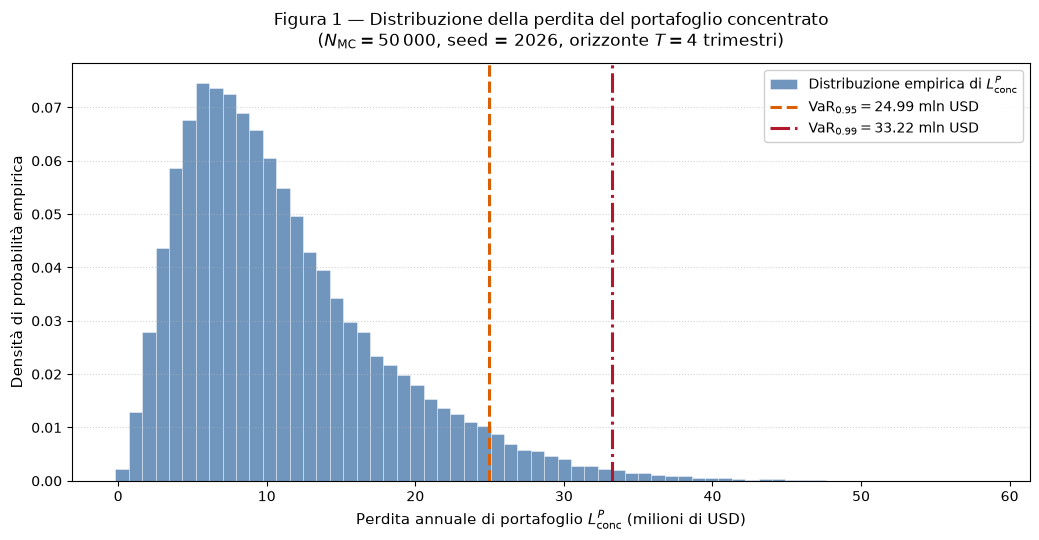

### Verifica empirica di stabilità Monte Carlo — Controllo 15

_Ricalcolo delle principali misure (in milioni di USD) su prefissi cumulativi crescenti delle $50\,000$ repliche già simulate nella Tappa 7, senza eseguire nuove simulazioni. Il confronto va interpretato come **verifica empirica di stabilità** e non come dimostrazione formale di convergenza._

#### Portafoglio concentrato — Progressione cumulativa delle stime

Repliche cumulative (N),Perdita media,Deviazione standard,VaR 95%,CVaR 95%,VaR 99%,CVaR 99%,Max |Δ| vs 50.000 (mln USD),Max |Δ rel.| vs 50.000 (%)
"1,000",11.1114,7.0920,24.8000,30.4274,33.6200,38.1410,0.5862,1.56%
"2,500",11.2921,7.0717,25.2800,30.3441,33.6200,37.8904,0.4000,1.23%
"5,000",11.3202,7.1472,25.5400,30.5335,33.5500,37.4476,0.5500,2.20%
"10,000",11.1869,7.1100,25.4000,30.5515,33.8200,37.7188,0.6000,1.81%
"20,000",11.1080,7.0010,24.9600,30.0617,33.4800,37.4443,0.2600,0.78%
"30,000",11.1425,7.0094,25.0500,30.1158,33.4100,37.6059,0.1900,0.57%
"40,000",11.1436,7.0019,24.9500,30.0617,33.3700,37.6646,0.1500,0.45%
"50,000",11.1553,6.9997,24.9900,30.0351,33.2200,37.5548,0.0000,0.00%


#### Portafoglio controfattuale — Progressione cumulativa delle stime

Repliche cumulative (N),Perdita media,Deviazione standard,VaR 95%,CVaR 95%,VaR 99%,CVaR 99%,Max |Δ| vs 50.000 (mln USD),Max |Δ rel.| vs 50.000 (%)
"1,000",12.1832,7.2649,26.6163,30.5703,32.3557,34.9296,2.3206,6.23%
"2,500",12.3460,7.2951,26.7682,30.8373,32.8934,35.7180,1.5323,4.11%
"5,000",12.3758,7.4365,27.5164,31.4793,34.0740,37.0047,0.7364,2.75%
"10,000",12.2264,7.4070,27.0488,31.4797,34.5065,37.6563,0.5026,1.48%
"20,000",12.1702,7.3435,26.8033,31.1966,34.1207,37.3198,0.1169,0.34%
"30,000",12.1998,7.3338,26.7916,31.1939,34.1091,37.3429,0.1052,0.31%
"40,000",12.1929,7.3270,26.6864,31.1641,34.0389,37.3377,0.0935,0.35%
"50,000",12.2053,7.3281,26.7799,31.1687,34.0039,37.2502,0.0000,0.00%


### Verifica dei Controlli — Tappa 8

Controllo,Descrizione,Valore rilevato,Esito
Controllo 14,VaR e CVaR calcolati sulle distribuzioni empiriche delle perdite monetarie (mln USD) mediante definizione basata sui quantili,"intervallo L_conc=[-0.18, 58.44] mln USD, L_div=[-0.21, 49.32] mln USD; max scarto identità CVaR=3.55e-14; test pareggi=True",SUPERATO
Controllo 15,Verifica empirica di stabilità delle principali misure al crescere delle repliche cumulative (senza nuove simulazioni),"oscillazione max tra 30k–40k e 50k: conc=0.1900 mln (0.57%), div=0.1052 mln (0.35%)",SUPERATO


In [8]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# ==============================================================================
# TAPPA 8 — Stima delle misure di rischio, Figura 1 e verifica di stabilità
# ==============================================================================

# 1. Verifica della disponibilità degli input prodotti nelle tappe precedenti
for nome_obj in ("L_conc_mc", "L_div_mc", "N_MC", "V0_conc", "V0_div", "PHI"):
    assert nome_obj in globals(), (
        f"Input '{nome_obj}' non trovato: eseguire in sequenza le Tappe 1–7."
    )

assert len(L_conc_mc) == N_MC == 50_000, f"Attese 50.000 repliche in L_conc_mc, trovate {len(L_conc_mc)}."
assert len(L_div_mc) == N_MC == 50_000, f"Attese 50.000 repliche in L_div_mc, trovate {len(L_div_mc)}."

# ==============================================================================
# 2. Definizione delle funzioni di stima delle misure di rischio (in mln USD)
# ==============================================================================
def calcola_var_cvar_quantili(campione_monetario: np.ndarray, alpha: float) -> tuple[float, float]:
    """
    Calcola VaR_alpha e CVaR_alpha direttamente sulla distribuzione empirica discreta
    delle perdite monetarie (in milioni di dollari) mediante la definizione basata sui quantili:
      - VaR_alpha  = q_alpha(L) = x_(k_alpha), con k_alpha = ceil(alpha * N) (indicizzazione 1-based)
      - CVaR_alpha = (1 / (1 - alpha)) * integral_alpha^1 q_u(L) du
                   = (1 / (1 - alpha)) * [ (k_alpha / N - alpha) * x_(k_alpha)
                                           + (1 / N) * sum_{k = k_alpha + 1}^{N} x_(k) ]

    In presenza di osservazioni uguali alla soglia VaR, la formula assegna alla coda
    esattamente massa di probabilità (1 - alpha) senza ampliare arbitrariamente la coda.
    """
    if not (0.0 < alpha < 1.0):
        raise ValueError(f"Il livello di confidenza alpha deve appartenere a (0, 1): ricevuto {alpha}.")

    x_ordinato = np.sort(np.asarray(campione_monetario, dtype=float))
    n = x_ordinato.size
    if n == 0:
        raise ValueError("Il campione di perdite fornito è vuoto.")

    # Indice 1-based k_alpha = ceil(alpha * N), protetto da micro-scarti floating-point
    k_alpha = int(math.ceil(alpha * n - 1e-12))
    k_alpha = min(max(k_alpha, 1), n)

    var_alpha = float(x_ordinato[k_alpha - 1])

    # Integrale esatto della funzione quantile empirica q_u su (alpha, 1]
    peso_soglia = (k_alpha / n) - alpha
    contributo_coda_stretta = float(np.sum(x_ordinato[k_alpha:])) / n
    cvar_alpha = float((peso_soglia * var_alpha + contributo_coda_stretta) / (1.0 - alpha))

    return var_alpha, cvar_alpha


def calcola_misure_rischio(campione_monetario: np.ndarray) -> dict[str, float]:
    """
    Calcola le misure di posizione, dispersione e coda richieste dalla Scheda Caso
    direttamente sul campione delle perdite monetarie (in milioni di dollari).
    """
    x = np.asarray(campione_monetario, dtype=float)
    media = float(np.mean(x))
    varianza = float(np.var(x, ddof=1))   # Varianza campionaria non distorta, in (mln USD)^2
    dev_std = float(np.sqrt(varianza))    # Deviazione standard campionaria, in mln USD

    var_95, cvar_95 = calcola_var_cvar_quantili(x, alpha=0.95)
    var_99, cvar_99 = calcola_var_cvar_quantili(x, alpha=0.99)

    return {
        "Perdita media": media,
        "Varianza": varianza,
        "Deviazione standard": dev_std,
        "VaR 95%": var_95,
        "CVaR 95%": cvar_95,
        "VaR 99%": var_99,
        "CVaR 99%": cvar_99,
    }


# ==============================================================================
# 3. Stima delle misure di rischio per entrambi i portafogli (senza differenze)
# ==============================================================================
misure_conc = calcola_misure_rischio(L_conc_mc)
misure_div = calcola_misure_rischio(L_div_mc)

ordine_misure = [
    ("Perdita media", "mln USD"),
    ("Varianza", "(mln USD)^2"),
    ("Deviazione standard", "mln USD"),
    ("VaR 95%", "mln USD"),
    ("CVaR 95%", "mln USD"),
    ("VaR 99%", "mln USD"),
    ("CVaR 99%", "mln USD"),
]

# Sintesi ordinata delle misure dei due portafogli (senza colonna differenza;
# la Tabella 3 con le differenze Δρ sarà costruita nella Tappa 10)
df_sintesi_misure_tappa_8 = pd.DataFrame(
    [
        {
            "Misura di rischio": nome,
            "Unità di misura": unita,
            "Portafoglio concentrato": misure_conc[nome],
            "Portafoglio controfattuale": misure_div[nome],
        }
        for nome, unita in ordine_misure
    ]
)

display(
    Markdown(
        "### Sintesi ordinata delle misure di rischio stimate — Tappa 8 ($N_{\\mathrm{MC}} = 50\\,000$)\n\n"
        "_Nota: i valori sono calcolati direttamente sulle distribuzioni empiriche delle perdite monetarie "
        "in milioni di dollari (`ddof = 1` per varianza e deviazione standard; definizione mediante quantili per VaR e CVaR). "
        "Le differenze $\\Delta\\rho$ e la Tabella 3 saranno costruite nella Tappa 10._"
    )
)
display(
    df_sintesi_misure_tappa_8.style.format(
        {
            "Portafoglio concentrato": "{:.4f}",
            "Portafoglio controfattuale": "{:.4f}",
        }
    ).hide(axis="index")
)

# ==============================================================================
# 4. FIGURA 1 — Distribuzione della perdita del portafoglio concentrato
# ==============================================================================
var95_conc = misure_conc["VaR 95%"]
var99_conc = misure_conc["VaR 99%"]

fig, ax = plt.subplots(figsize=(10.5, 5.5))

ax.hist(
    L_conc_mc,
    bins=65,
    density=True,
    color="#3b6ea5",
    alpha=0.72,
    edgecolor="white",
    linewidth=0.4,
    label="Distribuzione empirica di $L_{\\mathrm{conc}}^P$",
)

ax.axvline(
    var95_conc,
    color="#d95f02",
    linestyle="--",
    linewidth=2.2,
    label=f"$\\mathrm{{VaR}}_{{0.95}} = {var95_conc:.2f}$ mln USD",
)
ax.axvline(
    var99_conc,
    color="#b2182b",
    linestyle="-.",
    linewidth=2.2,
    label=f"$\\mathrm{{VaR}}_{{0.99}} = {var99_conc:.2f}$ mln USD",
)

ax.set_title(
    "Figura 1 — Distribuzione della perdita del portafoglio concentrato\n"
    "($N_{\\mathrm{MC}} = 50\\,000$, seed = 2026, orizzonte $T = 4$ trimestri)",
    fontsize=12.5,
    pad=12,
)
ax.set_xlabel("Perdita annuale di portafoglio $L_{\\mathrm{conc}}^P$ (milioni di USD)", fontsize=11)
ax.set_ylabel("Densità di probabilità empirica", fontsize=11)
ax.grid(axis="y", linestyle=":", alpha=0.55)
ax.legend(frameon=True, facecolor="white", framealpha=0.92, fontsize=10, loc="upper right")

plt.tight_layout()
plt.show()

# ==============================================================================
# 5. CONTROLLO 15 — Verifica empirica di stabilità su sotto-campioni cumulativi
#    (nessuna nuova simulazione: si usano prefissi crescenti delle 50.000 repliche)
# ==============================================================================
numerosita_cumulative = [1_000, 2_500, 5_000, 10_000, 20_000, 30_000, 40_000, 50_000]
misure_stabilita = [
    "Perdita media",
    "Deviazione standard",
    "VaR 95%",
    "CVaR 95%",
    "VaR 99%",
    "CVaR 99%",
]

def costruisci_tabella_stabilita(campione_completo: np.ndarray, misure_ref: dict[str, float]) -> pd.DataFrame:
    righe = []
    for n in numerosita_cumulative:
        stima_n = calcola_misure_rischio(campione_completo[:n])
        riga = {"Repliche cumulative (N)": n}
        for m in misure_stabilita:
            riga[m] = stima_n[m]
        # Scarto assoluto massimo e scarto relativo massimo rispetto a N = 50.000 sulle misure principali
        scarti_ass = [abs(stima_n[m] - misure_ref[m]) for m in misure_stabilita]
        scarti_rel = [abs(stima_n[m] - misure_ref[m]) / abs(misure_ref[m]) for m in misure_stabilita]
        riga["Max |Δ| vs 50.000 (mln USD)"] = float(max(scarti_ass))
        riga["Max |Δ rel.| vs 50.000 (%)"] = float(100.0 * max(scarti_rel))
        righe.append(riga)
    return pd.DataFrame(righe)

df_stabilita_conc = costruisci_tabella_stabilita(L_conc_mc, misure_conc)
df_stabilita_div = costruisci_tabella_stabilita(L_div_mc, misure_div)

display(
    Markdown(
        "### Verifica empirica di stabilità Monte Carlo — Controllo 15\n\n"
        "_Ricalcolo delle principali misure (in milioni di USD) su prefissi cumulativi crescenti delle $50\\,000$ "
        "repliche già simulate nella Tappa 7, senza eseguire nuove simulazioni. "
        "Il confronto va interpretato come **verifica empirica di stabilità** e non come dimostrazione formale di convergenza._"
    )
)

formato_stabilita = {
    "Repliche cumulative (N)": "{:,d}",
    "Perdita media": "{:.4f}",
    "Deviazione standard": "{:.4f}",
    "VaR 95%": "{:.4f}",
    "CVaR 95%": "{:.4f}",
    "VaR 99%": "{:.4f}",
    "CVaR 99%": "{:.4f}",
    "Max |Δ| vs 50.000 (mln USD)": "{:.4f}",
    "Max |Δ rel.| vs 50.000 (%)": "{:.2f}%",
}

display(Markdown("#### Portafoglio concentrato — Progressione cumulativa delle stime"))
display(df_stabilita_conc.style.format(formato_stabilita).hide(axis="index"))

display(Markdown("#### Portafoglio controfattuale — Progressione cumulativa delle stime"))
display(df_stabilita_div.style.format(formato_stabilita).hide(axis="index"))

# ==============================================================================
# 6. VERIFICA FORMALE DEI CONTROLLI DELLA TAPPA 8 (Controllo 14 e Controllo 15)
# ==============================================================================
tol = 1e-12

# --- Controllo 14: calcolo su distribuzioni empiriche delle perdite monetarie in mln USD ---
# 1) Verifica che i campioni siano esattamente nell'intervallo monetario teorico [min(PHI)*173, max(PHI)*173]
min_perdita_teorica_mln = float(PHI.min() * V0_conc)   # -0.06 * 173 = -10.38 mln USD
max_perdita_teorica_mln = float(PHI.max() * V0_conc)   #  0.65 * 173 = 112.45 mln USD

bounds_conc_ok = bool(
    (L_conc_mc.min() >= min_perdita_teorica_mln - tol)
    and (L_conc_mc.max() <= max_perdita_teorica_mln + tol)
    and (L_conc_mc.max() > 1.0)  # esclude tassi percentuali in [0, 1]
)
bounds_div_ok = bool(
    (L_div_mc.min() >= min_perdita_teorica_mln - tol)
    and (L_div_mc.max() <= max_perdita_teorica_mln + tol)
    and (L_div_mc.max() > 1.0)   # esclude tassi percentuali in [0, 1]
)

# 2) Coerenza matematica e di ordinamento delle misure monetarie (VaR <= CVaR, livello 95% <= 99%, SD = sqrt(Var))
def verifica_coerenza_misure(campione: np.ndarray, misure: dict[str, float]) -> tuple[bool, float]:
    sd_ok = abs(misure["Deviazione standard"] - math.sqrt(misure["Varianza"])) <= tol
    ordine_ok = (
        (misure["VaR 95%"] <= misure["CVaR 95%"] + tol)
        and (misure["VaR 99%"] <= misure["CVaR 99%"] + tol)
        and (misure["VaR 95%"] <= misure["VaR 99%"] + tol)
        and (misure["CVaR 95%"] <= misure["CVaR 99%"] + tol)
    )
    # Cross-check esatto della definizione integrale di CVaR mediante l'identità equivalente
    # di Rockafellar-Uryasev sulla distribuzione empirica discreta:
    # CVaR_alpha = VaR_alpha + (1 / (1 - alpha)) * mean(max(L - VaR_alpha, 0))
    scarto_ru_95 = abs(
        misure["CVaR 95%"]
        - (misure["VaR 95%"] + float(np.mean(np.maximum(campione - misure["VaR 95%"], 0.0))) / 0.05)
    )
    scarto_ru_99 = abs(
        misure["CVaR 99%"]
        - (misure["VaR 99%"] + float(np.mean(np.maximum(campione - misure["VaR 99%"], 0.0))) / 0.01)
    )
    max_scarto_ru = max(scarto_ru_95, scarto_ru_99)
    return bool(sd_ok and ordine_ok and (max_scarto_ru <= 1e-10)), max_scarto_ru

coerenza_conc_ok, scarto_ru_conc = verifica_coerenza_misure(L_conc_mc, misure_conc)
coerenza_div_ok, scarto_ru_div = verifica_coerenza_misure(L_div_mc, misure_div)
max_scarto_cvar_identita = max(scarto_ru_conc, scarto_ru_div)

# 3) Test mirato sui pareggi alla soglia VaR (verifica che non vi sia ampliamento arbitrario della coda)
campione_pareggi = np.array([0.0, 0.0, 10.0, 10.0, 10.0, 10.0, 10.0, 10.0, 20.0, 30.0])
var_tie, cvar_tie = calcola_var_cvar_quantili(campione_pareggi, alpha=0.70)
gestione_pareggi_ok = bool((abs(var_tie - 10.0) <= tol) and (abs(cvar_tie - 20.0) <= tol))

ctrl_14 = bool(
    bounds_conc_ok
    and bounds_div_ok
    and coerenza_conc_ok
    and coerenza_div_ok
    and gestione_pareggi_ok
)

# --- Controllo 15: verifica empirica di stabilità sui prefissi cumulativi ---
# Verifica che all'ultimo passo (N=50.000) gli scarti siano nulli e che tra 30.000, 40.000 e 50.000
# le stime principali mostrino oscillazioni contenute (verifica empirica, non dimostrazione formale)
scarto_finale_conc = float(df_stabilita_conc.iloc[-1]["Max |Δ| vs 50.000 (mln USD)"])
scarto_finale_div = float(df_stabilita_div.iloc[-1]["Max |Δ| vs 50.000 (mln USD)"])

max_oscillazione_rel_conc_30k_50k = float(
    df_stabilita_conc.loc[
        df_stabilita_conc["Repliche cumulative (N)"].isin([30_000, 40_000]),
        "Max |Δ rel.| vs 50.000 (%)",
    ].max()
)
max_oscillazione_rel_div_30k_50k = float(
    df_stabilita_div.loc[
        df_stabilita_div["Repliche cumulative (N)"].isin([30_000, 40_000]),
        "Max |Δ rel.| vs 50.000 (%)",
    ].max()
)
max_oscillazione_ass_conc_30k_50k = float(
    df_stabilita_conc.loc[
        df_stabilita_conc["Repliche cumulative (N)"].isin([30_000, 40_000]),
        "Max |Δ| vs 50.000 (mln USD)",
    ].max()
)
max_oscillazione_ass_div_30k_50k = float(
    df_stabilita_div.loc[
        df_stabilita_div["Repliche cumulative (N)"].isin([30_000, 40_000]),
        "Max |Δ| vs 50.000 (mln USD)",
    ].max()
)

ctrl_15 = bool(
    (scarto_finale_conc <= tol)
    and (scarto_finale_div <= tol)
    and np.all(np.isfinite(df_stabilita_conc[misure_stabilita].to_numpy()))
    and np.all(np.isfinite(df_stabilita_div[misure_stabilita].to_numpy()))
    and (max_oscillazione_rel_conc_30k_50k < 5.0)
    and (max_oscillazione_rel_div_30k_50k < 5.0)
)

# Asserzioni formali di verifica
assert ctrl_14, (
    f"Controllo 14 fallito: bounds=({bounds_conc_ok}, {bounds_div_ok}), "
    f"coerenza=({coerenza_conc_ok}, {coerenza_div_ok}), pareggi={gestione_pareggi_ok}."
)
assert ctrl_15, (
    f"Controllo 15 fallito: scarti_finali=({scarto_finale_conc:.2e}, {scarto_finale_div:.2e}), "
    f"oscillazioni_30k_50k=({max_oscillazione_rel_conc_30k_50k:.2f}%, {max_oscillazione_rel_div_30k_50k:.2f}%)."
)

# Riepilogo leggibile degli esiti dei controlli della Tappa 8
riepilogo_controlli_tappa_8 = pd.DataFrame(
    [
        {
            "Controllo": "Controllo 14",
            "Descrizione": "VaR e CVaR calcolati sulle distribuzioni empiriche delle perdite monetarie (mln USD) mediante definizione basata sui quantili",
            "Valore rilevato": (
                f"intervallo L_conc=[{L_conc_mc.min():.2f}, {L_conc_mc.max():.2f}] mln USD, "
                f"L_div=[{L_div_mc.min():.2f}, {L_div_mc.max():.2f}] mln USD; "
                f"max scarto identità CVaR={max_scarto_cvar_identita:.2e}; test pareggi={gestione_pareggi_ok}"
            ),
            "Esito": "SUPERATO" if ctrl_14 else "NON SUPERATO",
        },
        {
            "Controllo": "Controllo 15",
            "Descrizione": "Verifica empirica di stabilità delle principali misure al crescere delle repliche cumulative (senza nuove simulazioni)",
            "Valore rilevato": (
                f"oscillazione max tra 30k–40k e 50k: "
                f"conc={max_oscillazione_ass_conc_30k_50k:.4f} mln ({max_oscillazione_rel_conc_30k_50k:.2f}%), "
                f"div={max_oscillazione_ass_div_30k_50k:.4f} mln ({max_oscillazione_rel_div_30k_50k:.2f}%)"
            ),
            "Esito": "SUPERATO" if ctrl_15 else "NON SUPERATO",
        },
    ]
)

display(Markdown("### Verifica dei Controlli — Tappa 8"))
display(riepilogo_controlli_tappa_8.style.hide(axis="index"))

## Tappa 9 — Analisi del regime di crisi e delle perdite condizionate

### Richiesta dello studente (copia fedele)

> Sto lavorando sulla **Tappa 9 — Analisi del regime di crisi e delle perdite condizionate**.
>
> Partendo dalle traiettorie sistemiche e dalle perdite del portafoglio concentrato ottenute nella Tappa 7, insieme alla sua perdita media complessiva calcolata nella Tappa 8, voglio analizzare il legame tra l’ingresso nel regime di crisi e il livello delle perdite. Per ogni replica bisogna verificare se lo stato di crisi compare almeno una volta nella traiettoria sistemica e costruire due gruppi distinti: le repliche con almeno un ingresso in crisi e quelle nelle quali la crisi non viene mai raggiunta. Vorrei conservare un indicatore booleano allineato all’ordine delle repliche, così da poter filtrare correttamente le perdite senza separarle dagli scenari sistemici che le hanno generate. Una volta suddiviso il campione, voglio stimare la probabilità simulata di ingresso in crisi e calcolare, per il portafoglio concentrato, la perdita media nei due gruppi. Come output devono essere visualizzate la **Tabella 4 — Regime sistemico e perdita**, con il confronto tra repliche con e senza ingresso in crisi, e la **Figura 3 — Regime sistemico e perdita**, che deve permettere di confrontare in modo chiaro le rispettive distribuzioni delle perdite. Preferisco che la tabella riporti almeno il numero e la frequenza delle repliche di ciascun gruppo e la corrispondente perdita media, mantenendo la precisione completa nei calcoli e utilizzando un arrotondamento leggibile soltanto nella visualizzazione. Il grafico deve riportare titolo, assi, legenda e perdite espresse in milioni di dollari, utilizzando la stessa scala per i due gruppi così da non rendere fuorviante il confronto. Come controllo aggiuntivo voglio verificare che i due gruppi siano disgiunti e comprendano complessivamente tutte le 50.000 repliche e che la media delle due perdite condizionate, ponderata con le rispettive frequenze simulate, coincida entro la normale precisione numerica con la perdita media complessiva del portafoglio concentrato. In questa tappa non devono essere generate nuove traiettorie né ricalcolate le perdite: devono essere utilizzati soltanto gli scenari e i risultati già prodotti nelle Tappe 7 e 8. L’analisi deve rimanere descrittiva e quantitativa, senza anticipare l’interpretazione economico-finanziaria finale.

### Sintesi logica della tappa

- **Input:** esclusivamente oggetti già prodotti nelle Tappe 7 e 8, senza generare nuove traiettorie né ricalcolare perdite:
  - matrice allineata delle traiettorie sistemiche `traiettorie_sistemiche_mc` di dimensione $(50\,000, 4)$ con stati $(M_0, M_1, M_2, M_3)$ e numero di repliche `N_MC` (Tappa 7);
  - vettore allineato delle perdite monetarie del portafoglio concentrato `L_conc_mc` in milioni di dollari e tabella `df_simulazione_mc` (Tappa 7);
  - perdita media complessiva stimata del portafoglio concentrato `misure_conc["Perdita media"]` (Tappa 8).
- **Operazioni:**
  1. costruzione dell'indicatore booleano `ingresso_crisi_mc` (di lunghezza $50\,000$, allineato all'ordine delle repliche) che identifica l'evento $A_C = \{\exists\, t \in \{0, 1, 2, 3\} : M_t = C\}$ e del suo complemento `senza_crisi_mc` ($A_C^c$);
  2. partizione del vettore `L_conc_mc` nei due sottocampioni distinti `L_conc_con_crisi` e `L_conc_senza_crisi` mediante filtraggio diretto sull'indicatore booleano allineato;
  3. stima a precisione completa della probabilità simulata di ingresso nel regime di crisi $\widehat{\mathbb{P}}(A_C)$ (e del complemento $\widehat{\mathbb{P}}(A_C^c)$) e delle perdite medie condizionate $\widehat{\mathbb{E}}[L_{\mathrm{conc}}^P \mid A_C]$ e $\widehat{\mathbb{E}}[L_{\mathrm{conc}}^P \mid A_C^c]$;
  4. costruzione e visualizzazione della **Tabella 4 — Regime sistemico e perdita** (mantenendo la precisione completa nel DataFrame sottostante e applicando l'arrotondamento solo in visualizzazione) e della **Figura 3 — Regime sistemico e perdita**, rappresentando le due distribuzioni empiriche sulla medesima scala di ascisse, classi di istogramma e ordinate (in milioni di dollari);
  5. svolgimento dei controlli integrativi di partizione esatta e di coerenza tramite legge della speranza totale.
- **Output:**
  - indicatore booleano allineato `ingresso_crisi_mc` (e complemento `senza_crisi_mc`) e sottocampioni `L_conc_con_crisi`, `L_conc_senza_crisi`;
  - scalari a precisione completa `prob_crisi_mc`, `prob_senza_crisi_mc`, `media_conc_con_crisi`, `media_conc_senza_crisi`;
  - **Tabella 4 — Regime sistemico e perdita** (`tabella_4`);
  - **Figura 3 — Regime sistemico e perdita**;
  - tabella riepilogativa dell'esito dei controlli integrativi della tappa (`riepilogo_controlli_tappa_9`).
- **Controlli della tappa:**
  - verifica che i due gruppi ($A_C$ e $A_C^c$) siano disgiunti, esaustivi sull'intero campione delle $50\,000$ repliche ($n_{A_C} + n_{A_C^c} = 50\,000$) e perfettamente allineati agli scenari sistemici della Tappa 7;
  - verifica della legge della speranza totale: la media delle due perdite condizionate ponderata con le rispettive frequenze simulate, $\widehat{\mathbb{P}}(A_C)\,\widehat{\mathbb{E}}[L_{\mathrm{conc}}^P \mid A_C] + \widehat{\mathbb{P}}(A_C^c)\,\widehat{\mathbb{E}}[L_{\mathrm{conc}}^P \mid A_C^c]$, deve coincidere entro tolleranza numerica con $\widehat{\mathbb{E}}[L_{\mathrm{conc}}^P]$ calcolata nella Tappa 8.
- **Uso successivo:** i risultati numerici su $\widehat{\mathbb{P}}(A_C)$ e sulle perdite medie condizionate, insieme alla **Tabella 4**, alla **Figura 3** e agli esiti dei controlli della tappa, confluiranno nel quadro riepilogativo della **Tappa 11** a supporto dell'interpretazione critica autonoma dello studente nella Fase 8.

### Tabella 4 — Regime sistemico e perdita (portafoglio concentrato)

- **Probabilità simulata di almeno un ingresso nello stato $C$:** $\widehat{\mathbb{P}}(A_C) = 0.296960$ ($29.70\%$)
- **Perdita media condizionata con ingresso in $C$:** $\widehat{\mathbb{E}}[L_{\mathrm{conc}}^P \mid A_C] = 18.3794$ mln USD
- **Perdita media condizionata senza ingresso in $C$:** $\widehat{\mathbb{E}}[L_{\mathrm{conc}}^P \mid A_C^c] = 8.1039$ mln USD

Gruppo di repliche,Numero repliche,Frequenza simulata (probabilità),Frequenza simulata (%),Perdita media L_conc^P (mln USD)
Almeno un ingresso nello stato C,"14,848",0.296960,29.70%,18.3794
Nessun ingresso nello stato C,"35,152",0.703040,70.30%,8.1039
Totale campione simulato,"50,000",1.000000,100.00%,11.1553


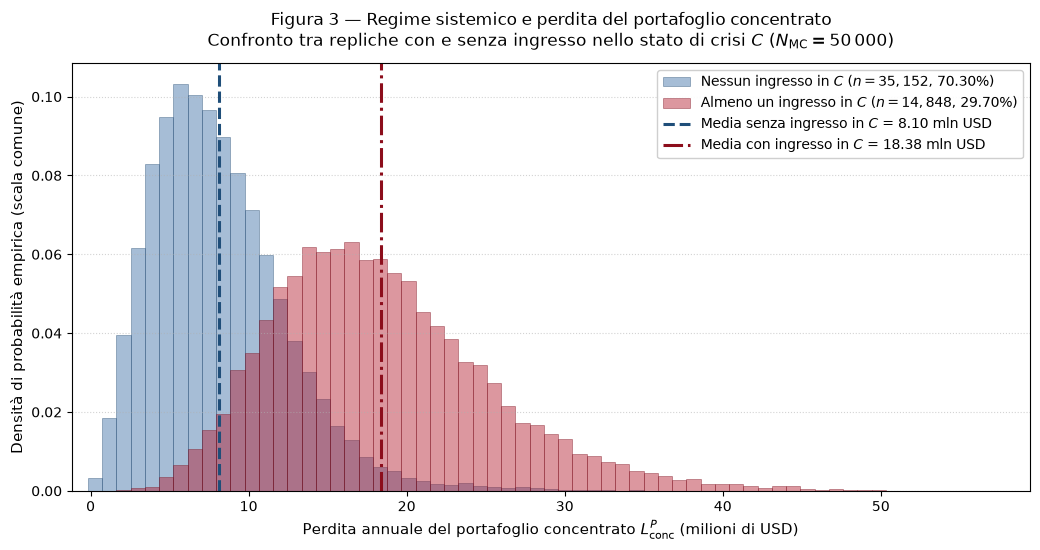

### Verifica dei Controlli — Tappa 9

Controllo,Descrizione,Valore rilevato,Esito
Controllo integrativo — Partizione e allineamento,"I due gruppi (con C / senza C) sono disgiunti, esaustivi su 50.000 repliche e allineati a df_simulazione_mc","n_con_C=14,848 + n_senza_C=35,152 = 50,000; disgiunti=True; Σfreq=1.000000000000; allineamento=True",SUPERATO
Controllo integrativo — Legge della speranza totale,La media ponderata delle due perdite condizionate coincide con la perdita media complessiva (Tappa 8),media_ponderata=11.155311000000 mln USD; media_Tappa_8=11.155311000000 mln USD; |scarto|=0.00e+00,SUPERATO


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# ==============================================================================
# TAPPA 9 — Analisi del regime di crisi e delle perdite condizionate
# ==============================================================================

# 1. Verifica della disponibilità degli input prodotti nelle Tappe 7 e 8
#    (nessuna nuova simulazione né ricalcolo delle perdite)
for nome_obj in (
    "traiettorie_sistemiche_mc",
    "L_conc_mc",
    "N_MC",
    "misure_conc",
    "df_simulazione_mc",
):
    assert nome_obj in globals(), (
        f"Input '{nome_obj}' non trovato: eseguire in sequenza le Tappe 7 e 8."
    )

assert traiettorie_sistemiche_mc.shape == (N_MC, 4), (
    f"Attesa forma ({N_MC}, 4) per traiettorie_sistemiche_mc, trovata {traiettorie_sistemiche_mc.shape}."
)
assert L_conc_mc.shape == (N_MC,), (
    f"Attesa lunghezza {N_MC} per L_conc_mc, trovata {L_conc_mc.shape}."
)

# ==============================================================================
# 2. Costruzione dell'indicatore booleano di ingresso in crisi (allineato alle repliche)
#    Evento A_C = {esiste almeno un t in {0, 1, 2, 3} tale che M_t == "C"}
# ==============================================================================
ingresso_crisi_mc = np.any(traiettorie_sistemiche_mc == "C", axis=1)
senza_crisi_mc = ~ingresso_crisi_mc

# Partizione del campione di perdite del portafoglio concentrato (in milioni di USD)
L_conc_con_crisi = L_conc_mc[ingresso_crisi_mc]
L_conc_senza_crisi = L_conc_mc[senza_crisi_mc]

# ==============================================================================
# 3. Stima a precisione completa di probabilità di crisi e perdite medie condizionate
# ==============================================================================
n_con_crisi = int(np.sum(ingresso_crisi_mc))
n_senza_crisi = int(np.sum(senza_crisi_mc))

prob_crisi_mc = float(n_con_crisi / N_MC)
prob_senza_crisi_mc = float(n_senza_crisi / N_MC)

media_conc_con_crisi = float(np.mean(L_conc_con_crisi))
media_conc_senza_crisi = float(np.mean(L_conc_senza_crisi))
media_conc_complessiva_t8 = float(misure_conc["Perdita media"])

# ==============================================================================
# 4. TABELLA 4 — Regime sistemico e perdita (portafoglio concentrato)
#    Precisione completa nel DataFrame; arrotondamento solo nella visualizzazione
# ==============================================================================
tabella_4 = pd.DataFrame(
    [
        {
            "Gruppo di repliche": "Almeno un ingresso nello stato C",
            "Numero repliche": n_con_crisi,
            "Frequenza simulata (probabilità)": prob_crisi_mc,
            "Frequenza simulata (%)": 100.0 * prob_crisi_mc,
            "Perdita media L_conc^P (mln USD)": media_conc_con_crisi,
        },
        {
            "Gruppo di repliche": "Nessun ingresso nello stato C",
            "Numero repliche": n_senza_crisi,
            "Frequenza simulata (probabilità)": prob_senza_crisi_mc,
            "Frequenza simulata (%)": 100.0 * prob_senza_crisi_mc,
            "Perdita media L_conc^P (mln USD)": media_conc_senza_crisi,
        },
        {
            "Gruppo di repliche": "Totale campione simulato",
            "Numero repliche": N_MC,
            "Frequenza simulata (probabilità)": prob_crisi_mc + prob_senza_crisi_mc,
            "Frequenza simulata (%)": 100.0 * (prob_crisi_mc + prob_senza_crisi_mc),
            "Perdita media L_conc^P (mln USD)": media_conc_complessiva_t8,
        },
    ]
)

display(Markdown("### Tabella 4 — Regime sistemico e perdita (portafoglio concentrato)"))
display(
    Markdown(
        f"- **Probabilità simulata di almeno un ingresso nello stato $C$:** "
        f"$\\widehat{{\\mathbb{{P}}}}(A_C) = {prob_crisi_mc:.6f}$ (${100.0 * prob_crisi_mc:.2f}\\%$)\n"
        f"- **Perdita media condizionata con ingresso in $C$:** "
        f"$\\widehat{{\\mathbb{{E}}}}[L_{{\\mathrm{{conc}}}}^P \\mid A_C] = {media_conc_con_crisi:.4f}$ mln USD\n"
        f"- **Perdita media condizionata senza ingresso in $C$:** "
        f"$\\widehat{{\\mathbb{{E}}}}[L_{{\\mathrm{{conc}}}}^P \\mid A_C^c] = {media_conc_senza_crisi:.4f}$ mln USD"
    )
)

display(
    tabella_4.style.format(
        {
            "Numero repliche": "{:,d}",
            "Frequenza simulata (probabilità)": "{:.6f}",
            "Frequenza simulata (%)": "{:.2f}%",
            "Perdita media L_conc^P (mln USD)": "{:.4f}",
        }
    ).hide(axis="index")
)

# ==============================================================================
# 5. FIGURA 3 — Regime sistemico e perdita (stessa scala per entrambi i gruppi)
# ==============================================================================
# Classi di istogramma e limiti di ascissa comuni costruiti sull'intero supporto osservato
x_min = float(L_conc_mc.min())
x_max = float(L_conc_mc.max())
bins_comuni = np.linspace(x_min, x_max, 66)

fig, ax = plt.subplots(figsize=(10.5, 5.6))

# Distribuzioni empiriche normalizzate in densità sugli stessi assi e sugli stessi bin
ax.hist(
    L_conc_senza_crisi,
    bins=bins_comuni,
    density=True,
    color="#3b6ea5",
    alpha=0.45,
    edgecolor="#264b73",
    linewidth=0.6,
    label=(
        f"Nessun ingresso in $C$ ($n = {n_senza_crisi:,}$, "
        f"${100.0 * prob_senza_crisi_mc:.2f}\\%$)"
    ),
)
ax.hist(
    L_conc_con_crisi,
    bins=bins_comuni,
    density=True,
    color="#b2182b",
    alpha=0.45,
    edgecolor="#7a0f1d",
    linewidth=0.6,
    label=(
        f"Almeno un ingresso in $C$ ($n = {n_con_crisi:,}$, "
        f"${100.0 * prob_crisi_mc:.2f}\\%$)"
    ),
)

# Linee verticali per le due perdite medie condizionate
ax.axvline(
    media_conc_senza_crisi,
    color="#1f4e79",
    linestyle="--",
    linewidth=2.2,
    label=f"Media senza ingresso in $C$ = {media_conc_senza_crisi:.2f} mln USD",
)
ax.axvline(
    media_conc_con_crisi,
    color="#8c0d1b",
    linestyle="-.",
    linewidth=2.2,
    label=f"Media con ingresso in $C$ = {media_conc_con_crisi:.2f} mln USD",
)

ax.set_xlim(x_min - 1.0, x_max + 1.0)
ax.set_title(
    "Figura 3 — Regime sistemico e perdita del portafoglio concentrato\n"
    "Confronto tra repliche con e senza ingresso nello stato di crisi $C$ ($N_{\\mathrm{MC}} = 50\\,000$)",
    fontsize=12.5,
    pad=12,
)
ax.set_xlabel("Perdita annuale del portafoglio concentrato $L_{\\mathrm{conc}}^P$ (milioni di USD)", fontsize=11)
ax.set_ylabel("Densità di probabilità empirica (scala comune)", fontsize=11)
ax.grid(axis="y", linestyle=":", alpha=0.55)
ax.legend(frameon=True, facecolor="white", framealpha=0.93, fontsize=9.8, loc="upper right")

plt.tight_layout()
plt.show()

# ==============================================================================
# 6. CONTROLLI INTEGRATIVI DELLA TAPPA 9
# ==============================================================================
tol = 1e-12

# 6.1 Partizione disgiunta ed esaustiva sulle 50.000 repliche + coerenza di allineamento con df_simulazione_mc
disgiunti_ok = bool(not np.any(ingresso_crisi_mc & senza_crisi_mc))
esaustivi_ok = bool(
    np.all(ingresso_crisi_mc | senza_crisi_mc)
    and ((n_con_crisi + n_senza_crisi) == N_MC == 50_000)
    and (len(L_conc_con_crisi) == n_con_crisi)
    and (len(L_conc_senza_crisi) == n_senza_crisi)
)
somma_frequenze = prob_crisi_mc + prob_senza_crisi_mc
somma_frequenze_ok = bool(abs(somma_frequenze - 1.0) <= tol)

# Coerenza dell'allineamento rispetto a df_simulazione_mc prodotto in Tappa 7
crisi_da_df = (df_simulazione_mc[["M_0", "M_1", "M_2", "M_3"]].to_numpy() == "C").any(axis=1)
allineamento_ok = bool(
    np.array_equal(ingresso_crisi_mc, crisi_da_df)
    and np.array_equal(L_conc_mc, df_simulazione_mc["L_conc_mln"].to_numpy())
)

ctrl_partizione_crisi = bool(disgiunti_ok and esaustivi_ok and somma_frequenze_ok and allineamento_ok)

# 6.2 Legge della speranza totale: media ponderata delle due perdite condizionate = perdita media complessiva
media_ponderata_condizionata = (
    prob_crisi_mc * media_conc_con_crisi
    + prob_senza_crisi_mc * media_conc_senza_crisi
)
scarto_speranza_totale = abs(media_ponderata_condizionata - media_conc_complessiva_t8)
ctrl_speranza_totale = bool(scarto_speranza_totale <= tol)

# Asserzioni formali di verifica
assert ctrl_partizione_crisi, (
    f"Controllo partizione fallito: disgiunti={disgiunti_ok}, esaustivi={esaustivi_ok}, "
    f"somma_freq={somma_frequenze}, allineamento={allineamento_ok}."
)
assert ctrl_speranza_totale, (
    f"Controllo legge della speranza totale fallito: "
    f"ponderata={media_ponderata_condizionata:.12f}, complessiva={media_conc_complessiva_t8:.12f}, "
    f"scarto={scarto_speranza_totale:.2e}."
)

# Riepilogo leggibile degli esiti dei controlli della Tappa 9
riepilogo_controlli_tappa_9 = pd.DataFrame(
    [
        {
            "Controllo": "Controllo integrativo — Partizione e allineamento",
            "Descrizione": "I due gruppi (con C / senza C) sono disgiunti, esaustivi su 50.000 repliche e allineati a df_simulazione_mc",
            "Valore rilevato": (
                f"n_con_C={n_con_crisi:,} + n_senza_C={n_senza_crisi:,} = {n_con_crisi + n_senza_crisi:,}; "
                f"disgiunti={disgiunti_ok}; Σfreq={somma_frequenze:.12f}; allineamento={allineamento_ok}"
            ),
            "Esito": "SUPERATO" if ctrl_partizione_crisi else "NON SUPERATO",
        },
        {
            "Controllo": "Controllo integrativo — Legge della speranza totale",
            "Descrizione": "La media ponderata delle due perdite condizionate coincide con la perdita media complessiva (Tappa 8)",
            "Valore rilevato": (
                f"media_ponderata={media_ponderata_condizionata:.12f} mln USD; "
                f"media_Tappa_8={media_conc_complessiva_t8:.12f} mln USD; "
                f"|scarto|={scarto_speranza_totale:.2e}"
            ),
            "Esito": "SUPERATO" if ctrl_speranza_totale else "NON SUPERATO",
        },
    ]
)

display(Markdown("### Verifica dei Controlli — Tappa 9"))
display(riepilogo_controlli_tappa_9.style.hide(axis="index"))

## Tappa 10 — Confronto controfattuale tra i due portafogli

### Richiesta dello studente (copia fedele)

> Sto lavorando sulla **Tappa 10 — Confronto controfattuale tra i due portafogli**.
>
> Partendo dalle distribuzioni empiriche delle perdite e dalla differenza di perdita calcolata replica per replica nella Tappa 7, insieme alle misure di rischio ottenute nella Tappa 8, voglio confrontare il portafoglio controfattuale con quello concentrato. Per ogni misura richiesta dalla Scheda Caso deve essere calcolata la variazione come valore del portafoglio controfattuale meno valore del portafoglio concentrato, mantenendo la stessa convenzione di segno per tutti i risultati: una differenza negativa indica che la misura è più bassa nel controfattuale, mentre una differenza positiva indica che è più alta. Come output deve essere visualizzata la **Tabella 3 — Misure di rischio**, riportando la perdita media, la varianza, la deviazione standard, il VaR e il CVaR al 95% e al 99% dei due portafogli e le rispettive differenze. Preferisco mantenere la precisione completa nei calcoli e applicare un arrotondamento leggibile soltanto nella tabella visualizzata. Deve inoltre essere prodotta la **Figura 2 — Confronto delle distribuzioni**, rappresentando insieme le perdite simulate dei due portafogli e rendendo chiaramente leggibile il confronto nella coda destra; il grafico deve riportare titolo, assi, legenda e unità di misura in milioni di dollari. Voglio poi analizzare separatamente la distribuzione della differenza di perdita replica per replica, senza confonderla con le differenze tra le misure calcolate sulle due distribuzioni. Come controllo aggiuntivo deve essere verificato che la media delle differenze replica per replica coincida, entro la normale precisione numerica, con la differenza tra le perdite medie dei due portafogli; questa relazione non deve essere estesa automaticamente alla varianza, alla deviazione standard, al VaR e al CVaR. In questa tappa non devono essere effettuate nuove simulazioni né ricalcolate le traiettorie, i rating o le perdite individuali, ma devono essere utilizzati esclusivamente gli oggetti già prodotti nelle tappe precedenti. Il confronto deve rimanere quantitativo e descrittivo, lasciando alla fase finale la mia interpretazione economico-finanziaria complessiva.

### Sintesi logica della tappa

- **Input:** esclusivamente oggetti già prodotti nelle Tappe 7 e 8, senza nuove simulazioni né ricalcoli di traiettorie, rating o perdite individuali:
  - distribuzioni empiriche allineate delle perdite monetarie (in milioni di dollari, precisione completa) e della differenza replica per replica: `L_conc_mc`, `L_div_mc`, `delta_L_mc`, `N_MC`, `df_simulazione_mc` (Tappa 7);
  - misure di rischio stimate per i due portafogli: `misure_conc`, `misure_div` e funzioni `calcola_var_cvar_quantili`, `calcola_misure_rischio` (Tappa 8).
- **Operazioni:**
  1. calcolo a precisione completa, per ciascuna delle sette misure di rischio richieste dalla Scheda Caso (perdita media, varianza, deviazione standard, $\operatorname{VaR}_{0.95}$, $\operatorname{CVaR}_{0.95}$, $\operatorname{VaR}_{0.99}$, $\operatorname{CVaR}_{0.99}$), della variazione $\Delta\rho = \rho(L_{\mathrm{div}}^P) - \rho(L_{\mathrm{conc}}^P)$ secondo la convenzione di segno vincolante (segno negativo = valore inferiore nel controfattuale; segno positivo = valore superiore nel controfattuale);
  2. costruzione e visualizzazione della **Tabella 3 — Misure di rischio** (`tabella_3`), conservando la precisione completa nel DataFrame e applicando l'arrotondamento soltanto nella visualizzazione;
  3. realizzazione della **Figura 2 — Confronto delle distribuzioni**, affiancando la rappresentazione complessiva delle due distribuzioni empiriche sulla medesima scala e un riquadro di ingrandimento dedicato alla coda destra (sulla stessa scala di densità non distorta, con indicazione dei livelli $\operatorname{VaR}_{0.95}$ e $\operatorname{VaR}_{0.99}$ di entrambi i portafogli);
  4. analisi descrittiva separata della distribuzione empirica della variabile casuale $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$ (statistiche descrittive, quantili empirici e ripartizione per segno), mantenuta formalmente distinta dalle differenze scalari $\Delta\rho$;
  5. svolgimento dei controlli integrativi di coerenza sulla convenzione di segno, sulla linearità della perdita media ($\widehat{\mathbb{E}}[\Delta L] = \Delta\widehat{\mathbb{E}}[L^P]$) e sulla distinzione rispetto alle misure non lineari.
- **Output:**
  - dizionario `differenze_misure` a precisione completa con i valori di $\Delta\rho$;
  - **Tabella 3 — Misure di rischio** (`tabella_3`);
  - **Figura 2 — Confronto delle distribuzioni** (vista complessiva e focus sulla coda destra);
  - prospetti descrittivi separati della distribuzione empirica di $\Delta L^{(r)}$ (`df_sintesi_delta_L` e `df_segno_delta_L`);
  - tabella riepilogativa dell'esito dei controlli integrativi della tappa (`riepilogo_controlli_tappa_10`).
- **Controlli della tappa:**
  - verifica dell'identità $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$ sull'intero campione e dell'esatta convenzione di segno $\Delta\rho = \rho(L_{\mathrm{div}}^P) - \rho(L_{\mathrm{conc}}^P)$ per tutte le sette misure;
  - controllo integrativo di linearità della media: $\widehat{\mathbb{E}}[\Delta L]$ deve coincidere entro tolleranza numerica con $\widehat{\mathbb{E}}[L_{\mathrm{div}}^P] - \widehat{\mathbb{E}}[L_{\mathrm{conc}}^P]$;
  - verifica esplicita che l'identità di linearità non si estende automaticamente a varianza, deviazione standard, $\operatorname{VaR}$ e $\operatorname{CVaR}$, confermando numericamente la distinzione tra $\Delta\rho$ e $\rho(\Delta L)$.
- **Uso successivo:** i risultati numerici su $\Delta\rho$ e sulla distribuzione empirica di $\Delta L^{(r)}$, insieme alla **Tabella 3**, alla **Figura 2** e agli esiti dei controlli della tappa, confluiranno nel riepilogo di completezza della **Tappa 11** a supporto dell'interpretazione critica autonoma dello studente nella Fase 8.

### Tabella 3 — Misure di rischio ($N_{\mathrm{MC}} = 50\,000$, `seed = 2026`)

_Convenzione di segno: $\Delta\rho = \rho(L_{\mathrm{div}}^P) - \rho(L_{\mathrm{conc}}^P)$ (valore negativo: misura inferiore nel portafoglio controfattuale; valore positivo: misura superiore nel portafoglio controfattuale). I valori sottostanti sono conservati a precisione completa; l'arrotondamento riguarda solo la visualizzazione._

Misura di rischio,Unità di misura,Portafoglio concentrato,Portafoglio controfattuale (riallocazione proporzionale),Differenza Δρ = ρ(div) − ρ(conc)
Perdita media,mln USD,11.1553,12.2053,+1.0500
Varianza,(mln USD)^2,48.9955,53.7015,+4.7061
Deviazione standard,mln USD,6.9997,7.3281,+0.3285
VaR 95%,mln USD,24.9900,26.7799,+1.7899
CVaR 95%,mln USD,30.0351,31.1687,+1.1336
VaR 99%,mln USD,33.2200,34.0039,+0.7839
CVaR 99%,mln USD,37.5548,37.2502,-0.3046


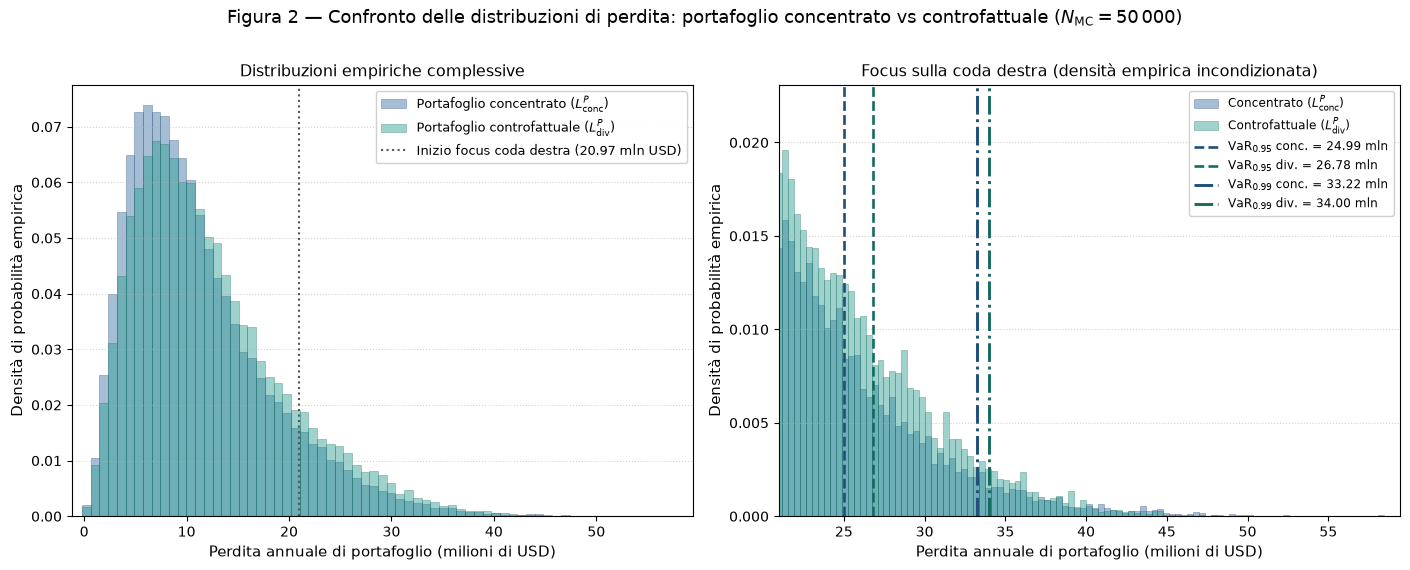

### Distribuzione empirica della differenza replica per replica $\Delta L^{(r)} = L_{\mathrm{div}}^{P,(r)} - L_{\mathrm{conc}}^{P,(r)}$

_Analisi distinta rispetto alla Tabella 3: descrive la distribuzione della variabile casuale $\Delta L^{(r)}$ calcolata scenario per scenario sulle medesime traiettorie sottostanti, e non le differenze $\Delta\rho$ tra le misure calcolate separatamente sulle due distribuzioni marginali._

Statistica della distribuzione empirica di ΔL^(r),Unità di misura,Valore
Media empirica E[ΔL],mln USD,+1.0500
Varianza empirica Var(ΔL) (ddof=1),(mln USD)^2,+5.8086
Deviazione standard empirica SD(ΔL),mln USD,+2.4101
Minimo,mln USD,-15.9645
Quantile 1%,mln USD,-13.6504
Quantile 5%,mln USD,-1.6183
Quantile 25% (Q1),mln USD,+0.6503
Mediana (50%),mln USD,+1.2500
Quantile 75% (Q3),mln USD,+2.0152
Quantile 95%,mln USD,+3.5170


Evento sulla singola replica,Numero repliche,Frequenza simulata,Frequenza simulata (%)
ΔL^(r) < 0 (L_div^P < L_conc^P),"5,336",0.106720,10.67%
ΔL^(r) = 0 (L_div^P = L_conc^P),8,0.000160,0.02%
ΔL^(r) > 0 (L_div^P > L_conc^P),"44,656",0.893120,89.31%
Totale campione simulato,"50,000",1.000000,100.00%


### Verifica dei Controlli — Tappa 10

Controllo,Descrizione,Valore rilevato,Esito
Controllo integrativo — Convenzione di segno e allineamento,Coerenza esatta di ΔL^(r) = L_div − L_conc e Δρ = ρ(div) − ρ(conc) su tutte le 50.000 repliche,"max|ΔL − (L_div − L_conc)|=0.00e+00; allineamento df=True; somma classi segno=50,000",SUPERATO
Controllo integrativo — Linearità della perdita media,La media di ΔL^(r) coincide entro precisione numerica con la differenza tra le perdite medie (Tabella 3),E[ΔL]=+1.049951216216 mln USD; E[L_div]−E[L_conc]=+1.049951216216 mln USD; |scarto|=4.44e-16,SUPERATO
Diagnostica metodologica — Distinzione sulle misure non lineari,"Verifica che ρ(ΔL) ≠ Δρ per varianza, deviazione standard, VaR e CVaR (non estensione automatica della linearità)",Varianza: |ρ(ΔL)−Δρ|=1.1025 | Deviazione standard: |ρ(ΔL)−Δρ|=2.0816 | VaR 95%: |ρ(ΔL)−Δρ|=1.7270 | CVaR 95%: |ρ(ΔL)−Δρ|=3.0485 | VaR 99%: |ρ(ΔL)−Δρ|=3.8141 | CVaR 99%: |ρ(ΔL)−Δρ|=5.4138,CONFERMATA DISTINZIONE


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# ==============================================================================
# TAPPA 10 — Confronto controfattuale tra i due portafogli
# ==============================================================================

# 1. Verifica della disponibilità degli input prodotti nelle Tappe 7 e 8
#    (nessuna nuova simulazione né ricalcolo di traiettorie, rating o perdite individuali)
for nome_obj in (
    "L_conc_mc",
    "L_div_mc",
    "delta_L_mc",
    "N_MC",
    "df_simulazione_mc",
    "misure_conc",
    "misure_div",
    "calcola_misure_rischio",
):
    assert nome_obj in globals(), (
        f"Input '{nome_obj}' non trovato: eseguire in sequenza le Tappe 7 e 8."
    )

assert len(L_conc_mc) == len(L_div_mc) == len(delta_L_mc) == N_MC == 50_000, (
    "Dimensioni incoerenti dei vettori simulati provenienti dalla Tappa 7."
)

# ==============================================================================
# 2. Calcolo a precisione completa delle differenze Δρ = ρ(L_div^P) - ρ(L_conc^P)
#    Convenzione di segno: Δρ < 0 => misura più bassa nel controfattuale;
#                          Δρ > 0 => misura più alta nel controfattuale.
# ==============================================================================
ordine_misure_t10 = [
    ("Perdita media", "mln USD"),
    ("Varianza", "(mln USD)^2"),
    ("Deviazione standard", "mln USD"),
    ("VaR 95%", "mln USD"),
    ("CVaR 95%", "mln USD"),
    ("VaR 99%", "mln USD"),
    ("CVaR 99%", "mln USD"),
]

differenze_misure = {
    nome: float(misure_div[nome] - misure_conc[nome])
    for nome, _ in ordine_misure_t10
}

# ==============================================================================
# 3. TABELLA 3 — Misure di rischio
#    Precisione completa nel DataFrame; arrotondamento solo nella visualizzazione
# ==============================================================================
tabella_3 = pd.DataFrame(
    [
        {
            "Misura di rischio": nome,
            "Unità di misura": unita,
            "Portafoglio concentrato": float(misure_conc[nome]),
            "Portafoglio controfattuale (riallocazione proporzionale)": float(misure_div[nome]),
            "Differenza Δρ = ρ(div) − ρ(conc)": differenze_misure[nome],
        }
        for nome, unita in ordine_misure_t10
    ]
)

display(Markdown("### Tabella 3 — Misure di rischio ($N_{\\mathrm{MC}} = 50\\,000$, `seed = 2026`)"))
display(
    Markdown(
        "_Convenzione di segno: $\\Delta\\rho = \\rho(L_{\\mathrm{div}}^P) - \\rho(L_{\\mathrm{conc}}^P)$ "
        "(valore negativo: misura inferiore nel portafoglio controfattuale; "
        "valore positivo: misura superiore nel portafoglio controfattuale). "
        "I valori sottostanti sono conservati a precisione completa; l'arrotondamento riguarda solo la visualizzazione._"
    )
)
display(
    tabella_3.style.format(
        {
            "Portafoglio concentrato": "{:.4f}",
            "Portafoglio controfattuale (riallocazione proporzionale)": "{:.4f}",
            "Differenza Δρ = ρ(div) − ρ(conc)": "{:+.4f}",
        }
    ).hide(axis="index")
)

# ==============================================================================
# 4. FIGURA 2 — Confronto delle distribuzioni (vista complessiva + focus coda destra)
# ==============================================================================
x_min_glob = float(min(L_conc_mc.min(), L_div_mc.min()))
x_max_glob = float(max(L_conc_mc.max(), L_div_mc.max()))

# Classi comuni per il confronto complessivo e classi più fitte (sulla stessa densità
# incondizionata, senza rinormalizzazione sul sottocampione) per il focus sulla coda destra
bins_complessivi = np.linspace(x_min_glob, x_max_glob, 70)
bins_coda = np.linspace(x_min_glob, x_max_glob, 160)

# Soglia di inizio del riquadro dedicato alla coda destra (90° percentile inferiore tra i due portafogli)
soglia_coda_destra = float(min(np.quantile(L_conc_mc, 0.90), np.quantile(L_div_mc, 0.90)))

# Calcolo dell'altezza massima della densità incondizionata nella regione della coda destra
dens_conc_coda, edges_coda = np.histogram(L_conc_mc, bins=bins_coda, density=True)
dens_div_coda, _ = np.histogram(L_div_mc, bins=bins_coda, density=True)
centri_coda = 0.5 * (edges_coda[:-1] + edges_coda[1:])
mask_regione_coda = centri_coda >= soglia_coda_destra
max_dens_coda = float(max(dens_conc_coda[mask_regione_coda].max(), dens_div_coda[mask_regione_coda].max()))

colore_conc = "#3b6ea5"
colore_div = "#2a9d8f"

fig, (ax_full, ax_tail) = plt.subplots(1, 2, figsize=(14.2, 5.6))

# --- Pannello A: Confronto delle distribuzioni empiriche sull'intero supporto ---
ax_full.hist(
    L_conc_mc,
    bins=bins_complessivi,
    density=True,
    color=colore_conc,
    alpha=0.45,
    edgecolor="#264b73",
    linewidth=0.5,
    label="Portafoglio concentrato ($L_{\\mathrm{conc}}^P$)",
)
ax_full.hist(
    L_div_mc,
    bins=bins_complessivi,
    density=True,
    color=colore_div,
    alpha=0.45,
    edgecolor="#1d6f65",
    linewidth=0.5,
    label="Portafoglio controfattuale ($L_{\\mathrm{div}}^P$)",
)
ax_full.axvline(
    soglia_coda_destra,
    color="#555555",
    linestyle=":",
    linewidth=1.5,
    label=f"Inizio focus coda destra ({soglia_coda_destra:.2f} mln USD)",
)
ax_full.set_xlim(x_min_glob - 1.0, x_max_glob + 1.0)
ax_full.set_title("Distribuzioni empiriche complessive", fontsize=11.5)
ax_full.set_xlabel("Perdita annuale di portafoglio (milioni di USD)", fontsize=10.5)
ax_full.set_ylabel("Densità di probabilità empirica", fontsize=10.5)
ax_full.grid(axis="y", linestyle=":", alpha=0.55)
ax_full.legend(frameon=True, facecolor="white", framealpha=0.92, fontsize=9.2, loc="upper right")

# --- Pannello B: Ingrandimento sulla coda destra (stessa densità empirica incondizionata) ---
ax_tail.hist(
    L_conc_mc,
    bins=bins_coda,
    density=True,
    color=colore_conc,
    alpha=0.45,
    edgecolor="#264b73",
    linewidth=0.5,
    label="Concentrato ($L_{\\mathrm{conc}}^P$)",
)
ax_tail.hist(
    L_div_mc,
    bins=bins_coda,
    density=True,
    color=colore_div,
    alpha=0.45,
    edgecolor="#1d6f65",
    linewidth=0.5,
    label="Controfattuale ($L_{\\mathrm{div}}^P$)",
)

# Indicatori dei livelli VaR 95% e VaR 99% dei due portafogli nella coda destra
ax_tail.axvline(
    misure_conc["VaR 95%"],
    color="#1f4e79",
    linestyle="--",
    linewidth=1.9,
    label=f"$\\mathrm{{VaR}}_{{0.95}}$ conc. = {misure_conc['VaR 95%']:.2f} mln",
)
ax_tail.axvline(
    misure_div["VaR 95%"],
    color="#156b60",
    linestyle="--",
    linewidth=1.9,
    label=f"$\\mathrm{{VaR}}_{{0.95}}$ div. = {misure_div['VaR 95%']:.2f} mln",
)
ax_tail.axvline(
    misure_conc["VaR 99%"],
    color="#1f4e79",
    linestyle="-.",
    linewidth=2.1,
    label=f"$\\mathrm{{VaR}}_{{0.99}}$ conc. = {misure_conc['VaR 99%']:.2f} mln",
)
ax_tail.axvline(
    misure_div["VaR 99%"],
    color="#156b60",
    linestyle="-.",
    linewidth=2.1,
    label=f"$\\mathrm{{VaR}}_{{0.99}}$ div. = {misure_div['VaR 99%']:.2f} mln",
)

ax_tail.set_xlim(soglia_coda_destra, x_max_glob + 1.0)
if max_dens_coda > 0.0:
    ax_tail.set_ylim(0.0, max_dens_coda * 1.18)
ax_tail.set_title("Focus sulla coda destra (densità empirica incondizionata)", fontsize=11.5)
ax_tail.set_xlabel("Perdita annuale di portafoglio (milioni di USD)", fontsize=10.5)
ax_tail.set_ylabel("Densità di probabilità empirica", fontsize=10.5)
ax_tail.grid(axis="y", linestyle=":", alpha=0.55)
ax_tail.legend(frameon=True, facecolor="white", framealpha=0.92, fontsize=8.8, loc="upper right")

fig.suptitle(
    "Figura 2 — Confronto delle distribuzioni di perdita: portafoglio concentrato vs controfattuale ($N_{\\mathrm{MC}} = 50\\,000$)",
    fontsize=12.8,
    y=1.01,
)
plt.tight_layout()
plt.show()

# ==============================================================================
# 5. Analisi separata della distribuzione empirica di ΔL^(r) = L_div^P,(r) − L_conc^P,(r)
#    (mantenuta formalmente distinta dalle differenze Δρ della Tabella 3)
# ==============================================================================
tol = 1e-12

media_delta_L = float(np.mean(delta_L_mc))
varianza_delta_L = float(np.var(delta_L_mc, ddof=1))
dev_std_delta_L = float(np.sqrt(varianza_delta_L))

quantili_livelli = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
quantili_delta_L = {q: float(np.quantile(delta_L_mc, q)) for q in quantili_livelli}

df_sintesi_delta_L = pd.DataFrame(
    [
        {"Statistica della distribuzione empirica di ΔL^(r)": "Media empirica E[ΔL]", "Unità di misura": "mln USD", "Valore": media_delta_L},
        {"Statistica della distribuzione empirica di ΔL^(r)": "Varianza empirica Var(ΔL) (ddof=1)", "Unità di misura": "(mln USD)^2", "Valore": varianza_delta_L},
        {"Statistica della distribuzione empirica di ΔL^(r)": "Deviazione standard empirica SD(ΔL)", "Unità di misura": "mln USD", "Valore": dev_std_delta_L},
        {"Statistica della distribuzione empirica di ΔL^(r)": "Minimo", "Unità di misura": "mln USD", "Valore": float(np.min(delta_L_mc))},
        {"Statistica della distribuzione empirica di ΔL^(r)": "Quantile 1%", "Unità di misura": "mln USD", "Valore": quantili_delta_L[0.01]},
        {"Statistica della distribuzione empirica di ΔL^(r)": "Quantile 5%", "Unità di misura": "mln USD", "Valore": quantili_delta_L[0.05]},
        {"Statistica della distribuzione empirica di ΔL^(r)": "Quantile 25% (Q1)", "Unità di misura": "mln USD", "Valore": quantili_delta_L[0.25]},
        {"Statistica della distribuzione empirica di ΔL^(r)": "Mediana (50%)", "Unità di misura": "mln USD", "Valore": quantili_delta_L[0.50]},
        {"Statistica della distribuzione empirica di ΔL^(r)": "Quantile 75% (Q3)", "Unità di misura": "mln USD", "Valore": quantili_delta_L[0.75]},
        {"Statistica della distribuzione empirica di ΔL^(r)": "Quantile 95%", "Unità di misura": "mln USD", "Valore": quantili_delta_L[0.95]},
        {"Statistica della distribuzione empirica di ΔL^(r)": "Quantile 99%", "Unità di misura": "mln USD", "Valore": quantili_delta_L[0.99]},
        {"Statistica della distribuzione empirica di ΔL^(r)": "Massimo", "Unità di misura": "mln USD", "Valore": float(np.max(delta_L_mc))},
    ]
)

# Ripartizione per segno della differenza replica per replica ΔL^(r)
n_delta_neg = int(np.sum(delta_L_mc < -tol))
n_delta_zero = int(np.sum(np.abs(delta_L_mc) <= tol))
n_delta_pos = int(np.sum(delta_L_mc > tol))

df_segno_delta_L = pd.DataFrame(
    [
        {
            "Evento sulla singola replica": "ΔL^(r) < 0  (L_div^P < L_conc^P)",
            "Numero repliche": n_delta_neg,
            "Frequenza simulata": n_delta_neg / N_MC,
            "Frequenza simulata (%)": 100.0 * n_delta_neg / N_MC,
        },
        {
            "Evento sulla singola replica": "ΔL^(r) = 0  (L_div^P = L_conc^P)",
            "Numero repliche": n_delta_zero,
            "Frequenza simulata": n_delta_zero / N_MC,
            "Frequenza simulata (%)": 100.0 * n_delta_zero / N_MC,
        },
        {
            "Evento sulla singola replica": "ΔL^(r) > 0  (L_div^P > L_conc^P)",
            "Numero repliche": n_delta_pos,
            "Frequenza simulata": n_delta_pos / N_MC,
            "Frequenza simulata (%)": 100.0 * n_delta_pos / N_MC,
        },
        {
            "Evento sulla singola replica": "Totale campione simulato",
            "Numero repliche": n_delta_neg + n_delta_zero + n_delta_pos,
            "Frequenza simulata": (n_delta_neg + n_delta_zero + n_delta_pos) / N_MC,
            "Frequenza simulata (%)": 100.0 * (n_delta_neg + n_delta_zero + n_delta_pos) / N_MC,
        },
    ]
)

display(
    Markdown(
        "### Distribuzione empirica della differenza replica per replica $\\Delta L^{(r)} = L_{\\mathrm{div}}^{P,(r)} - L_{\\mathrm{conc}}^{P,(r)}$\n\n"
        "_Analisi distinta rispetto alla Tabella 3: descrive la distribuzione della variabile casuale $\\Delta L^{(r)}$ "
        "calcolata scenario per scenario sulle medesime traiettorie sottostanti, e non le differenze $\\Delta\\rho$ tra le misure "
        "calcolate separatamente sulle due distribuzioni marginali._"
    )
)
display(df_sintesi_delta_L.style.format({"Valore": "{:+.4f}"}).hide(axis="index"))
display(
    df_segno_delta_L.style.format(
        {
            "Numero repliche": "{:,d}",
            "Frequenza simulata": "{:.6f}",
            "Frequenza simulata (%)": "{:.2f}%",
        }
    ).hide(axis="index")
)

# ==============================================================================
# 6. CONTROLLI INTEGRATIVI DELLA TAPPA 10
# ==============================================================================

# 6.1 Coerenza della convenzione di segno e allineamento con df_simulazione_mc
max_scarto_definizione_delta_L = float(np.max(np.abs(delta_L_mc - (L_div_mc - L_conc_mc))))
allineamento_df_t10 = bool(
    np.array_equal(L_conc_mc, df_simulazione_mc["L_conc_mln"].to_numpy())
    and np.array_equal(L_div_mc, df_simulazione_mc["L_div_mln"].to_numpy())
    and np.array_equal(delta_L_mc, df_simulazione_mc["delta_L_mln"].to_numpy())
)
partizione_segno_ok = ((n_delta_neg + n_delta_zero + n_delta_pos) == N_MC == 50_000)
ctrl_convenzione_segno = bool(
    (max_scarto_definizione_delta_L <= tol)
    and allineamento_df_t10
    and partizione_segno_ok
)

# 6.2 Controllo integrativo di linearità della media: E[ΔL] = E[L_div^P] - E[L_conc^P]
diff_medie_tab3 = differenze_misure["Perdita media"]
scarto_linearita_media = abs(media_delta_L - diff_medie_tab3)
ctrl_linearita_media = bool(scarto_linearita_media <= tol)

# 6.3 Verifica esplicita di non estensione automatica alle misure non lineari
#     (confronto diagnostico tra Δρ = ρ(L_div) - ρ(L_conc) e ρ(ΔL) per documentarne la diversità)
misure_su_delta_L_diagnostica = calcola_misure_rischio(delta_L_mc)
misure_non_lineari = [
    "Varianza",
    "Deviazione standard",
    "VaR 95%",
    "CVaR 95%",
    "VaR 99%",
    "CVaR 99%",
]
scarti_non_lineari = {
    m: abs(misure_su_delta_L_diagnostica[m] - differenze_misure[m])
    for m in misure_non_lineari
}
non_linearita_confermata = all(scarto > 1e-6 for scarto in scarti_non_lineari.values())

# Asserzioni formali di verifica
assert ctrl_convenzione_segno, (
    f"Controllo convenzione di segno fallito: max_scarto={max_scarto_definizione_delta_L:.2e}, "
    f"allineamento={allineamento_df_t10}, partizione_segno={partizione_segno_ok}."
)
assert ctrl_linearita_media, (
    f"Controllo linearità della media fallito: E[ΔL]={media_delta_L:.12f}, "
    f"ΔE[L]={diff_medie_tab3:.12f}, scarto={scarto_linearita_media:.2e}."
)

# Riepilogo leggibile degli esiti dei controlli della Tappa 10
riepilogo_controlli_tappa_10 = pd.DataFrame(
    [
        {
            "Controllo": "Controllo integrativo — Convenzione di segno e allineamento",
            "Descrizione": "Coerenza esatta di ΔL^(r) = L_div − L_conc e Δρ = ρ(div) − ρ(conc) su tutte le 50.000 repliche",
            "Valore rilevato": (
                f"max|ΔL − (L_div − L_conc)|={max_scarto_definizione_delta_L:.2e}; "
                f"allineamento df={allineamento_df_t10}; somma classi segno={n_delta_neg + n_delta_zero + n_delta_pos:,}"
            ),
            "Esito": "SUPERATO" if ctrl_convenzione_segno else "NON SUPERATO",
        },
        {
            "Controllo": "Controllo integrativo — Linearità della perdita media",
            "Descrizione": "La media di ΔL^(r) coincide entro precisione numerica con la differenza tra le perdite medie (Tabella 3)",
            "Valore rilevato": (
                f"E[ΔL]={media_delta_L:+.12f} mln USD; "
                f"E[L_div]−E[L_conc]={diff_medie_tab3:+.12f} mln USD; "
                f"|scarto|={scarto_linearita_media:.2e}"
            ),
            "Esito": "SUPERATO" if ctrl_linearita_media else "NON SUPERATO",
        },
        {
            "Controllo": "Diagnostica metodologica — Distinzione sulle misure non lineari",
            "Descrizione": "Verifica che ρ(ΔL) ≠ Δρ per varianza, deviazione standard, VaR e CVaR (non estensione automatica della linearità)",
            "Valore rilevato": (
                " | ".join(f"{m}: |ρ(ΔL)−Δρ|={scarti_non_lineari[m]:.4f}" for m in misure_non_lineari)
            ),
            "Esito": "CONFERMATA DISTINZIONE" if non_linearita_confermata else "VERIFICARE",
        },
    ]
)

display(Markdown("### Verifica dei Controlli — Tappa 10"))
display(riepilogo_controlli_tappa_10.style.hide(axis="index"))

## Tappa 11 — Riepilogo di completezza, controlli e limiti del modello

### Richiesta dello studente (copia fedele)

> Sto lavorando sulla **Tappa 11 — Riepilogo di completezza, controlli e limiti del modello**.
>
> Partendo da tutti gli output prodotti nelle tappe precedenti, voglio svolgere una verifica conclusiva del notebook prima di procedere autonomamente all’interpretazione finale. Vorrei costruire un riepilogo chiaro che mostri, per ciascuno dei 15 controlli richiesti dalla Scheda Caso, la tappa in cui è stato svolto e il relativo esito, distinguendo quando possibile tra controlli numerici, proprietà garantite per costruzione e controlli computazionali. Il riepilogo deve permettere di verificare rapidamente che nessun controllo sia stato omesso, senza ripetere le simulazioni o modificare gli oggetti già ottenuti.
>
> Deve inoltre essere controllata la presenza di tutti gli output richiesti: le distribuzioni simulate delle perdite dei due portafogli e della loro differenza replica per replica, le misure di rischio, la probabilità di ingresso nel regime di crisi e le perdite medie del portafoglio concentrato con e senza ingresso in crisi. Voglio verificare anche che siano presenti e correttamente denominate le quattro tabelle e le tre figure previste dalla Scheda Caso, mantenendo il collegamento tra ogni output e la tappa che lo ha prodotto.
>
> Come risultato di questa tappa vorrei ottenere un quadro di sintesi della completezza del lavoro e un breve promemoria dei principali limiti da tenere presenti nella successiva interpretazione. In particolare, deve essere ricordato che il modello utilizza una calibrazione didattica e probabilità fisiche, assume investimenti e LGD deterministici e non considera ulteriori fonti di dipendenza, contagio diretto, liquidità o strumenti di copertura. Deve inoltre rimanere chiaro che il confronto tra i due portafogli non misura un effetto puro della sola concentrazione, perché l’eliminazione di Lehman e la riallocazione proporzionale modificano anche la composizione dell’investimento tra le classi di rating.
>
> In questa tappa non voglio introdurre nuovi calcoli, nuove tabelle o nuove figure rispetto a quelle richieste, né modificare risultati già ottenuti. Non deve essere formulata automaticamente l’interpretazione economico-finanziaria conclusiva e non devono essere tratte conclusioni storiche o previsive sul default effettivo di Lehman Brothers. L’output deve soltanto confermare che il notebook è completo, riproducibile e coerente con la Scheda Caso, lasciando a me la successiva interpretazione critica dei risultati quantitativi.

### Sintesi logica della tappa

- **Input:** esclusivamente gli oggetti, le tabelle e gli esiti dei controlli già prodotti nelle Tappe 1–10 in memoria (consultati in sola lettura, senza nuove simulazioni, senza nuovi calcoli e senza modificare alcun risultato) e la Sezione 8 (Ipotesi e limiti del caso) della Scheda Caso.
- **Operazioni:**
  1. ricognizione in sola lettura dei **15 controlli richiesti dalla Scheda Caso** (Controlli 1–15), raccogliendone tappa di svolgimento, categoria/natura (controlli numerici, controlli logici/teorici e proprietà garantite per costruzione, controlli computazionali) ed esito già registrato;
  2. verifica di completezza di tutti gli output richiesti dalle Sezioni 6.1, 6.2 e 6.3 della Scheda Caso (risultati numerici, **Tabelle 1–4** e **Figure 1–3** con denominazione esatta e collegamento alla tappa di produzione);
  3. riscontro sintetico della riproducibilità (`seed = 2026`, `N_MC = 50.000`, `T = 4`) e dei controlli integrativi svolti nelle Tappe 5, 9 e 10;
  4. esposizione di un promemoria vincolante sui principali limiti del modello (Sezione 8 della Scheda Caso), senza introdurre nuovi calcoli, nuove tabelle analitiche, nuove figure né alcuna interpretazione economico-finanziaria o storica conclusiva.
- **Output:**
  - quadro sinottico di verifica dei **15 controlli della Scheda Caso** (`df_verifica_15_controlli`) con richiamo sintetico ai controlli integrativi già svolti;
  - quadro sinottico di verifica di completezza di tutti gli **output numerici, Tabelle 1–4 e Figure 1–3** (`df_verifica_output`);
  - conferma sintetica di completezza, riproducibilità e coerenza del notebook con promemoria dei limiti del modello (Sezione 8).
- **Controlli della tappa:** verifica finale di copertura completa (`15/15` controlli della Scheda Caso superati e presenza integrale di tutti gli output numerici, delle $4$ tabelle e delle $3$ figure richieste) in modalità rigorosamente *read-only*.
- **Uso successivo:** costituisce la base verificata e completa per la **Fase 8 — Interpretazione finale**, che spetta autonomamente allo studente, e per la successiva preparazione del tracciato IA (Fase 9).

In [11]:
import pandas as pd
from IPython.display import display, Markdown

# ==============================================================================
# TAPPA 11 — Riepilogo di completezza, controlli e limiti del modello
#            (verifica conclusiva in sola lettura: nessun nuovo calcolo,
#             nessuna nuova simulazione, nessuna modifica agli oggetti esistenti)
# ==============================================================================

ns = globals()

def flag_presente_e_vero(nome_var: str) -> bool:
    return (nome_var in ns) and bool(ns[nome_var])

def oggetto_presente(nome_var: str) -> bool:
    return (nome_var in ns) and (ns[nome_var] is not None)

# ==============================================================================
# 1. VERIFICA DEI 15 CONTROLLI RICHIESTI DALLA SCHEDA CASO (Sezione 7)
# ==============================================================================
chiavi_controlli_scheda = [
    (
        1,
        "Controllo 1",
        "Numerico",
        "Ogni riga della matrice di transizione sistemica Q somma a 1 (probabilità non negative)",
        "Tappa 2",
        ["ctrl_1"],
    ),
    (
        2,
        "Controllo 2",
        "Numerico",
        "Ogni riga delle matrici di migrazione creditizia P^(O), P^(S), P^(C) somma a 1",
        "Tappa 3",
        ["ctrl_2"],
    ),
    (
        3,
        "Controllo 3",
        "Logico / teorico (proprietà della matrice e permanenza in simulazione)",
        "Stato di default D assorbente in tutte le matrici (p_DD^(m) = 1)",
        "Tappa 3 (conferma dinamica in Tappe 4 e 7)",
        ["ctrl_3", "verifica_assorbenza_tappa_4"],
    ),
    (
        4,
        "Controllo 4",
        "Logico / teorico (verifica sugli stati generati)",
        "Tutti gli stati simulati appartengono a M = {O, S, C} e I = {A, BBB, BB, B, D}",
        "Tappe 2 e 4 (prova); Tappa 7 (50.000 repliche)",
        ["ctrl_4_regime_prova", "ctrl_4_rating_prova", "ctrl_4_mc"],
    ),
    (
        5,
        "Controllo 5",
        "Logico / teorico (garantito per costruzione e verificato)",
        "Unica traiettoria sistemica comune a tutti i debitori in ciascuna replica Monte Carlo",
        "Tappa 2 (prova); Tappa 7 (50.000 repliche)",
        ["ctrl_5_prova", "ctrl_5_mc"],
    ),
    (
        6,
        "Controllo 6",
        "Logico / teorico (garantito per costruzione e verificato)",
        "Estrazioni casuali individuali e indipendenti per debitore condizionatamente al regime comune",
        "Tappa 4 (prova); Tappa 7 (50.000 repliche)",
        ["ctrl_6_prova", "ctrl_6_mc"],
    ),
    (
        7,
        "Controllo 7",
        "Numerico",
        "Il portafoglio concentrato contiene esattamente 40 debitori (inclusa Lehman)",
        "Tappa 1",
        ["ctrl_7"],
    ),
    (
        8,
        "Controllo 8",
        "Numerico",
        "Il portafoglio controfattuale contiene esattamente 39 debitori (esclusa Lehman)",
        "Tappa 1",
        ["ctrl_8"],
    ),
    (
        9,
        "Controllo 9",
        "Numerico",
        "Investimento iniziale complessivo pari a 173 milioni di dollari in entrambi i portafogli",
        "Tappa 1",
        ["ctrl_9"],
    ),
    (
        10,
        "Controllo 10",
        "Numerico",
        "Proporzioni relative invariate per gli investimenti dei 39 debitori residui (valori non arrotondati)",
        "Tappa 1",
        ["ctrl_10"],
    ),
    (
        11,
        "Controllo 11",
        "Computazionale (condivisione scenari per costruzione e verificata)",
        "I 39 debitori comuni utilizzano esattamente le stesse traiettorie creditizie nei due portafogli",
        "Tappa 6 (prova); Tappa 7 (50.000 repliche)",
        ["ctrl_11_prova", "ctrl_11_mc"],
    ),
    (
        12,
        "Controllo 12",
        "Numerico",
        "La perdita totale di ciascun portafoglio coincide con la somma delle rispettive perdite individuali",
        "Tappa 6 (prova); Tappa 7 (50.000 repliche)",
        ["ctrl_12_prova", "ctrl_12_mc"],
    ),
    (
        13,
        "Controllo 13",
        "Computazionale",
        "Seed assegnato pari a 2026 impostato correttamente per la riproducibilità della simulazione",
        "Tappa 7",
        ["ctrl_13"],
    ),
    (
        14,
        "Controllo 14",
        "Numerico",
        "VaR e CVaR calcolati sulle distribuzioni empiriche delle perdite monetarie (mln USD, definizione mediante quantili)",
        "Tappa 8",
        ["ctrl_14"],
    ),
    (
        15,
        "Controllo 15",
        "Numerico (verifica empirica di stabilità)",
        "Ragionevole stabilità delle principali misure di rischio al crescere del numero di repliche simulate",
        "Tappa 8",
        ["ctrl_15"],
    ),
]

righe_controlli_15 = []
for num, nome, categoria, descrizione, tappa, flags in chiavi_controlli_scheda:
    presenti = [f for f in flags if f in ns]
    tutti_superati = (len(presenti) == len(flags)) and all(flag_presente_e_vero(f) for f in flags)
    righe_controlli_15.append(
        {
            "N.": num,
            "Controllo": nome,
            "Categoria / Natura": categoria,
            "Oggetto della verifica": descrizione,
            "Tappa di svolgimento": tappa,
            "Esito registrato": "SUPERATO" if tutti_superati else "OMESSO / NON SUPERATO",
        }
    )

df_verifica_15_controlli = pd.DataFrame(righe_controlli_15)
n_controlli_superati = int((df_verifica_15_controlli["Esito registrato"] == "SUPERATO").sum())

# Verifica sintetica anche dei controlli integrativi svolti nelle Tappe 5, 9 e 10
controlli_integrativi = [
    ("Verifica preliminare tabella φ (Tappa 5)", ["ctrl_phi", "ctrl_coerenza_comuni", "ctrl_trattamento_casi"]),
    ("Partizione disgiunta/esaustiva e legge della speranza totale (Tappa 9)", ["ctrl_partizione_crisi", "ctrl_speranza_totale"]),
    ("Convenzione di segno, linearità di E[ΔL] e distinzione su misure non lineari (Tappa 10)", ["ctrl_convenzione_segno", "ctrl_linearita_media", "non_linearita_confermata"]),
]
tutti_integrativi_ok = all(all(flag_presente_e_vero(f) for f in fl) for _, fl in controlli_integrativi)

# ==============================================================================
# 2. VERIFICA DI COMPLETEZZA DEGLI OUTPUT RICHIESTI (Sezioni 6.1, 6.2 e 6.3)
# ==============================================================================
misure_attese = {
    "Perdita media",
    "Varianza",
    "Deviazione standard",
    "VaR 95%",
    "CVaR 95%",
    "VaR 99%",
    "CVaR 99%",
}

# Verifica in sola lettura degli oggetti esistenti (senza ricalcoli)
ok_dist_conc = oggetto_presente("L_conc_mc") and (len(ns["L_conc_mc"]) == 50_000)
ok_dist_div = oggetto_presente("L_div_mc") and (len(ns["L_div_mc"]) == 50_000)
ok_dist_delta = oggetto_presente("delta_L_mc") and (len(ns["delta_L_mc"]) == 50_000)
ok_misure_conc = oggetto_presente("misure_conc") and misure_attese.issubset(ns["misure_conc"].keys())
ok_misure_div = oggetto_presente("misure_div") and misure_attese.issubset(ns["misure_div"].keys())
ok_diff_misure = oggetto_presente("differenze_misure") and misure_attese.issubset(ns["differenze_misure"].keys())
ok_prob_crisi = oggetto_presente("prob_crisi_mc") and oggetto_presente("ingresso_crisi_mc")
ok_medie_crisi = oggetto_presente("media_conc_con_crisi") and oggetto_presente("media_conc_senza_crisi")
ok_sintesi_delta = oggetto_presente("df_sintesi_delta_L") and oggetto_presente("df_segno_delta_L")

ok_tab1 = oggetto_presente("tabella_1") and isinstance(ns["tabella_1"], pd.DataFrame)
ok_tab2 = oggetto_presente("tabella_2") and isinstance(ns["tabella_2"], pd.DataFrame)
ok_tab3 = oggetto_presente("tabella_3") and isinstance(ns["tabella_3"], pd.DataFrame)
ok_tab4 = oggetto_presente("tabella_4") and isinstance(ns["tabella_4"], pd.DataFrame)

# Le Figure 1, 2 e 3 sono visualizzate direttamente nelle rispettive celle delle Tappe 8, 10 e 9
# e rigenerabili tramite riesecuzione: si verifica la presenza integrale dei rispettivi oggetti input
ok_fig1_supporto = ok_dist_conc and ok_misure_conc
ok_fig2_supporto = ok_dist_conc and ok_dist_div and ok_misure_conc and ok_misure_div
ok_fig3_supporto = oggetto_presente("L_conc_con_crisi") and oggetto_presente("L_conc_senza_crisi") and ok_medie_crisi

righe_output = [
    # --- Sezione 6.1: Risultati numerici ---
    ("Sez. 6.1 — Risultati numerici", "Distribuzioni simulate di L_conc^P e L_div^P (50.000 repliche)", "Tappa 7", "L_conc_mc, L_div_mc", "PRESENTE" if (ok_dist_conc and ok_dist_div) else "MANCANTE"),
    ("Sez. 6.1 — Risultati numerici", "Distribuzione empirica della differenza replica per replica ΔL^(r)", "Tappa 7 (generazione) e Tappa 10 (sintesi)", "delta_L_mc, df_sintesi_delta_L, df_segno_delta_L", "PRESENTE" if (ok_dist_delta and ok_sintesi_delta) else "MANCANTE"),
    ("Sez. 6.1 — Risultati numerici", "Misure di rischio (media, varianza, SD, VaR/CVaR 95% e 99%) — entrambi i portafogli", "Tappa 8", "misure_conc, misure_div", "PRESENTE" if (ok_misure_conc and ok_misure_div) else "MANCANTE"),
    ("Sez. 6.1 — Risultati numerici", "Differenze tra le misure di rischio dei due portafogli (Δρ)", "Tappa 10", "differenze_misure", "PRESENTE" if ok_diff_misure else "MANCANTE"),
    ("Sez. 6.1 — Risultati numerici", "Probabilità simulata di almeno un ingresso nello stato C", "Tappa 9", "prob_crisi_mc, ingresso_crisi_mc", "PRESENTE" if ok_prob_crisi else "MANCANTE"),
    ("Sez. 6.1 — Risultati numerici", "Perdita media di L_conc^P nelle repliche con e senza ingresso nello stato C", "Tappa 9", "media_conc_con_crisi, media_conc_senza_crisi", "PRESENTE" if ok_medie_crisi else "MANCANTE"),
    # --- Sezione 6.2: Tabelle ---
    ("Sez. 6.2 — Tabelle", "Tabella 1 — Portafoglio iniziale concentrato", "Tappa 1", "tabella_1", "PRESENTE" if ok_tab1 else "MANCANTE"),
    ("Sez. 6.2 — Tabelle", "Tabella 2 — Portafoglio controfattuale", "Tappa 1", "tabella_2", "PRESENTE" if ok_tab2 else "MANCANTE"),
    ("Sez. 6.2 — Tabelle", "Tabella 3 — Misure di rischio", "Tappa 10", "tabella_3", "PRESENTE" if ok_tab3 else "MANCANTE"),
    ("Sez. 6.2 — Tabelle", "Tabella 4 — Regime sistemico e perdita", "Tappa 9", "tabella_4", "PRESENTE" if ok_tab4 else "MANCANTE"),
    # --- Sezione 6.3: Grafici ---
    ("Sez. 6.3 — Grafici", "Figura 1 — Distribuzione della perdita del portafoglio concentrato", "Tappa 8", "Output grafico cella Tappa 8 (dati verificati)", "PRESENTE (cella Tappa 8)" if ok_fig1_supporto else "MANCANTE"),
    ("Sez. 6.3 — Grafici", "Figura 2 — Confronto delle distribuzioni", "Tappa 10", "Output grafico cella Tappa 10 (dati verificati)", "PRESENTE (cella Tappa 10)" if ok_fig2_supporto else "MANCANTE"),
    ("Sez. 6.3 — Grafici", "Figura 3 — Regime sistemico e perdita", "Tappa 9", "Output grafico cella Tappa 9 (dati verificati)", "PRESENTE (cella Tappa 9)" if ok_fig3_supporto else "MANCANTE"),
]

df_verifica_output = pd.DataFrame(
    righe_output,
    columns=["Categoria Scheda Caso", "Output richiesto", "Tappa di produzione", "Riferimento nel notebook", "Stato"],
)
tutti_output_presenti = bool(df_verifica_output["Stato"].str.startswith("PRESENTE").all())

# Parametri vincolanti di riproducibilità e coerenza con la Scheda Caso
parametri_vincolanti_ok = bool(
    (ns.get("N_MC") == 50_000)
    and (ns.get("SEED") == 2026)
    and (ns.get("T_TRIMESTRI") == 4)
    and (ns.get("M0") == "S")
    and (ns.get("LGD") == 0.65)
)

# ==============================================================================
# 3. ASSERZIONI CONCLUSIVE DI COMPLETEZZA
# ==============================================================================
assert n_controlli_superati == 15, (
    f"Verifica incompleta: superati {n_controlli_superati}/15 controlli della Scheda Caso."
)
assert tutti_output_presenti, "Alcuni output richiesti dalla Sezione 6 della Scheda Caso risultano mancanti."
assert parametri_vincolanti_ok, "Uno o più parametri vincolanti della Scheda Caso non risultano conformi."
assert tutti_integrativi_ok, "Uno o più controlli integrativi delle Tappe 5, 9 o 10 non risultano superati."

# ==============================================================================
# 4. VISUALIZZAZIONE DEI QUADRI DI VERIFICA E DEL PROMEMORIA DEI LIMITI (SEZ. 8)
# ==============================================================================
display(
    Markdown(
        f"### Quadro di sintesi della completezza del notebook\n\n"
        f"- **Controlli richiesti dalla Scheda Caso (Sez. 7):** `{n_controlli_superati}/15` superati\n"
        f"- **Controlli integrativi di coerenza (Tappe 5, 9 e 10):** `tutti superati ({tutti_integrativi_ok})`\n"
        f"- **Output numerici (Sez. 6.1), Tabelle 1–4 (Sez. 6.2) e Figure 1–3 (Sez. 6.3):** `tutti presenti e collegati alla tappa di produzione`\n"
        f"- **Parametri vincolanti e riproducibilità:** `N_MC = {ns['N_MC']:,}`, `seed = {ns['SEED']}`, "
        f"`T = {ns['T_TRIMESTRI']} trimestri`, `M_0 = {ns['M0']}`, `LGD = {ns['LGD']}`"
    )
)

display(Markdown("### Verifica dei 15 Controlli richiesti dalla Scheda Caso (Controlli 1–15)"))
display(df_verifica_15_controlli.style.hide(axis="index"))

display(Markdown("### Verifica di completezza degli Output richiesti (Risultati numerici, Tabelle 1–4, Figure 1–3)"))
display(df_verifica_output.style.hide(axis="index"))

display(
    Markdown(
        "---\n\n"
        "### Promemoria vincolante sui limiti del modello per l'interpretazione finale (Scheda Caso, Sezione 8)\n\n"
        "Prima di redigere autonomamente l'interpretazione critica conclusiva (**Fase 8**), occorre mantenere presenti i seguenti vincoli metodologici:\n\n"
        "- **Calibrazione didattica e probabilità fisiche:** le matrici di transizione ($Q$, $P^{(O)}$, $P^{(S)}$, $P^{(C)}$), "
        "i tassi di perdita $\\varphi$ e gli investimenti costituiscono una calibrazione didattica sotto misura fisica, "
        "non una stima storica dei trimestri del 2008 né delle probabilità effettive di migrazione di Lehman Brothers.\n"
        "- **Grandezze deterministiche e semplificazioni:** investimenti iniziali ($\mathrm{EAD}_i = V_{i,0}$), $\\mathrm{LGD} = 0.65$ "
        "e funzione di perdita *migration-based* condizionata a $(X_{i,0}, X_{i,4})$ sono deterministici; le matrici di migrazione sono omogenee "
        "per regime e condivise tra emittenti a parità di rating corrente.\n"
        "- **Fattori esclusi dal modello:** non sono inclusi ulteriori fattori di correlazione oltre al regime sistemico comune, "
        "effetti di contagio diretto tra debitori, differenze settoriali o specifiche di emittente, cambiamenti endogeni delle matrici, "
        "$\\mathrm{LGD}$ o $\\mathrm{EAD}$ stocastiche, rischio di liquidità (*funding* e *market liquidity risk*), probabilità *risk-neutral* "
        "o strumenti di copertura (come CDS).\n"
        "- **Natura del confronto controfattuale:** l'eliminazione di Lehman Brothers e la riallocazione proporzionale dei $25$ milioni "
        "tra i $39$ debitori residui modificano congiuntamente sia la concentrazione per singolo emittente sia la distribuzione dell'investimento "
        "tra le classi di rating ($A$, $BBB$, $BB$, $B$); il confronto non isola pertanto un effetto puro della sola concentrazione.\n"
        "- **Perimetro interpretativo:** i risultati descrivono esclusivamente il comportamento del modello quantitativo assegnato "
        "e non costituiscono una previsione retrospettiva né una spiegazione storica del default effettivo di Lehman Brothers.\n\n"
        "> **Passaggio alla Fase 8:** la validazione conclusiva del notebook e la redazione autonoma dell'interpretazione critica "
        "dei risultati spettano allo studente."
    )
)

### Quadro di sintesi della completezza del notebook

- **Controlli richiesti dalla Scheda Caso (Sez. 7):** `15/15` superati
- **Controlli integrativi di coerenza (Tappe 5, 9 e 10):** `tutti superati (True)`
- **Output numerici (Sez. 6.1), Tabelle 1–4 (Sez. 6.2) e Figure 1–3 (Sez. 6.3):** `tutti presenti e collegati alla tappa di produzione`
- **Parametri vincolanti e riproducibilità:** `N_MC = 50,000`, `seed = 2026`, `T = 4 trimestri`, `M_0 = S`, `LGD = 0.65`

### Verifica dei 15 Controlli richiesti dalla Scheda Caso (Controlli 1–15)

N.,Controllo,Categoria / Natura,Oggetto della verifica,Tappa di svolgimento,Esito registrato
1,Controllo 1,Numerico,Ogni riga della matrice di transizione sistemica Q somma a 1 (probabilità non negative),Tappa 2,SUPERATO
2,Controllo 2,Numerico,"Ogni riga delle matrici di migrazione creditizia P^(O), P^(S), P^(C) somma a 1",Tappa 3,SUPERATO
3,Controllo 3,Logico / teorico (proprietà della matrice e permanenza in simulazione),Stato di default D assorbente in tutte le matrici (p_DD^(m) = 1),Tappa 3 (conferma dinamica in Tappe 4 e 7),SUPERATO
4,Controllo 4,Logico / teorico (verifica sugli stati generati),"Tutti gli stati simulati appartengono a M = {O, S, C} e I = {A, BBB, BB, B, D}",Tappe 2 e 4 (prova); Tappa 7 (50.000 repliche),SUPERATO
5,Controllo 5,Logico / teorico (garantito per costruzione e verificato),Unica traiettoria sistemica comune a tutti i debitori in ciascuna replica Monte Carlo,Tappa 2 (prova); Tappa 7 (50.000 repliche),SUPERATO
6,Controllo 6,Logico / teorico (garantito per costruzione e verificato),Estrazioni casuali individuali e indipendenti per debitore condizionatamente al regime comune,Tappa 4 (prova); Tappa 7 (50.000 repliche),SUPERATO
7,Controllo 7,Numerico,Il portafoglio concentrato contiene esattamente 40 debitori (inclusa Lehman),Tappa 1,SUPERATO
8,Controllo 8,Numerico,Il portafoglio controfattuale contiene esattamente 39 debitori (esclusa Lehman),Tappa 1,SUPERATO
9,Controllo 9,Numerico,Investimento iniziale complessivo pari a 173 milioni di dollari in entrambi i portafogli,Tappa 1,SUPERATO
10,Controllo 10,Numerico,Proporzioni relative invariate per gli investimenti dei 39 debitori residui (valori non arrotondati),Tappa 1,SUPERATO


### Verifica di completezza degli Output richiesti (Risultati numerici, Tabelle 1–4, Figure 1–3)

Categoria Scheda Caso,Output richiesto,Tappa di produzione,Riferimento nel notebook,Stato
Sez. 6.1 — Risultati numerici,Distribuzioni simulate di L_conc^P e L_div^P (50.000 repliche),Tappa 7,"L_conc_mc, L_div_mc",PRESENTE
Sez. 6.1 — Risultati numerici,Distribuzione empirica della differenza replica per replica ΔL^(r),Tappa 7 (generazione) e Tappa 10 (sintesi),"delta_L_mc, df_sintesi_delta_L, df_segno_delta_L",PRESENTE
Sez. 6.1 — Risultati numerici,"Misure di rischio (media, varianza, SD, VaR/CVaR 95% e 99%) — entrambi i portafogli",Tappa 8,"misure_conc, misure_div",PRESENTE
Sez. 6.1 — Risultati numerici,Differenze tra le misure di rischio dei due portafogli (Δρ),Tappa 10,differenze_misure,PRESENTE
Sez. 6.1 — Risultati numerici,Probabilità simulata di almeno un ingresso nello stato C,Tappa 9,"prob_crisi_mc, ingresso_crisi_mc",PRESENTE
Sez. 6.1 — Risultati numerici,Perdita media di L_conc^P nelle repliche con e senza ingresso nello stato C,Tappa 9,"media_conc_con_crisi, media_conc_senza_crisi",PRESENTE
Sez. 6.2 — Tabelle,Tabella 1 — Portafoglio iniziale concentrato,Tappa 1,tabella_1,PRESENTE
Sez. 6.2 — Tabelle,Tabella 2 — Portafoglio controfattuale,Tappa 1,tabella_2,PRESENTE
Sez. 6.2 — Tabelle,Tabella 3 — Misure di rischio,Tappa 10,tabella_3,PRESENTE
Sez. 6.2 — Tabelle,Tabella 4 — Regime sistemico e perdita,Tappa 9,tabella_4,PRESENTE


---

### Promemoria vincolante sui limiti del modello per l'interpretazione finale (Scheda Caso, Sezione 8)

Prima di redigere autonomamente l'interpretazione critica conclusiva (**Fase 8**), occorre mantenere presenti i seguenti vincoli metodologici:

- **Calibrazione didattica e probabilità fisiche:** le matrici di transizione ($Q$, $P^{(O)}$, $P^{(S)}$, $P^{(C)}$), i tassi di perdita $\varphi$ e gli investimenti costituiscono una calibrazione didattica sotto misura fisica, non una stima storica dei trimestri del 2008 né delle probabilità effettive di migrazione di Lehman Brothers.
- **Grandezze deterministiche e semplificazioni:** investimenti iniziali ($\mathrm{EAD}_i = V_{i,0}$), $\mathrm{LGD} = 0.65$ e funzione di perdita *migration-based* condizionata a $(X_{i,0}, X_{i,4})$ sono deterministici; le matrici di migrazione sono omogenee per regime e condivise tra emittenti a parità di rating corrente.
- **Fattori esclusi dal modello:** non sono inclusi ulteriori fattori di correlazione oltre al regime sistemico comune, effetti di contagio diretto tra debitori, differenze settoriali o specifiche di emittente, cambiamenti endogeni delle matrici, $\mathrm{LGD}$ o $\mathrm{EAD}$ stocastiche, rischio di liquidità (*funding* e *market liquidity risk*), probabilità *risk-neutral* o strumenti di copertura (come CDS).
- **Natura del confronto controfattuale:** l'eliminazione di Lehman Brothers e la riallocazione proporzionale dei $25$ milioni tra i $39$ debitori residui modificano congiuntamente sia la concentrazione per singolo emittente sia la distribuzione dell'investimento tra le classi di rating ($A$, $BBB$, $BB$, $B$); il confronto non isola pertanto un effetto puro della sola concentrazione.
- **Perimetro interpretativo:** i risultati descrivono esclusivamente il comportamento del modello quantitativo assegnato e non costituiscono una previsione retrospettiva né una spiegazione storica del default effettivo di Lehman Brothers.

> **Passaggio alla Fase 8:** la validazione conclusiva del notebook e la redazione autonoma dell'interpretazione critica dei risultati spettano allo studente.

## Interpretazione finale dei risultati

L'obiettivo del caso era capire come cambia la distribuzione della perdita a un anno quando la posizione di 25 milioni in Lehman Brothers viene eliminata e il capitale redistribuito proporzionalmente tra gli altri 39 debitori. Dai risultati emerge che la riallocazione non riduce il rischio: il portafoglio controfattuale ha una perdita media, una varianza e una deviazione standard più elevate, e anche VaR al 95% e al 99% e CVaR al 95% aumentano. Solo il CVaR al 99% risulta leggermente inferiore.

La perdita media passa da 11,16 a 12,21 milioni (+9% circa) e la deviazione standard da 7,00 a 7,33 milioni. All'inizio potrebbe sembrare poco intuitivo, perché eliminare la posizione più concentrata dovrebbe ridurre il rischio. Lehman però parte da un rating A, la classe più sicura del portafoglio, e i suoi 25 milioni vengono redistribuiti anche verso BBB, BB e B: la quota investita in queste classi passa dal 54% al 63%, mentre quella in classe A scende dal 46% al 37%. Il portafoglio diventa quindi meno concentrato su un singolo nome, ma più esposto alle classi di rating peggiori.

Spostandosi verso la coda, l'aumento si riduce progressivamente: circa +7% per il VaR al 95%, +4% per il CVaR al 95%, +2% per il VaR al 99%, fino al CVaR al 99%, che scende da 37,55 a 37,25 milioni. Credo che negli scenari peggiori pesi molto il default di Lehman, che da solo costerebbe 16,25 milioni, non a caso il minimo della differenza replica per replica è -15,96 milioni. La differenza è comunque positiva nell'89,3% delle repliche, quindi nella maggior parte degli scenari il controfattuale perde di più.

Il regime sistemico ha un ruolo centrale: lo stato di crisi viene raggiunto almeno una volta nel 29,70% delle repliche e in questi casi la perdita media del portafoglio concentrato è di 18,38 milioni, più del doppio degli 8,10 milioni delle repliche senza crisi. Dato il regime le migrazioni sono indipendenti, ma tutti i debitori subiscono la stessa crisi nello stesso momento, ed è questo che rende le perdite dipendenti.

Un aspetto che ho trovato interessante è la differenza tra la distribuzione di ΔL e le differenze tra le misure: il quantile al 99% di ΔL vale 4,60 milioni, mentre la differenza tra i VaR al 99% è solo 0,78 milioni. Solo per la media le due cose coincidono. Le misure sono risultate stabili (scostamenti sotto lo 0,6% già da 30.000 repliche) e tutti i 15 controlli sono superati.

Secondo me, dai risultati non si può concludere semplicemente che sia meglio mantenere il portafoglio concentrato. È vero che, tra le due strategie simulate, il portafoglio concentrato presenta risultati migliori per quasi tutte le misure considerate. Tuttavia, il modello analizza soltanto le perdite e non considera i rendimenti attesi, quindi non consente di formulare una vera raccomandazione gestionale. Inoltre, il controfattuale non modifica soltanto la concentrazione: eliminando Lehman, che parte da un rating A, aumenta anche il peso delle classi BBB, BB e B.

Quello che emerge è quindi che questa particolare riallocazione proporzionale non funziona bene nel modello, non che qualsiasi riduzione della concentrazione sarebbe svantaggiosa. Personalmente, non lascerei comunque il 14,45% del portafoglio esposto verso un solo debitore. Valuterei piuttosto una soluzione intermedia, come un limite del 10% alla posizione Lehman, riallocando soltanto la parte eccedente verso debitori con rating relativamente buono. Sarebbe però un nuovo scenario da simulare utilizzando le stesse traiettorie, prima di poter affermare che sia effettivamente migliore.

## 